# Datos genómicos reales

Notebook de las secciones de metodología y resultados de datos genómicos reales de la tesis, incluidos los análisis complementarios de los anexos.

Se utilizan **2183 referencias** y **10 uruguayos (C1–C10)**. El PCA convencional utilizado como control se calcula con SNPs estandarizados, mientras que el **PCA50 previo a Fermat es sin estandarización**. La comparación de caminos y representaciones con/sin uruguayos recalcula PCA50 por separado con 2183 y 2193 individuos. La proyección afín utiliza el mapa fijo de las referencias.

**Entradas:** configurar la primera celda de código para usar archivos PLINK (`.bed`, `.bim`, `.fam` y tablas de metadatos) o la modalidad de archivos preparados (`04_final.npz`, `04_etiquetas.csv`). Los archivos de genotipos no se incluyen; se requiere acceso autorizado. Ejecutar las celdas de arriba hacia abajo.

**Salidas:** se generan tablas, figuras PNG/PDF, caché y coordenadas en `resultados_datos_reales_C10/`. No subir esa carpeta ni los archivos de entrada al repositorio: algunos resultados incluyen identificadores individuales. El notebook se publica **sin resultados de ejecución**.

**Figuras:** se mantienen los colores y los exponentes de la tesis, en particular el enlace directo y $\alpha=5,14,25,34,39$ en MbutiPygmy–Surui, y la disposición horizontal de las tres métricas. El Anexo C.4 incluye dos zooms separados (`U4_zoom_uruguayos_MDS` y `U4_zoom_uruguayos_DM`), comparando incorporación directa y proyección afín.

**Privacidad:** este código conserva las proporciones de ancestría seudonimizadas de C1–C10 necesarias para reproducir la evaluación; verificar las autorizaciones antes de hacer público el repositorio.


## 1. Configuración y preparación de los datos

Se deben indicar las rutas a los archivos originales (`MODO_DATOS = "plink"`) o a los archivos preparados (`MODO_DATOS = "preparados"`). Se conservan los filtros y el orden de procesamiento de la metodología. Los filtros iniciales de desequilibrio de ligamiento y Hardy–Weinberg ya se habían aplicado al panel recibido.

El código guarda las tablas y figuras generadas en una carpeta local que no debe incorporarse al repositorio.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.metadata, json, platform, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Wedge
from matplotlib.offsetbox import DrawingArea, AnnotationBbox
from scipy.linalg import eigh
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
from numba import njit
from IPython.display import display
import umap

# ENTRADAS: elegir una de las dos modalidades; los originales no se modifican.
MODO_DATOS = "plink"                  # "plink" o "preparados"
RAIZ = Path(".")
PREFIJO_PLINK = RAIZ / "merged_ACIP_Reich_LD"
CSV_ORIGEN = RAIZ / "origen_nuevo.csv"
CSV_REGIONES = RAIZ / "origen_modificado_con_id_region_refined_uruguayans.csv"
COLUMNA_ID_ORIGEN = "id"
CARPETA_PREPARADA = RAIZ / "datos"     # 04_final.npz y 04_etiquetas.csv
SALIDA_RAIZ = Path("resultados_datos_reales_C10")

# Preprocesamiento heredado; la exclusión de otros uruguayos ocurre ANTES del QC.
MAX_FALT_SNP, MAX_FALT_IND, MIN_MAF = .01, .02, .01
UMBRAL_COPIA = .85
MIN_N, MIN_N_SUB = 6, 10
BANDA_H, POR_REGION, Q_COSENO, UMBRAL_COSENO = .10, 3, .995, None
SEED, TOL, BLOQUE = 42, 1e-9, 2048
IMPUTACION = "referencias"  # misma media de referencia para todos los escenarios
assert IMPUTACION == "referencias", "Esta implementación fija la media con referencias"

# Parámetros de la metodología.
K_POB, K_REG = 5, 20
N_VEC_UMAP, MIN_DIST_UMAP = (15, 50, 150), .6
PCS_LISTA = (20, 30, 50, 80, 100, 150)
ALPHAS_REF = tuple(float(a) for a in range(1, 33))
ALPHAS_REP = (1., 4., 8., 16., 32.)
ALPHAS_FINO = tuple(np.round(np.arange(1., 3.01, .1), 2))
ALPHAS_SUB = tuple(float(a) for a in range(1, 17))
ALPHAS_SUB_FINO = tuple(np.unique(np.round(
    np.r_[np.arange(5., 6.01, .1), np.arange(7., 9.01, .1)], 2)))
PC_C10, ALPHA_C10 = 50, 1.5
FRACCION_VALIDACION = .20
PASO_PRIMEROS, MAX_ALPHA_PRIMEROS, N_PRIMEROS = .01, 32., 5
ALPHAS_RUTA = tuple(float(a) for a in range(2, 41))
ALPHAS_RUTA_ANEXO = (50., 75., 100., 150.)
N_RUTAS_C10 = 0  # la muestra de 300 pares para la figura se obtiene más abajo

# Todos los análisis principales están activos. Las matrices cuadradas no se
# acumulan en disco: se conservan coordenadas, métricas y avances pequeños.
CALCULAR_PRIMEROS = True
CALCULAR_ANEXOS = True  # figuras C.2–C.4 de los anexos
GUARDAR_MATRICES_FERMAT = False  # activarlo puede ocupar decenas de GB
MOSTRAR_FIGURAS = True
TITULOS_EN_FIGURAS = False  # títulos generales en las leyendas de la tesis
VERSION_ANALISIS = "tesis_reales_2026_11_09_PC50_completo_y_PCA_referencia_estandarizado"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

In [2]:
def huella_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(8 * 1024**2), b""):
            h.update(bloque)
    return h.hexdigest()

def huella_matriz(M):
    return hashlib.sha256(np.ascontiguousarray(M).view(np.uint8)).hexdigest()[:20]

def escribir_json(objeto, ruta):
    ruta = Path(ruta)
    tmp = ruta.with_name(ruta.name + ".tmp")
    tmp.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str),
                   encoding="utf-8")
    tmp.replace(ruta)

def guardar_array(ruta, A):
    ruta = Path(ruta)
    tmp = ruta.with_name(ruta.name + ".tmp")
    with tmp.open("wb") as f:
        np.save(f, A, allow_pickle=False)
    tmp.replace(ruta)

def tabla(df, nombre):
    ruta = TABLAS / f"{nombre}.csv"
    tmp = ruta.with_suffix(".tmp")
    df.to_csv(tmp, index=False)
    tmp.replace(ruta)
    return df

def guardar_figura(fig, nombre):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURAS / f"{nombre}.{ext}", bbox_inches="tight")
    if MOSTRAR_FIGURAS:
        plt.show()
    plt.close(fig)

def corr_segura(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3 or np.ptp(x[ok]) == 0 or np.ptp(y[ok]) == 0:
        return np.nan
    return float(spearmanr(x[ok], y[ok]).statistic)

def alpha_estrella(rho):
    if not np.isfinite(rho) or rho < 0:
        return np.nan
    if rho == 0:
        return np.inf
    return float(2 * np.log(2) / (np.log1p(rho) - np.log1p(rho / 4)))

def cociente(a, b):
    # Un par de distancia directa cero no puede tener un atajo estricto.
    return np.divide(a, b, out=np.ones_like(a, dtype=float), where=b > 0)

In [3]:
REGIONES_ES = {
    "Central South Africa": "África central y austral",
    "North Africa": "África del Norte", "Europe": "Europa",
    "Middle East": "Medio Oriente", "Central South Asia": "Asia central y del sur",
    "East/Southeast Asia": "Asia oriental y del sudeste", "North Asia": "Asia del norte",
    "Arctic Region": "Región ártica", "Native American": "Nativos americanos",
    "Oceania": "Oceanía", "Admixed American": "Americanos mezclados",
    "Uruguayans": "Uruguayos",
}


COLORES = {
    "África central y austral": "#1f77b4", "África del Norte": "#ff7f0e",
    "Europa": "#F2D66D", "Medio Oriente": "#2ca02c",
    "Asia central y del sur": "#9467bd", "Asia oriental y del sudeste": "#8c564b",
    "Asia del norte": "#e377c2", "Región ártica": "#7f7f7f",
    "Nativos americanos": "#e31a1c", "Oceanía": "#17becf", "Uruguayos": "#000000",
}
ORDEN_REGIONES = [r for r in COLORES if r != "Uruguayos"]
IDS_C = [f"C{i}" for i in range(1, 11)]
COMPONENTES = ["Nativos", "Europa", "África"]
REG_FUENTE = {"Nativos": "Nativos americanos", "Europa": "Europa",
              "África": "África central y austral"}
COLORES_ANCESTRIA = [COLORES[REG_FUENTE[c]] for c in COMPONENTES]
PROP_ADMIXTURE = {
    "C1": [.165881, .762714, .071405], "C2": [.131040, .771191, .097769],
    "C3": [.335328, .307710, .356962], "C4": [.116393, .826220, .057386],
    "C5": [.179943, .662570, .157487], "C6": [.129020, .782293, .088686],
    "C7": [.044956, .943182, .011863], "C8": [.285105, .599770, .115125],
    "C9": [.401305, .485317, .113378], "C10": [.272480, .256678, .470842],
}
Q_ADM = np.array([PROP_ADMIXTURE[i] for i in IDS_C], float)
assert (Q_ADM >= 0).all() and np.allclose(Q_ADM.sum(1), 1, atol=2e-5)
Q_ADM /= Q_ADM.sum(1, keepdims=True)  # corrige solamente el redondeo proporcionado

### Lectura y filtros

Se seleccionan las referencias y C1–C10, se aplican los filtros de faltantes y frecuencia del alelo menor, se depuran perfiles de similitud extrema y se conservan las poblaciones de referencia con al menos seis individuos. Se imputan los faltantes con la media de cada marcador calculada sobre las referencias.

In [4]:
def leer_bed_snp_major(ruta,n_muestras,n_snps,destino,bloque=2048):
    bytes_snp=(n_muestras+3)//4
    with open(ruta,'rb') as f:
        if f.read(3)!=bytes([0x6c,0x1b,0x01]):
            raise ValueError('Se requiere .bed PLINK binario SNP-major')
    if ruta.stat().st_size!=3+bytes_snp*n_snps:
        raise ValueError('El tamaño del .bed no coincide con .fam/.bim')
    if destino.exists():
        matriz=np.load(destino,mmap_mode='r')
        assert matriz.shape==(n_muestras,n_snps) and matriz.dtype==np.int8
        return matriz
    crudo=np.memmap(ruta,dtype=np.uint8,mode='r',offset=3,shape=(n_snps,bytes_snp))
    temporal=Path(str(destino)+'.parcial.npy')
    matriz=np.lib.format.open_memmap(temporal,mode='w+',dtype=np.int8,shape=(n_muestras,n_snps))
    tabla_bits=np.array([0,-1,1,2],dtype=np.int8)
    for j in range(0,n_snps,bloque):
        B=np.asarray(crudo[j:j+bloque])
        codigos=((B[:,:,None]>>np.array([0,2,4,6],dtype=np.uint8))&3).reshape(len(B),-1)
        matriz[:,j:j+len(B)]=tabla_bits[codigos[:,:n_muestras]].T
    matriz.flush(); del matriz,crudo
    temporal.replace(destino)
    return np.load(destino,mmap_mode='r')

In [5]:
def preparar_etiquetas(fam,origen,regiones,col_id='id'):
    origen=origen.loc[:,~origen.columns.astype(str).str.startswith('Unnamed')].copy().replace('',pd.NA)
    assert {col_id,'label'}<=set(origen), 'El CSV de origen requiere id y label'
    assert {'label','Region'}<=set(regiones), 'El CSV refinado requiere label y Region'
    claves=origen.dropna(subset=[col_id]).copy()
    claves[col_id]=claves[col_id].astype(str)
    # Sólo se colapsan duplicados si la fila de metadatos es idéntica.
    claves=claves.drop_duplicates()
    if claves[col_id].duplicated().any():
        ids=claves.loc[claves[col_id].duplicated(False),col_id].unique()[:15]
        raise ValueError(f'Identificadores ambiguos en origen: {ids}')
    indice=claves.set_index(col_id)
    rr=regiones[['label','Region']].dropna().drop_duplicates()
    conflictos=rr.groupby('label').Region.nunique()
    if (conflictos>1).any():
        raise ValueError('Poblaciones con regiones contradictorias: '+str(conflictos[conflictos>1].index.tolist()))
    mapa_region=rr.set_index('label').Region.to_dict()
    filas=[]
    for fila in fam.itertuples(index=False):
        iid=str(fila.IID); corto=re.sub(r'^\d+_','',iid)
        # La coincidencia exacta tiene prioridad sobre la forma sin prefijo.
        clave=iid if iid in indice.index else corto if corto in indice.index else None
        meta=indice.loc[clave].to_dict() if clave is not None else {}
        meta.update(FID=str(fila.FID),IID=iid)
        meta.setdefault('id',corto)
        es_c=re.fullmatch(r'C(?:10|[1-9])',corto) is not None
        es_a=re.fullmatch(r'A\d+',corto) is not None
        es_acip=re.fullmatch(r'(?:AC\d+(?:-\d+)?|ACIP[\w-]+)',iid) is not None
        if es_c or es_a:
            meta.update(label='CHARRUA',Continente='America',Region='Uruguayans',
                        lote='C_original' if es_c else 'A',id=corto)
        elif es_acip:
            meta.update(label='CHARRUA',Continente='America',Region='Uruguayans',lote='ACIP')
        else:
            label=meta.get('label',pd.NA)
            meta['lote']='referencia'
            if pd.notna(label):
                region=mapa_region.get(label,meta.get('Region',pd.NA))
                if label=='MEX': region='Admixed American'
                meta['Region']=region
        filas.append(meta)
    et=pd.DataFrame(filas).reset_index(drop=True)
    assert np.array_equal(et.IID.to_numpy(),fam.IID.to_numpy())
    malas=et.label.isna()|et.Region.isna()
    if malas.any():
        display(et.loc[malas,['FID','IID','id','label','Region']])
        raise ValueError('Hay muestras sin población/región; revisar los CSV originales')
    diez=et[et.lote.eq('C_original')]
    assert len(diez)==10 and set(diez.id)=={f'C{i}' for i in range(1,11)}, 'Deben estar los diez C originales'
    return et

In [6]:
def detectar_copias_por_residuos(G,et,umbral,bloque=2048):
    filas=[]
    for poblacion in pd.unique(et.label):
        ids=np.flatnonzero(et.label.eq(poblacion).to_numpy())
        if len(ids)<2: continue
        gram=np.zeros((len(ids),len(ids)),dtype=float)
        for j in range(0,G.shape[1],bloque):
            b=np.asarray(G[ids,j:j+bloque],dtype=float)
            ok=b>=0; cnt=ok.sum(0)
            medias=np.divide(np.where(ok,b,0).sum(0),cnt,out=np.zeros(b.shape[1]),where=cnt>0)
            residuos=np.where(ok,b-medias,0.)
            gram+=residuos@residuos.T
        norma=np.sqrt(np.maximum(np.diag(gram),0)); divisor=np.outer(norma,norma)
        cos=np.divide(gram,divisor,out=np.zeros_like(gram),where=divisor>0)
        ia,ib=np.where(np.triu(cos,1)>umbral)
        for a,b in zip(ia,ib):
            i,j=int(ids[a]),int(ids[b])
            llamado=(G[i]>=0)&(G[j]>=0)
            discordancia=float(np.mean(G[i,llamado]!=G[j,llamado])) if llamado.any() else np.nan
            filas.append({'poblacion':poblacion,'pos_i':i,'pos_j':j,
                'i':et.iloc[i].IID,'j':et.iloc[j].IID,
                'lote_i':et.iloc[i].lote,'lote_j':et.iloc[j].lote,
                'coseno':float(cos[a,b]),'discordancia_genotipica':discordancia,
                'snps_comparados':int(llamado.sum())})
    columnas=['poblacion','pos_i','pos_j','i','j','lote_i','lote_j','coseno',
              'discordancia_genotipica','snps_comparados']
    return pd.DataFrame(filas,columns=columnas).sort_values('coseno',ascending=False,kind='stable').reset_index(drop=True)

In [7]:
def seleccionar_conservando_C(G,et,copias):
    protegido=et.lote.isin(['C','C_original']).to_numpy()
    falt=(G<0).mean(1)
    prioridad=et.lote.map({'C':0,'C_original':0,'ACIP':1}).fillna(2).to_numpy()
    keep=np.ones(len(et),dtype=bool); decisiones=[]
    for r in copias.itertuples(index=False):
        a,b=int(r.pos_i),int(r.pos_j)
        assert str(et.iloc[a].IID)==str(r.i) and str(et.iloc[b].IID)==str(r.j)
        if not keep[a] or not keep[b]: continue
        if protegido[a] and protegido[b]:
            decisiones.append({'eliminado':'','conservado':f'{r.i} | {r.j}',
                               'motivo':'Ambos C protegidos','coseno':r.coseno})
            continue
        if protegido[a]: quitar=b; conservar=a
        elif protegido[b]: quitar=a; conservar=b
        else:
            quitar=b if (prioridad[b],falt[b])>(prioridad[a],falt[a]) else a
            conservar=a if quitar==b else b
        keep[quitar]=False
        decisiones.append({'eliminado':et.iloc[quitar].IID,'conservado':et.iloc[conservar].IID,
                           'motivo':'Conservar C' if protegido[conservar] else 'Prioridad lote/faltantes',
                           'coseno':r.coseno})
    assert keep[protegido].all(), 'Se intentó eliminar un C'
    return keep,pd.DataFrame(decisiones,columns=['eliminado','conservado','motivo','coseno'])

In [8]:
def preparar_originales():
    ARCHIVOS_PLINK={ext:Path(str(PREFIJO_PLINK)+'.'+ext) for ext in ('bed','bim','fam')}
    entradas=list(ARCHIVOS_PLINK.values())+[CSV_ORIGEN,CSV_REGIONES]
    faltan=[str(f) for f in entradas if not f.is_file()]
    if faltan: raise FileNotFoundError('Faltan entradas originales: '+', '.join(faltan))
    meta_prep={
        'version':VERSION_ANALISIS,
        'archivos':{str(f):huella_archivo(f) for f in entradas},
        'columna_id_origen':COLUMNA_ID_ORIGEN,
        'max_falt_snp':MAX_FALT_SNP,'max_falt_ind':MAX_FALT_IND,
        'min_maf':MIN_MAF,'umbral_copia':UMBRAL_COPIA,
        'prioridad':['C/C_original','ACIP','resto']}
    clave_prep=hashlib.sha256(json.dumps(meta_prep,sort_keys=True).encode()).hexdigest()[:16]
    DATOS=PREP_RAIZ/clave_prep
    DATOS.mkdir(parents=True,exist_ok=True)
    GENOTIPOS,ETIQUETAS=DATOS/'04_final.npz',DATOS/'04_etiquetas.csv'
    (DATOS/'00_configuracion_preparacion.json').write_text(json.dumps(meta_prep,ensure_ascii=False,indent=2))

    if GENOTIPOS.exists() and ETIQUETAS.exists() and (DATOS/'completo.json').exists():
        et_check=pd.read_csv(ETIQUETAS,dtype=str)
        c=et_check[et_check.lote.isin(['C','C_original'])]
        assert set(c.id)=={f'C{i}' for i in range(1,11)} and len(c)==10
        print('Preparación compatible recuperada:',DATOS)
        return DATOS,GENOTIPOS,ETIQUETAS

    fam=pd.read_csv(ARCHIVOS_PLINK['fam'],sep=r'\s+',header=None,dtype=str,keep_default_na=False)
    bim=pd.read_csv(ARCHIVOS_PLINK['bim'],sep=r'\s+',header=None,dtype=str,keep_default_na=False)
    assert fam.shape[1]==6 and bim.shape[1]==6, 'Se esperan seis columnas en .fam y .bim'
    fam.columns=['FID','IID','padre','madre','sexo','fenotipo']
    bim.columns=['CHR','SNP','CM','BP','A1','A2']
    assert not fam.IID.duplicated().any(), 'IID duplicados: resolver con FID/IID antes de cruzar'
    n_original,p_original=len(fam),len(bim)
    assert n_original>0 and p_original>0


    G_plink=leer_bed_snp_major(ARCHIVOS_PLINK['bed'],n_original,p_original,DATOS/'01_crudo.npy')
    print(f'Original: {n_original:,} individuos, {p_original:,} SNPs')


    import re


    origen=pd.read_csv(CSV_ORIGEN,dtype=str)
    regiones_originales=pd.read_csv(CSV_REGIONES,dtype=str)
    et_original=preparar_etiquetas(fam,origen,regiones_originales,COLUMNA_ID_ORIGEN)
    et_original.to_csv(DATOS/'02_etiquetas.csv',index=False)
    # Los otros uruguayos no participan del QC, la imputación ni los análisis.
    uru = et_original.Region.isin(['Uruguayans', 'Uruguayos']).to_numpy()
    es_c = et_original.lote.eq('C_original').to_numpy()
    conservar_alcance = ~uru | es_c
    et_original.loc[~conservar_alcance].to_csv(DATOS/'02_excluidos_fuera_alcance.csv', index=False)
    G_plink = np.asarray(G_plink[conservar_alcance])
    et_original = et_original.loc[conservar_alcance].reset_index(drop=True)
    n_original = len(et_original)
    print('Muestras dentro del alcance antes del QC:', n_original)


    if (DATOS/'03_qc.npz').exists():
        with np.load(DATOS/'03_qc.npz',allow_pickle=False) as a:
            G_qc=a['G']; keep_ind=a['keep_ind']; keep_snp=a['keep_snp']
    else:
        keep_snp=np.zeros(p_original,dtype=bool)
        for j in range(0,p_original,BLOQUE):
            b=np.asarray(G_plink[:,j:j+BLOQUE]); ok=b>=0
            cnt=ok.sum(0)
            frec=np.divide(np.where(ok,b,0).sum(0),2*cnt,
                           out=np.full(b.shape[1],np.nan),where=cnt>0)
            maf=np.minimum(frec,1-frec)
            keep_snp[j:j+b.shape[1]]=(1-cnt/n_original<MAX_FALT_SNP)&(maf>MIN_MAF)&np.isfinite(maf)
        assert keep_snp.any(), 'Ningún SNP supera los filtros'
        G_seleccionado=np.asarray(G_plink[:,keep_snp])
        keep_ind=(G_seleccionado<0).mean(1)<MAX_FALT_IND
        G_qc=G_seleccionado[keep_ind]
        np.savez(DATOS/'03_qc.npz',G=G_qc,keep_ind=keep_ind,keep_snp=keep_snp)
        del G_seleccionado
    assert keep_ind.shape==(n_original,) and keep_snp.shape==(p_original,)
    et_qc=et_original.loc[keep_ind].reset_index(drop=True)
    bim.loc[keep_snp].to_csv(DATOS/'03_bim.csv',index=False)
    excl_qc=et_original.loc[~keep_ind].copy()
    excl_qc.to_csv(DATOS/'03_individuos_excluidos.csv',index=False)
    c_fallan=excl_qc[excl_qc.lote.eq('C_original')]
    if len(c_fallan):
        display(c_fallan)
        raise ValueError('Un C falló el QC. Revisar el informe antes de continuar.')
    assert len(et_qc)==len(G_qc) and et_qc.lote.eq('C_original').sum()==10
    print(f'QC: {len(et_qc):,} individuos · {int(keep_snp.sum()):,} SNPs')




    ruta_copias=DATOS/'04_copias.csv'
    if ruta_copias.exists(): copias_prep=pd.read_csv(ruta_copias)
    else:
        copias_prep=detectar_copias_por_residuos(G_qc,et_qc,UMBRAL_COPIA,BLOQUE)
        copias_prep.to_csv(ruta_copias,index=False)
    keep_final,decisiones=seleccionar_conservando_C(G_qc,et_qc,copias_prep)
    et_final=et_qc.loc[keep_final].reset_index(drop=True)
    assert et_final.lote.eq('C_original').sum()==10
    assert set(et_final.loc[et_final.lote.eq('C_original'),'id'])=={f'C{i}' for i in range(1,11)}
    # Escritura atómica de cada archivo preparado; no se tocan datos/04_* antiguos.
    ruta_tmp=DATOS/'04_final.parcial.npz'
    np.savez(ruta_tmp,G=G_qc[keep_final],keep=keep_final)
    ruta_tmp.replace(GENOTIPOS)
    ruta_tmp_csv=DATOS/'04_etiquetas.parcial.csv'
    et_final.to_csv(ruta_tmp_csv,index=False); ruta_tmp_csv.replace(ETIQUETAS)
    decisiones.to_csv(DATOS/'04_decisiones_copias.csv',index=False)
    et_qc.loc[~keep_final].to_csv(DATOS/'04_individuos_eliminados.csv',index=False)
    # Mapa completo A/C -> ACIP; se indica quién se conservó realmente.
    mapa=[]
    for r in copias_prep.itertuples(index=False):
        a,b=int(r.pos_i),int(r.pos_j)
        for original,acip in ((a,b),(b,a)):
            if et_qc.iloc[original].lote in ('A','C','C_original') and et_qc.iloc[acip].lote=='ACIP':
                mapa.append({'original':et_qc.iloc[original].IID,'acip':et_qc.iloc[acip].IID,
                             'lote':et_qc.iloc[original].lote,'coseno':r.coseno,
                             'original_conservado':bool(keep_final[original]),
                             'acip_conservado':bool(keep_final[acip])})
    pd.DataFrame(mapa,columns=['original','acip','lote','coseno','original_conservado','acip_conservado']).to_csv(DATOS/'04_mapa_AC.csv',index=False)
    restantes=copias_prep[[bool(keep_final[int(r.pos_i)] and keep_final[int(r.pos_j)])
        for r in copias_prep.itertuples(index=False)]] if len(copias_prep) else copias_prep.copy()
    restantes.to_csv(DATOS/'04_pares_similares_conservados.csv',index=False)
    print(f'Final preparado: {len(et_final):,} individuos, {G_qc.shape[1]:,} SNPs')
    print('C originales conservados: 10/10')
    if len(restantes): print(f'Pares similares conservados para revisar: {len(restantes)}')
    print('Archivos nuevos preparados:',DATOS.resolve())
    del G_plink,G_qc
    escribir_json({'completo': True}, DATOS/'completo.json')
    return DATOS,GENOTIPOS,ETIQUETAS

In [9]:
PREP_RAIZ = SALIDA_RAIZ / "preparacion"
PREP_RAIZ.mkdir(parents=True, exist_ok=True)
if MODO_DATOS == "plink":
    DATOS, GENOTIPOS, ETIQUETAS = preparar_originales()
elif MODO_DATOS == "preparados":
    DATOS = Path(CARPETA_PREPARADA)
    GENOTIPOS, ETIQUETAS = DATOS/"04_final.npz", DATOS/"04_etiquetas.csv"
else:
    raise ValueError("MODO_DATOS debe ser 'plink' o 'preparados'")

faltan = [str(f) for f in (GENOTIPOS, ETIQUETAS) if not f.is_file()]
if faltan:
    raise FileNotFoundError("Completar las rutas de entrada. Faltan: " + ", ".join(faltan))

CONFIG = {k: v for k, v in list(globals().items()) if k.isupper() and
          isinstance(v, (str, int, float, bool, tuple, list, dict, Path))}
CONFIG = json.loads(json.dumps(CONFIG, default=str))
HUELLAS_ENTRADA = {f.name: huella_archivo(f) for f in (GENOTIPOS, ETIQUETAS)}
PAQUETES = ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn", "umap-learn", "numba")
VERSIONES = {p: importlib.metadata.version(p) for p in PAQUETES}
FIRMA = hashlib.sha256(json.dumps(
    [CONFIG, HUELLAS_ENTRADA, VERSIONES], sort_keys=True).encode()).hexdigest()[:16]
SALIDA = SALIDA_RAIZ / FIRMA
TABLAS, FIGURAS, CACHE, COORDENADAS = [SALIDA/p for p in ("tablas", "figuras", "cache", "coordenadas")]
for carpeta in (TABLAS, FIGURAS, CACHE, COORDENADAS):
    carpeta.mkdir(parents=True, exist_ok=True)
escribir_json({"configuracion": CONFIG, "sha256_entradas": HUELLAS_ENTRADA,
               "versiones": VERSIONES, "python": platform.python_version(),
               "inicio_UTC": datetime.now(timezone.utc).isoformat()}, SALIDA/"manifiesto.json")

with np.load(GENOTIPOS, allow_pickle=False) as archivo:
    G_entrada = archivo["G"]
et_entrada = pd.read_csv(ETIQUETAS, dtype=str).reset_index(drop=True)
assert G_entrada.ndim == 2 and len(et_entrada) == len(G_entrada), "Matriz y CSV desalineados"
assert {"id", "label", "Region"} <= set(et_entrada), "Faltan id, label o Region en el CSV"
assert not et_entrada[["id", "label", "Region"]].isna().any().any()
et_entrada["Region"] = et_entrada.Region.replace(REGIONES_ES)
if "IID" not in et_entrada:
    et_entrada["IID"] = et_entrada.id
assert not et_entrada.IID.duplicated().any(), "IID ambiguos; resolver antes de analizar"
et_entrada["fila_entrada"] = np.arange(len(et_entrada))

es_uru = et_entrada.Region.eq("Uruguayos")
es_c = es_uru & et_entrada.id.isin(IDS_C)
if "lote" in et_entrada:
    es_c &= et_entrada.lote.isin(["C", "C_original"])
cuenta_c = et_entrada.loc[es_c, "id"].value_counts()
assert set(cuenta_c.index) == set(IDS_C) and (cuenta_c == 1).all(), "Se necesita un C original por ID"
es_ref = ~es_uru & ~et_entrada.Region.eq("Americanos mezclados")
tamanos = et_entrada.loc[es_ref, "label"].value_counts()
es_ref &= et_entrada.label.isin(tamanos[tamanos >= MIN_N].index)
filas_ref = np.flatnonzero(es_ref.to_numpy())
filas_c = np.array([et_entrada.index[es_c & et_entrada.id.eq(i)][0] for i in IDS_C])
orden = np.r_[filas_ref, filas_c]
et = et_entrada.iloc[orden].reset_index(drop=True).copy()
G = np.asarray(G_entrada[orden])
excluidas = et_entrada.loc[~et_entrada.index.isin(orden)].copy()
excluidas["motivo"] = np.where(excluidas.Region.eq("Uruguayos"),
    "Uruguayo fuera de C1-C10", np.where(excluidas.Region.eq("Americanos mezclados"),
    "Referencia mezclada excluida", f"Población con menos de {MIN_N} individuos"))
tabla(excluidas, "01_muestras_excluidas")
del G_entrada

nr, n, p = len(filas_ref), len(et), G.shape[1]
R, C = np.arange(nr), np.arange(nr, n)
pob, reg = et.label.to_numpy(), et.Region.to_numpy()
grupos_ref = {q: np.flatnonzero(pob[:nr] == q) for q in np.unique(pob[:nr])}
assert n == nr + 10 and et.iloc[C].id.tolist() == IDS_C
assert set(reg[:nr]) <= set(ORDEN_REGIONES), "Falta definir una región en la paleta"
assert all(len(np.unique(reg[i])) == 1 for i in grupos_ref.values())
assert nr > max(PCS_LISTA) and min(map(len, grupos_ref.values())) >= MIN_N
for j in range(0, p, BLOQUE):
    b = G[:, j:j+BLOQUE]
    assert (np.isin(b, [-1, 0, 1, 2]) | np.isnan(b)).all(), "G debe contener llamadas sin imputar"
tabla(et, "01_muestras_analizadas")
print(f"{nr:,} referencias, {len(grupos_ref)} poblaciones, {len(set(reg[:nr]))} regiones; C1–C10; {p:,} SNPs")

Preparación compatible recuperada: resultados_datos_reales_C10/preparacion/ac97c5baa9676e6e
2,183 referencias, 93 poblaciones, 10 regiones; C1–C10; 149,257 SNPs


In [10]:
def gram_imputado(G, referencias, bloque=BLOQUE):
    m, p0 = G.shape
    gram = np.zeros((m, m), dtype=np.float64)
    validos = np.zeros(p0, bool)
    faltantes = np.zeros(m, np.int64)
    for j in range(0, p0, bloque):
        b = np.asarray(G[:, j:j+bloque], float)
        ok = np.isfinite(b) & (b >= 0)
        faltantes += (~ok).sum(1)
        cnt = ok[referencias].sum(0)
        medias = np.divide(np.where(ok[referencias], b[referencias], 0).sum(0),
                           cnt, out=np.zeros(b.shape[1]), where=cnt > 0)
        v = cnt > 0
        validos[j:j+b.shape[1]] = v
        b = np.where(ok[:, v], b[:, v], medias[v]) - medias[v]
        gram += b @ b.T
    return gram, validos, faltantes

def distancia_gram(gram):
    d = np.diag(gram)
    D = np.sqrt(np.maximum(d[:, None] + d[None, :] - 2*gram, 0))
    D = (D + D.T)/2
    np.fill_diagonal(D, 0)
    return D

def normalizar(M, n_referencias):
    a, b = np.triu_indices(n_referencias, 1)
    escala = float(np.median(M[a, b]))
    if not np.isfinite(escala) or escala <= 0:
        raise ValueError("La mediana entre referencias no es positiva")
    return M/escala, escala

ruta_dist = CACHE/"distancias_genomicas.npz"
if ruta_dist.exists():
    with np.load(ruta_dist) as z:
        D_euc, SNP_VALIDO, FALTANTES = z["D"], z["validos"], z["faltantes"]
else:
    gram, SNP_VALIDO, FALTANTES = gram_imputado(G, R)
    D_euc = distancia_gram(gram)
    del gram
    np.savez(ruta_dist, D=D_euc, validos=SNP_VALIDO, faltantes=FALTANTES)
p_valid = int(SNP_VALIDO.sum())
assert p_valid > 0
D, ESCALA_GEN = normalizar(D_euc, nr)
D_ref = D[:nr, :nr]
assert np.isfinite(D).all() and np.allclose(D, D.T)
COMPOSICION = (et.iloc[R].groupby("Region").agg(
    poblaciones=("label", "nunique"), individuos=("label", "size"))
    .reindex([r for r in ORDEN_REGIONES if r in set(reg[:nr])]).reset_index())
display(tabla(COMPOSICION, "01_composicion_regiones"))
tabla(et.iloc[R].groupby(["Region", "label"]).size().rename("n").reset_index(),
      "01_composicion_poblaciones")
tabla(pd.DataFrame({"id": et.id, "faltantes": FALTANTES,
                    "faltantes_pct": 100*FALTANTES/p}), "01_faltantes")
print(f"Faltantes en referencias + C1–C10: {100*FALTANTES.sum()/G.size:.5f}%")
print(f"SNPs con al menos una llamada de referencia: {p_valid:,}")

,Region,poblaciones,individuos
0,África central y austral,9,308
1,África del Norte,1,26
2,Europa,10,351
3,Medio Oriente,3,129
4,Asia central y del sur,10,265
5,Asia oriental y del sudeste,15,404
6,Asia del norte,19,277
7,Región ártica,3,23
8,Nativos americanos,21,374
9,Oceanía,2,26


Faltantes en referencias + C1–C10: 0.08018%
SNPs con al menos una llamada de referencia: 149,257


In [11]:
def pca_desde_distancias(M, q):
    """PCA clásico a partir de distancias euclídeas; columnas centradas, no escaladas."""
    A = np.asarray(M, float)**2
    col = A.mean(0)
    gran = float(col.mean())
    B = -.5*(A-col[None, :]-col[:, None]+gran)
    w, v = eigh((B+B.T)/2, subset_by_index=[len(M)-q, len(M)-1])
    w, v = w[::-1], v[:, ::-1]
    if (w <= max(abs(w[0]), 1)*1e-12).any():
        raise ValueError(f"No hay {q} componentes con varianza positiva")
    signos = np.sign(v[np.argmax(abs(v), axis=0), np.arange(q)])
    v *= np.where(signos == 0, 1, signos)
    return {"Z": v*np.sqrt(w), "v": v, "w": w, "col": col,
            "gran": gran, "varianza_total": float(np.trace(B))}

def extender_pca(modelo, dist_nuevos_ref):
    """Coordenadas en el PCA de referencias, manteniendo fijos sus ejes."""
    A = np.asarray(dist_nuevos_ref, float)**2
    B = -.5*(A-A.mean(1)[:, None]-modelo["col"][None, :]+modelo["gran"])
    return B @ (modelo["v"]/np.sqrt(modelo["w"]))

# PCA de referencias (para sección de referencias y proyección afín).
ruta_pca_ref = CACHE/"pca_referencias_v2.npz"
if ruta_pca_ref.exists():
    with np.load(ruta_pca_ref) as z:
        MODELO_PCA = {k: z[k] for k in z.files}
else:
    MODELO_PCA = pca_desde_distancias(D_euc[:nr, :nr], max(PCS_LISTA))
    np.savez(ruta_pca_ref, **MODELO_PCA)
X_PC_REF = np.vstack([MODELO_PCA["Z"], extender_pca(MODELO_PCA, D_euc[nr:, :nr])])
assert np.allclose(extender_pca(MODELO_PCA, D_euc[:nr, :nr]), X_PC_REF[R])

# PCA del conjunto COMPLETO (para incorporación directa de C1--C10).
ruta_pca_con = CACHE/"pca_con_uruguayos_v2.npz"
if ruta_pca_con.exists():
    with np.load(ruta_pca_con) as z:
        MODELO_PCA_CON = {k: z[k] for k in z.files}
else:
    MODELO_PCA_CON = pca_desde_distancias(D_euc, PC_C10)
    np.savez(ruta_pca_con, **MODELO_PCA_CON)
X_PC_CON = MODELO_PCA_CON["Z"]
assert X_PC_REF.shape == (n, max(PCS_LISTA))
assert X_PC_CON.shape == (n, PC_C10)
assert np.all(np.isfinite(X_PC_CON))
# Compatibilidad con las figuras originales de referencias; en C1--C10 usar X_PC_CON.
X_PC = X_PC_REF

tabla(pd.DataFrame({"PC": np.arange(1, X_PC_REF.shape[1]+1),
    "fraccion_varianza": MODELO_PCA["w"]/MODELO_PCA["varianza_total"],
    "fraccion_acumulada": np.cumsum(MODELO_PCA["w"])/MODELO_PCA["varianza_total"]}),
    "01_varianza_PCA_referencias")
np.savez_compressed(COORDENADAS/"PCA_referencias_C10_proyectados.npz", X=X_PC_REF,
                    id=et.id.to_numpy(str), IID=et.IID.to_numpy(str))
np.savez_compressed(COORDENADAS/"PCA_con_C10_recalculado.npz", X=X_PC_CON,
                    id=et.id.to_numpy(str), IID=et.IID.to_numpy(str))
print("PC50 directo ajustado con", n, "individuos; PC50 afín ajustado con", nr, "referencias")

# PCA convencional de referencia (PC1-PC3): estandarización por SNP.
# Este cálculo es independiente del PCA50 sin escalar utilizado para Fermat.
def gram_pca_estandarizado(G, referencias, bloque=BLOQUE):
    gram = np.zeros((len(G), len(G)), dtype=np.float64)
    for j in range(0, G.shape[1], bloque):
        b = np.asarray(G[:, j:j+bloque], dtype=np.float64)
        ok = np.isfinite(b) & (b >= 0)
        n_obs = ok[referencias].sum(axis=0)
        medias = np.divide(np.where(ok[referencias], b[referencias], 0).sum(axis=0),
                           n_obs, out=np.zeros(b.shape[1]), where=n_obs > 0)
        frecuencias = medias/2
        desvio = np.sqrt(2*frecuencias*(1-frecuencias))
        validos = (n_obs > 0) & (desvio > 1e-10)
        if not validos.any():
            continue
        x = np.where(ok[:, validos], b[:, validos], medias[validos])
        x = (x-medias[validos])/desvio[validos]
        gram += x @ x.T
    return gram

# Se calcula una única vez. El archivo no se mezcla con la caché del PCA50.
ruta_pca_est = CACHE/"pca_referencia_estandarizada_v1.npy"
if ruta_pca_est.exists():
    X_PC_EST = np.load(ruta_pca_est)
else:
    gram_est = gram_pca_estandarizado(G, R)
    dist_est = distancia_gram(gram_est)
    del gram_est
    modelo_est = pca_desde_distancias(dist_est[:nr, :nr], 3)
    X_PC_EST = np.vstack([modelo_est["Z"], extender_pca(modelo_est, dist_est[nr:, :nr])])
    del dist_est, modelo_est
    guardar_array(ruta_pca_est, X_PC_EST)
assert X_PC_EST.shape == (n, 3)
print("PCA convencional estandarizado por SNP; PCA50 para Fermat sin escalar")


PC50 directo ajustado con 2193 individuos; PC50 afín ajustado con 2183 referencias
PCA convencional estandarizado por SNP; PCA50 para Fermat sin escalar


## 2. Funciones de cálculo y de representación

Las distancias euclídeas se normalizan por su mediana para calcular los costos de Fermat. Se usa Floyd–Warshall para los costos mínimos, MDS clásico y mapas de difusión para las representaciones bidimensionales. Se conservan las funciones y los colores utilizados en las figuras originales.

In [12]:
def geometria(M, grupos, regiones=None):
    A = np.asarray(M)**2
    h, v = {}, {}
    for nombre, ids in grupos.items():
        v[nombre] = float(A[np.ix_(ids, ids)].mean()/2)
        h[nombre] = v[nombre]*len(ids)/(len(ids)-1)
    dispersion = pd.DataFrame([
        {"poblacion": q, "region": regiones[i[0]] if regiones is not None else "",
         "n": len(i), "h": h[q]} for q, i in grupos.items()])
    pares = []
    nombres = list(grupos)
    for a, qa in enumerate(nombres):
        for qb in nombres[a+1:]:
            ia, ib = grupos[qa], grupos[qb]
            S = max(float(A[np.ix_(ia, ib)].mean())-v[qa]-v[qb], 0.)
            H = h[qa]+h[qb]
            rho = S/H if H > 0 else np.nan
            pares.append({"a": qa, "b": qb, "S": S, "H": H, "rho": rho,
                          "S_corregida_diagnostico": S-h[qa]/len(ia)-h[qb]/len(ib),
                          "alpha_geometrica": alpha_estrella(rho)})
    return dispersion, pd.DataFrame(pares)

def hudson(G, grupos, panel=None):
    nombres = list(grupos)
    ng = len(nombres)
    num, den = np.zeros((ng, ng)), np.zeros((ng, ng))
    comunes = np.zeros(G.shape[1], bool)
    for j in range(0, G.shape[1], BLOQUE):
        b = np.asarray(G[:, j:j+BLOQUE], float)
        ok = np.isfinite(b) & (b >= 0)
        frecuencias, llamados = [], []
        for ids in grupos.values():
            cnt = ok[ids].sum(0)
            f = np.divide(np.where(ok[ids], b[ids], 0).sum(0), 2*cnt,
                          out=np.zeros(b.shape[1]), where=cnt > 0)
            frecuencias.append(f)
            llamados.append(cnt)
        f, nc = np.array(frecuencias), np.array(llamados)
        comun = (nc >= 2).all(0)
        if panel is not None:
            comun &= panel[j:j+b.shape[1]]
        comunes[j:j+b.shape[1]] = comun
        if not comun.any():
            continue
        f, nc = f[:, comun], nc[:, comun]
        correccion = f*(1-f)/(2*nc-1)
        producto = f @ f.T
        s = f.sum(1)
        s2 = (f*f-correccion).sum(1)
        num += s2[:, None]+s2[None, :]-2*producto
        den += s[:, None]+s[None, :]-2*producto
    if not comunes.any():
        raise ValueError("No hay un panel común para estimar Hudson")
    registros = []
    for a, qa in enumerate(nombres):
        for b in range(a+1, ng):
            fst = num[a, b]/den[a, b] if den[a, b] > 0 else np.nan
            rho = 2*fst/(1-fst) if np.isfinite(fst) and fst < 1 else np.nan
            registros.append({"a": qa, "b": nombres[b], "FST": fst,
                "rho_FST": rho, "alpha_FST": alpha_estrella(rho),
                "snps_comunes": int(comunes.sum())})
    return pd.DataFrame(registros), comunes

In [13]:
def grafo_explicito(costos):
    m = len(costos)
    return csr_matrix((costos.ravel(), np.tile(np.arange(m, dtype=np.int32), m),
        np.arange(0, m*m+1, m, dtype=np.int64)), shape=(m, m))

def definir_espacio(M, nombre):
    M = np.asarray(M, dtype=np.float64)
    assert M.ndim == 2 and M.shape[0] == M.shape[1]
    assert np.isfinite(M).all() and (M >= 0).all() and np.allclose(M, M.T)
    assert np.allclose(np.diag(M), 0)
    return {"M": M, "nombre": nombre, "clave": huella_matriz(M)}

def costos_fermat(M, alpha):
    if alpha < 1:
        raise ValueError("Se requiere alpha >= 1")
    with np.errstate(over="ignore", under="ignore"):
        costos = M**float(alpha)
    if not np.isfinite(costos).all() or (costos[M > 0] == 0).any():
        raise FloatingPointError(f"Costos fuera del rango de float64 para alpha={alpha:g}")
    np.fill_diagonal(costos, 0)
    return costos

def fermat(espacio, alpha, pred=False, guardar=None):
    M, clave = espacio["M"], espacio["clave"]
    base = CACHE/f"fermat_{clave}_{float(alpha).hex()}"
    rf, rp = Path(str(base)+"_F.npy"), Path(str(base)+"_PR.npy")
    if rf.exists() and (not pred or rp.exists()):
        return np.load(rf, mmap_mode="r"), np.load(rp, mmap_mode="r") if pred else None
    if alpha == 1:
        # M es euclídea en todos los espacios de entrada del notebook.
        F = M.copy()
        PR = np.broadcast_to(np.arange(len(M), dtype=np.int32)[:, None], M.shape).copy() if pred else None
        if pred:
            np.fill_diagonal(PR, -9999)
    else:
        costos = costos_fermat(M, alpha)
        t0 = time.perf_counter()
        resultado = shortest_path(grafo_explicito(costos), method="FW",
                                 directed=False, return_predecessors=pred)
        F, PR = resultado if pred else (resultado, None)
        assert np.isfinite(F).all() and (F >= 0).all()
        assert np.all(F <= costos + 1e-12*np.maximum(costos, np.finfo(float).tiny))
        print(f"{espacio['nombre']} · α={alpha:g} · {time.perf_counter()-t0:.1f} s", flush=True)
    if GUARDAR_MATRICES_FERMAT if guardar is None else guardar:
        guardar_array(rf, F)
        if pred:
            guardar_array(rp, PR.astype(np.int32))
    return F, PR

def camino(predecesores, i, j):
    fila = predecesores[i] if predecesores.ndim == 2 else predecesores
    ruta, vistos = [int(j)], {int(j)}
    while ruta[-1] != i:
        k = int(fila[ruta[-1]])
        if k < 0 or k in vistos:
            raise RuntimeError("Camino inválido o ciclo en los predecesores")
        ruta.append(k)
        vistos.add(k)
    return ruta[::-1]

def camino_un_par(espacio, alpha, i, j):
    costos = costos_fermat(espacio["M"], alpha)
    # Para seguir UN origen basta Dijkstra; da el mismo costo mínimo que FW.
    F, PR = shortest_path(grafo_explicito(costos), method="D", directed=False,
                         indices=int(i), return_predecessors=True)
    ruta = camino(PR, i, j)
    return ruta, float(F[j]), float(costos[i, j])

def resumen_atajos(espacio, poblaciones, alphas, nombre):
    ruta = TABLAS/f"{nombre}.csv"
    registros = pd.read_csv(ruta).to_dict("records") if ruta.exists() else []
    listos = {round(float(r["alpha"]), 8) for r in registros}
    i, j = np.triu_indices(len(poblaciones), 1)
    mismo = poblaciones[i] == poblaciones[j]
    for alpha in alphas:
        if round(float(alpha), 8) in listos:
            continue
        F, _ = fermat(espacio, alpha)
        at = cociente(F[i, j], espacio["M"][i, j]**alpha) < 1-TOL
        registros.append({"alpha": alpha, "todos_pct": 100*at.mean(),
            "intra_pct": 100*at[mismo].mean() if mismo.any() else np.nan,
            "inter_pct": 100*at[~mismo].mean() if (~mismo).any() else np.nan,
            "pares_con_atajo": int(at.sum())})
        tabla(pd.DataFrame(registros), nombre)
    return pd.DataFrame(registros).sort_values("alpha").reset_index(drop=True)

ESPACIO_REF = definir_espacio(D_ref, "Genotipos · referencias")

In [14]:
def mds(M, q=2):
    A = np.asarray(M, float)**2
    B = -.5*(A-A.mean(0)[None, :]-A.mean(1)[:, None]+A.mean())
    w, v = eigh((B+B.T)/2, subset_by_index=[len(M)-q, len(M)-1])
    w, v = w[::-1], v[:, ::-1]
    return v*np.sqrt(np.maximum(w, 0))

def dm(M, q=2):
    i, j = np.triu_indices(len(M), 1)
    sigma = float(np.median(M[i, j]))
    if sigma <= 0:
        raise ValueError("El kernel de DM requiere una mediana positiva")
    K = np.exp(-.5*(M/sigma)**2)
    np.fill_diagonal(K, 0)
    g = K.sum(1)
    if (g <= 0).any():
        raise ValueError("Kernel con grados nulos")
    A = K/np.sqrt(np.outer(g, g))
    _, v = eigh(A, subset_by_index=[len(M)-q-1, len(M)-1])
    return (v[:, ::-1]/np.sqrt(g)[:, None])[:, 1:q+1]

def mapas_fermat(espacio, alpha, q=2, F=None):
    rutas = {met: CACHE/f"mapa_{espacio['clave']}_a{float(alpha).hex()}_{met}_q{q}.npy"
             for met in ("MDS", "DM")}
    faltan = [met for met, ruta in rutas.items() if not ruta.exists()]
    if faltan:
        if F is None:
            F, _ = fermat(espacio, alpha)
        raiz = np.maximum(F, 0)**(1/alpha)
        for met in faltan:
            Z = (mds if met == "MDS" else dm)(raiz, q)
            guardar_array(rutas[met], Z)
    return {met: np.load(ruta) for met, ruta in rutas.items()}

def mapa_umap(espacio, vecinos):
    ruta = CACHE/f"umap_{espacio['clave']}_k{vecinos}_md{MIN_DIST_UMAP}_s{SEED}.npy"
    if not ruta.exists():
        k = min(vecinos, len(espacio["M"])-1)
        Z = umap.UMAP(n_neighbors=k, min_dist=MIN_DIST_UMAP, metric="precomputed",
                      random_state=SEED, n_jobs=1).fit_transform(espacio["M"])
        guardar_array(ruta, Z)
    return np.load(ruta)

def knn(A, k, auto=False):
    B = np.array(A, dtype=float, copy=True)
    if auto:
        np.fill_diagonal(B, np.inf)
    k = min(int(k), B.shape[1]-int(auto))
    if k < 1:
        raise ValueError("No hay candidatos suficientes")
    # Orden estable para resolver empates siempre por índice de muestra.
    return np.argsort(B, axis=1, kind="stable")[:, :k]

def contexto_metricas(Dgen, nref, poblaciones, regiones, pares_fst):
    pobs = np.asarray(poblaciones[:nref])
    regs = np.asarray(regiones[:nref])
    return {"nr": nref, "pob": pobs, "reg": regs, "fst": pares_fst,
            "grupos": {p: np.flatnonzero(pobs == p) for p in np.unique(pobs)}}

def evaluar_mapa(Z, ctx):
    """Únicamente Q_NN por población/región y Q_FST (sobre las referencias)."""
    nref = ctx["nr"]
    if len(Z) not in (nref, nref+10):
        raise ValueError("Dimensión del mapa incompatible con las referencias y C1--C10")
    AR = squareform(pdist(Z[:nref]))
    grupos, poblaciones, regiones = ctx["grupos"], ctx["pob"], ctx["reg"]
    V = knn(AR, max(K_POB, K_REG), True)
    centros = {p: Z[i].mean(0) for p, i in grupos.items()}
    distancia_centros = [np.linalg.norm(centros[r.a]-centros[r.b])
                        for r in ctx["fst"].itertuples()]
    return {
        "Q_NN_pob": float((poblaciones[V[:, :K_POB]] == poblaciones[:, None]).mean()),
        "Q_NN_reg": float((regiones[V[:, :K_REG]] == regiones[:, None]).mean()),
        "Q_FST": corr_segura(distancia_centros, ctx["fst"].FST),
    }

In [15]:
from matplotlib.patches import Circle, Wedge
from matplotlib.ticker import FuncFormatter
from matplotlib.transforms import Bbox
from scipy.linalg import orthogonal_procrustes


COLORES_METODO = {"MDS": "#7551A8", "DM": "#168A78"}
ESTILOS_ESCENARIO = {"Sin los diez": ":", "Con los diez": "--", "Proyección afín": "-"}
COLORES_REFERENCIA = ["#333333", "#D99000", "#8C8C8C", "#B5651D"]
TITULOS_METRICAS = {
    "Q_NN_pob": r"$Q_{NN}$ por población (k=5)",
    "Q_NN_reg": r"$Q_{NN}$ por región (k=20)",
    "Q_FST": r"$Q_{F_{ST}}$",
    "compacidad": "Compacidad",
    "max_mediana": "Máximo / mediana",
    "knn_RR": "Vecinos conservados · referencias",
    "Spearman_RR": "Correlación de distancias · referencias",
    "knn_C_hacia_R": "Vecinos de C1–C10 entre las referencias",
    "Spearman_RC": "Correlación de distancias · referencias–C1–C10",
    "Spearman_CC": "Correlación de distancias · C1–C10",
    "MAE_ADM_pp": "Error de ancestría global",
    "MAE_Nativos_pp": "Error de ancestría nativa",
    "MAE_Europa_pp": "Error de ancestría europea",
    "MAE_África_pp": "Error de ancestría africana",
    "C_fuera_triangulo": "C1–C10 fuera del triángulo",
}

# Posición inicial de las etiquetas; separar_etiquetas las reubica después.
DESPLAZAMIENTOS = [(10, 12), (10, -14), (-30, 12), (-30, -14), (10, 27),
                   (-30, 27), (10, -29), (-30, -29), (27, 0), (-40, 0)]
C_CON_ETIQUETA = ("C7", "C9", "C10")


def con_coma(valor):
    return f"{valor:g}".replace(".", ",")


def texto_alpha(alpha):
    return rf"$\alpha={con_coma(alpha)}$"


def coma(ax):
    # Coma decimal en los ejes lineales, como en el resto de la tesis.
    formato = FuncFormatter(lambda v, _: con_coma(round(v, 10)))
    if ax.get_xscale() == "linear":
        ax.xaxis.set_major_formatter(formato)
    if ax.get_yscale() == "linear":
        ax.yaxis.set_major_formatter(formato)


def titulo_general(fig, titulo):
    # Los títulos generales sólo se agregan para explorar; en la tesis los reemplaza el caption.
    if titulo and TITULOS_EN_FIGURAS:
        fig.suptitle(titulo)


def torta(ax, xy, q, radio=6):
    area = DrawingArea(2*radio+2, 2*radio+2, 0, 0)
    centro, inicio = (radio+1, radio+1), 90.
    for proporcion, color in zip(q, COLORES_ANCESTRIA):
        final = inicio + 360*float(proporcion)
        area.add_artist(Wedge(centro, radio, inicio, final, facecolor=color, edgecolor="none"))
        inicio = final
    area.add_artist(Circle(centro, radio, facecolor="none", edgecolor="black", linewidth=.55))
    ax.add_artist(AnnotationBbox(area, xy, frameon=False, pad=0,
                                 box_alignment=(.5, .5), zorder=6))


def nube(ax, Z, regiones, titulo="", ids_c=None, pies=False, ejes=("Eje 1", "Eje 2")):
    regiones = np.asarray(regiones)
    for r in ORDEN_REGIONES:
        sel = regiones == r
        if sel.any():
            ax.scatter(Z[sel, 0], Z[sel, 1], s=12, c=COLORES[r], alpha=.65,
                       linewidths=.10, edgecolors="black", zorder=2, rasterized=True)
    if ids_c is not None:
        if pies:
            for k, i in enumerate(ids_c):
                torta(ax, Z[i, :2], Q_ADM[k])
                if IDS_C[k] in C_CON_ETIQUETA:
                    ax.annotate(IDS_C[k], Z[i, :2], xytext=DESPLAZAMIENTOS[k],
                                textcoords="offset points", fontsize=8, fontweight="bold",
                                zorder=8, gid="etiqueta_C",
                                arrowprops=dict(arrowstyle="-", color="#333333", lw=.5))
        else:
            ax.scatter(Z[ids_c, 0], Z[ids_c, 1], color=COLORES["Uruguayos"],
                       s=24, marker="x", linewidths=1, zorder=4)
    ax.set(title=titulo, xlabel=ejes[0], ylabel=ejes[1])
    ax.margins(.12)
    ax.set_aspect("equal", adjustable="datalim")
    coma(ax)


def separar_etiquetas(fig):
    # Reubica las etiquetas de C1-C10 para que no se superpongan con las tortas ni entre sí.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    escala_px = fig.dpi/72

    def area_comun(a, b):
        inter = Bbox.intersection(a, b)
        return 0. if inter is None else inter.width*inter.height

    for ax in fig.axes:
        anotaciones = [t for t in ax.texts if t.get_gid() == "etiqueta_C"]
        if not anotaciones:
            continue
        anclas = [ax.transData.transform(t.xy) for t in anotaciones]
        radio = 11*escala_px
        tortas = [Bbox.from_bounds(x-radio, y-radio, 2*radio, 2*radio) for x, y in anclas]
        ocupadas = []
        for ann, (x, y) in zip(anotaciones, anclas):
            w, h, _ = renderer.get_text_width_height_descent(
                ann.get_text(), ann.get_fontproperties(), False)
            mejor = None
            for r in (18, 26, 36, 48, 64):
                for ang in np.linspace(0, 2*np.pi, 12, endpoint=False):
                    dx, dy = r*np.cos(ang), r*np.sin(ang)
                    ha = "left" if dx >= 0 else "right"
                    xx, yy = x + dx*escala_px, y + dy*escala_px
                    caja = Bbox.from_bounds(xx - (w if ha == "right" else 0) - 2,
                                            yy - h/2 - 2, w + 4, h + 4)
                    solape = sum(area_comun(caja, b) for b in tortas + ocupadas)
                    fuera = max(0, caja.width*caja.height - area_comun(caja, ax.bbox))
                    costo = 100*solape + 200*fuera + r
                    if mejor is None or costo < mejor[0]:
                        mejor = (costo, dx, dy, ha, caja)
            _, dx, dy, ha, caja = mejor
            ann.set_position((dx, dy))
            ann.set_ha(ha)
            ann.set_va("center")
            ocupadas.append(caja)


def leyenda_regiones(fig, regiones, pies=False):
    handles = [Line2D([], [], marker="o", ls="", markersize=5, color=COLORES[r],
                      markeredgecolor="black", markeredgewidth=.3, label=r)
               for r in ORDEN_REGIONES if r in set(regiones)]
    if not pies and "Uruguayos" in set(regiones):
        handles.append(Line2D([], [], marker="x", ls="", markersize=5,
                              color=COLORES["Uruguayos"], label="Uruguayos"))
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, .005),
               ncol=5, fontsize=7.5, frameon=False)
    arriba = .95
    if pies:
        fig.legend(handles=[Patch(facecolor=c, edgecolor="black", label=k)
                            for k, c in zip(COMPONENTES, COLORES_ANCESTRIA)],
                   loc="upper center", bbox_to_anchor=(.5, .99), ncol=3,
                   fontsize=9, frameon=False)
        arriba = .92
        sup = getattr(fig, "_suptitle", None)
        if sup is not None:
            sup.set_y(1.03)
    fig.tight_layout(rect=[0, .12, 1, arriba])
    if pies:
        separar_etiquetas(fig)


def galeria(mapas, regiones, nombre, ids_c=None, pies=False, titulo=""):
    items = list(mapas.items())
    columnas = min(3, len(items))
    filas = (len(items)+columnas-1)//columnas
    fig, axes = plt.subplots(filas, columnas, figsize=(5*columnas, 4.6*filas+1),
                             squeeze=False)
    for ax, (etiqueta, Z) in zip(axes.flat, items):
        nube(ax, Z, regiones, etiqueta.replace(".", ","), ids_c, pies)
    for ax in list(axes.flat)[len(items):]:
        ax.set_visible(False)
    titulo_general(fig, titulo)
    leyenda_regiones(fig, regiones, pies)
    guardar_figura(fig, nombre)


def alinear(Z, Zref):
    # Rota o refleja Z para que se parezca lo más posible a Zref. Sólo afecta al dibujo.
    A, B = Z - Z.mean(0), Zref - Zref.mean(0)
    rotacion, _ = orthogonal_procrustes(A, B)
    return A @ rotacion


def galeria_metodos(mapas, alphas, regiones, nombre, titulo=""):
    # Una fila por método y una columna por exponente. Cada mapa se alinea con el de
    # alpha = 1 del mismo método para que la orientación sea comparable entre paneles.
    alphas = list(alphas)
    fig, axes = plt.subplots(2, len(alphas), figsize=(3.4*len(alphas), 7.2), squeeze=False)
    for fila, metodo in enumerate(("MDS", "DM")):
        base = mapas[(metodo, alphas[0])]
        for col, alpha in enumerate(alphas):
            Z = alinear(mapas[(metodo, alpha)], base)
            nombre_panel = "Euclídea" if np.isclose(alpha, 1) else texto_alpha(alpha)
            nube(axes[fila, col], Z, regiones, nombre_panel, ejes=("", ""))
            axes[fila, col].set(xticks=[], yticks=[])
        axes[fila, 0].set_ylabel(metodo, fontsize=11)
    titulo_general(fig, titulo)
    leyenda_regiones(fig, regiones)
    guardar_figura(fig, nombre)


def dibujar_ruta(ax, Z, ruta, poblaciones):
    # Arista directa (gris), camino mínimo (negro), extremos (estrellas) e intermediarios (azul).
    ruta = list(ruta)
    ax.plot(Z[[ruta[0], ruta[-1]], 0], Z[[ruta[0], ruta[-1]], 1],
            color="0.55", ls="--", lw=1, zorder=3)
    ax.plot(Z[ruta, 0], Z[ruta, 1], color="black", lw=1, zorder=4)
    medio = ruta[1:-1]
    if medio:
        ax.scatter(Z[medio, 0], Z[medio, 1], s=18, c="#1f77b4", edgecolors="black",
                   linewidths=.4, zorder=5)
        anterior = None
        for v in medio:
            if poblaciones[v] != anterior:
                ax.annotate(poblaciones[v], Z[v, :2], xytext=(4, 4), textcoords="offset points",
                            fontsize=6.5, zorder=7)
                anterior = poblaciones[v]
    ax.scatter(Z[[ruta[0], ruta[-1]], 0], Z[[ruta[0], ruta[-1]], 1], marker="*", s=110,
               c="black", zorder=6)


def graficar_metricas(df, nombre, columnas=None, grupo="metodo", titulo="",
                      referencias=None, columna_nombre="representacion"):
    # referencias: tabla con una fila por representación de control (PCA, UMAP),
    # cuyos valores se dibujan como líneas horizontales.
    columnas = columnas or ["Q_NN_pob", "Q_NN_reg", "Q_FST", "compacidad",
                            "max_mediana", "knn_RR", "Spearman_RR"]
    columnas = [c for c in columnas if c in df and df[c].notna().any()]
    ncols = min(3, len(columnas))
    nfilas = (len(columnas)+ncols-1)//ncols
    fig, axes = plt.subplots(nfilas, ncols, figsize=(5*ncols, 3.6*nfilas+.8), squeeze=False)
    for ax, variable in zip(axes.flat, columnas):
        for etiqueta, g in df.groupby(grupo, sort=False):
            g = g.sort_values("alpha")
            if grupo == "metodo":
                color, estilo = COLORES_METODO.get(etiqueta), "-"
            else:
                metodo = g["metodo"].iloc[0] if "metodo" in g else None
                color, estilo = COLORES_METODO.get(metodo), ESTILOS_ESCENARIO.get(etiqueta, "-")
            ax.plot(g.alpha, g[variable], ls=estilo, marker=".", ms=4, lw=1.5,
                    color=color, label=etiqueta)
        if referencias is not None:
            for k, (_, fila) in enumerate(referencias.iterrows()):
                valor = fila.get(variable, np.nan)
                if pd.notna(valor) and np.isfinite(float(valor)):
                    ax.axhline(float(valor), color=COLORES_REFERENCIA[k % len(COLORES_REFERENCIA)],
                               ls="-.", lw=1.3, label=str(fila[columna_nombre]))
        ax.set(xlabel=r"$\alpha$", title=TITULOS_METRICAS.get(variable, variable))
        if variable.endswith("_pp"):
            ax.set_ylabel("Puntos porcentuales")
        ax.grid(alpha=.18)
        coma(ax)
    for ax in list(axes.flat)[len(columnas):]:
        ax.set_visible(False)
    handles, etiquetas = [], []
    for ax in axes.flat:
        for h, e in zip(*ax.get_legend_handles_labels()):
            if e not in etiquetas:
                handles.append(h)
                etiquetas.append(e)
    fig.legend(handles, etiquetas, loc="lower center", ncol=4, fontsize=8, frameon=False)
    titulo_general(fig, titulo)
    fig.tight_layout(rect=[0, .14 if nfilas == 1 else .08, 1, .95])
    guardar_figura(fig, nombre)


def curva_atajos(df, alpha_ref, nombre, titulo):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(df.alpha, df.intra_pct, ls="--", marker="o", ms=3, color="0.25",
            label="Misma población")
    ax.plot(df.alpha, df.inter_pct, ls="-", marker="s", ms=3, color="#1f77b4",
            label="Poblaciones distintas")
    if np.isfinite(alpha_ref):
        ax.axvline(alpha_ref, color="firebrick", ls=":", lw=1.3,
                   label=r"$\widehat\alpha_{\mathrm{ref},\min}\simeq" + f"{alpha_ref:.2f}".replace(".", "{,}") + "$")
    ax.set(xlabel=r"$\alpha$", ylabel="Pares con atajo (%)")
    if TITULOS_EN_FIGURAS:
        ax.set_title(titulo)
    ax.legend(fontsize=8, frameon=False)
    coma(ax)
    fig.tight_layout()
    guardar_figura(fig, nombre)

In [16]:
METRICAS_TESIS = [("Q_NN_pob", r"$Q_{NN}$ por población ($k=5$)"),
                  ("Q_NN_reg", r"$Q_{NN}$ por región ($k=20$)"),
                  ("Q_FST", r"$Q_{F_{ST}}$")]
COLORES_CONTROL = ["#333333", "#F0A202", "#D97706", "#9A3412"]


def sin_ejes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for lado in ("top", "right", "bottom", "left"):
        ax.spines[lado].set_visible(False)


def galeria_tesis(mapas, alphas, nombre, regiones, ids_c=None, pies=False):
    # mapas: diccionario (método, alpha) -> coordenadas. Una fila por método y una columna por
    # exponente; cada mapa se rota para alinearlo con el euclídeo del mismo método (sólo dibujo).
    alphas = list(alphas)
    fig, axes = plt.subplots(2, len(alphas), figsize=(3.6*len(alphas), 7.6 + (.8 if pies else 0)),
                             squeeze=False)
    for fila, metodo in enumerate(("MDS", "DM")):
        base = mapas[(metodo, alphas[0])]
        for col, alpha in enumerate(alphas):
            ax = axes[fila, col]
            Z = alinear(mapas[(metodo, alpha)], base)
            titulo = "Euclídea" if np.isclose(alpha, 1) else texto_alpha(alpha)
            nube(ax, Z, regiones, titulo, ids_c=ids_c, pies=pies, ejes=("", ""))
            sin_ejes(ax)
        axes[fila, 0].set_ylabel(metodo, fontsize=12, labelpad=12)
    leyenda_regiones(fig, regiones, pies=pies)
    guardar_figura(fig, nombre)


def figura_metricas_tesis(MET, nombre, xlim, marcados=(), alpha_ref=None, controles=None,
                          columna_control="representacion"):
    # Tres métricas en una fila, como en las Figuras 5.14 y 5.16 de la tesis.
    # marcados: líneas verticales grises (exponentes de una galería); alpha_ref: línea roja.
    controles = CONTROL_REF if controles is None else controles
    margen = .02*(xlim[1] - xlim[0])
    fig, axes = plt.subplots(1, len(METRICAS_TESIS),
                             figsize=(15, 4.2), squeeze=False)
    for ax, (columna, titulo) in zip(axes.flat, METRICAS_TESIS):
        for a in marcados:
            ax.axvline(a, color="0.85", lw=.8, zorder=0)
        if alpha_ref is not None:
            ax.axvline(alpha_ref, color="firebrick", ls=":", lw=1.2, zorder=1)
        for metodo, g in MET.groupby("metodo"):
            g = g[(g.alpha >= xlim[0]) & (g.alpha <= xlim[1])].sort_values("alpha")
            ax.plot(g.alpha, g[columna], marker=".", ms=4, lw=1.5, color=COLORES_METODO[metodo],
                    label="Mapas de difusión" if metodo == "DM" else "MDS", clip_on=False, zorder=3)
        for k, (_, fila) in enumerate(controles.iterrows()):
            ax.axhline(fila[columna], color=COLORES_CONTROL[k % len(COLORES_CONTROL)], ls="-.",
                       lw=1.2, label=str(fila[columna_control]).replace("PCA · PC1–PC2", "PCA"))
        if columna == "compacidad":
            ax.set_ylim(0, 1.15*max(MET[columna].max(), controles[columna].max()))
        else:
            ax.set_ylim(0, 1)
        ax.set(title=titulo, xlabel=r"$\alpha$", xlim=(xlim[0] - margen, xlim[1] + margen))
        coma(ax)
        ax.grid(alpha=.15)
    handles, etiquetas = [], []
    for ax in axes.flat:
        for h, e in zip(*ax.get_legend_handles_labels()):
            if e not in etiquetas:
                handles.append(h)
                etiquetas.append(e)
    fig.legend(handles, etiquetas, loc="lower center",
               ncol=min(6, len(etiquetas)), fontsize=8, frameon=False)
    fig.tight_layout(rect=[0, .15, 1, 1])
    guardar_figura(fig, nombre)


@njit
def contar_atajos_por_tipo(F, PR, costos, cpob, tolerancia):
    # Clasifica los pares con atajo: misma población, poblaciones distintas con intermediarios
    # sólo de los extremos, o poblaciones distintas con al menos un intermediario de otra.
    m = F.shape[0]
    intra = extremos = tercera = 0
    n_intra = n_inter = 0
    for i in range(m):
        for j in range(i+1, m):
            misma = cpob[i] == cpob[j]
            if misma:
                n_intra += 1
            else:
                n_inter += 1
            c = costos[i, j]
            if c <= 0 or F[i, j] >= (1-tolerancia)*c:
                continue
            if misma:
                intra += 1
                continue
            hay_tercera = False
            k = PR[i, j]
            while k != i and k >= 0:
                if cpob[k] != cpob[i] and cpob[k] != cpob[j]:
                    hay_tercera = True
                    break
                k = PR[i, k]
            if hay_tercera:
                tercera += 1
            else:
                extremos += 1
    return intra, extremos, tercera, n_intra, n_inter


@njit
def caminos_por_C(PR, nref, creg, n_reg):
    # Para cada par de referencias, revisa si su camino mínimo pasa por algún nodo agregado
    # (índices >= nref). Devuelve cuántos pares lo hacen, cuántos pasan por cada nodo agregado
    # y la cuenta por par de regiones de los extremos.
    m = PR.shape[0]
    nC = m - nref
    uso = np.zeros(nC, np.int64)
    por_region = np.zeros((n_reg, n_reg), np.int64)
    total_region = np.zeros((n_reg, n_reg), np.int64)
    marca = np.zeros(nC, np.bool_)
    con_C = 0
    for i in range(nref):
        for j in range(i + 1, nref):
            a, b = creg[i], creg[j]
            lo, hi = min(a, b), max(a, b)
            total_region[lo, hi] += 1
            usado = False
            k = PR[i, j]
            while k != i and k >= 0:
                if k >= nref:
                    marca[k - nref] = True
                    usado = True
                k = PR[i, k]
            if usado:
                con_C += 1
                por_region[lo, hi] += 1
                for c in range(nC):
                    if marca[c]:
                        uso[c] += 1
                        marca[c] = False
    return con_C, uso, por_region, total_region

## 3. Relación con el modelo teórico

Se calculan la variabilidad intrapoblacional, el $F_{ST}$ de Hudson y las referencias para el exponente. Esta sección genera la figura de variabilidad poblacional, las tablas de extremos de $F_{ST}$ y el mapa por regiones (Sección 5.3.1).

,a,b,FST,rho_FST,alpha_FST,snps_comunes,region_a,region_b,extremo
1366,CHD,Han,-0.0001,-0.0001,NaN,149257,Asia oriental y del sudeste,Asia oriental y del sudeste,menor
2738,JPT,Japanese,-0.0000,-0.0000,NaN,149257,Asia oriental y del sudeste,Asia oriental y del sudeste,menor
4259,YRI,Yoruba,0.0000,0.0001,34146.3353,149257,África central y austral,África central y austral,menor
1209,CEU,French,0.0005,0.0011,1761.4714,149257,Europa,Europa,menor
1275,CHB,CHD,0.0006,0.0011,1647.8042,149257,Asia oriental y del sudeste,Asia oriental y del sudeste,menor
3398,MbutiPygmy,Surui,0.3484,1.0694,2.8273,149257,África central y austral,Nativos americanos,mayor
2960,Karitiana,MbutiPygmy,0.3337,1.0018,2.9461,149257,Nativos americanos,África central y austral,mayor
938,BiakaPygmy,Surui,0.3198,0.9403,3.0689,149257,África central y austral,Nativos americanos,mayor
3881,Papuan,Surui,0.3196,0.9396,3.0704,149257,Oceanía,Nativos americanos,mayor
1460,Cabecar,MbutiPygmy,0.3134,0.9130,3.1287,149257,Nativos americanos,África central y austral,mayor


Panel común: 149,257 SNPs; 93 poblaciones de referencia
h máximo/mínimo: 1.7918
α de referencia mínimo: 2.8273, par MbutiPygmy–Surui, FST = 0.3484


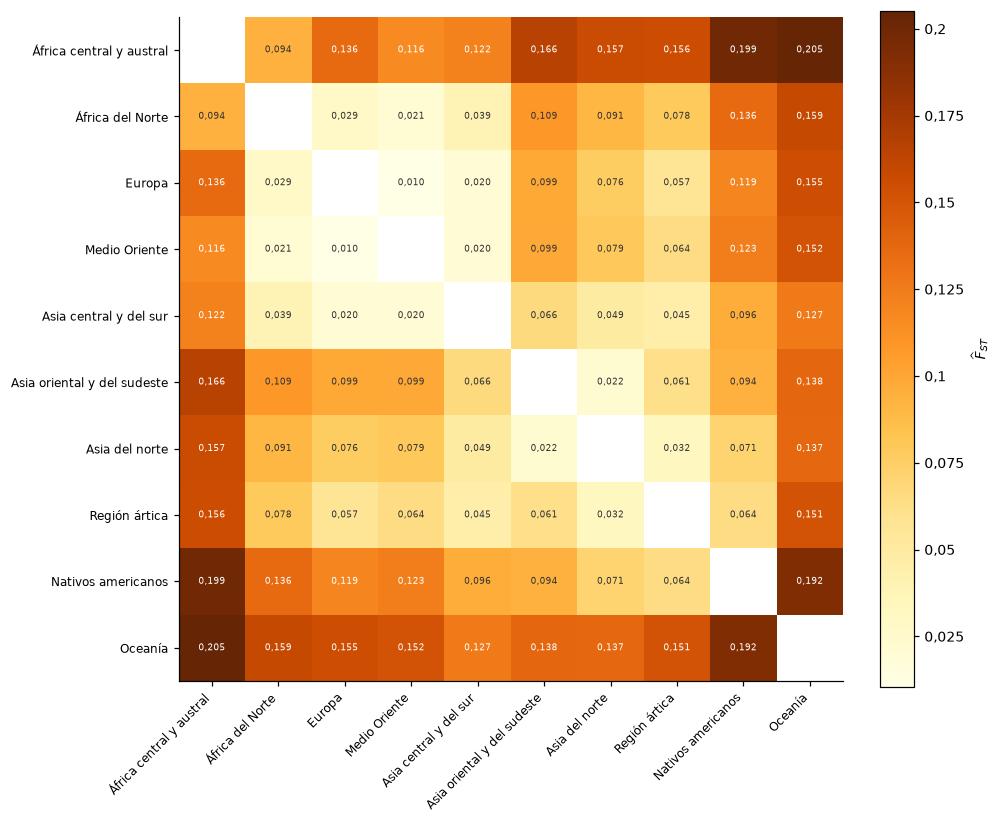

In [17]:
INTRA, GEO_REF = geometria(D_euc[:nr, :nr], grupos_ref, reg[:nr])
INTRA["h_por_SNP"] = INTRA.h/p_valid
P_REF, PANEL_FST = hudson(G, grupos_ref, SNP_VALIDO)
region_de = {q: reg[i[0]] for q, i in grupos_ref.items()}
P_REF["region_a"] = P_REF.a.map(region_de)
P_REF["region_b"] = P_REF.b.map(region_de)
tabla(INTRA.sort_values("h"), "P1_dispersiones")
tabla(GEO_REF.merge(P_REF, on=["a", "b"]), "P1_geometria_FST")
tabla(P_REF, "P1_FST_todos_pares")

# Todos los resúmenes usan las poblaciones de referencia (al menos MIN_N individuos).
EXTREMOS = pd.concat([P_REF.nsmallest(5, "FST").assign(extremo="menor"),
                     P_REF.nlargest(5, "FST").assign(extremo="mayor")])
display(tabla(EXTREMOS, "P1_FST_extremos").round(4))
ALPHA_REF = float(P_REF.alpha_FST.min())
par_ref = P_REF.loc[P_REF.alpha_FST.idxmin()]
print(f"Panel común: {PANEL_FST.sum():,} SNPs; {len(grupos_ref)} poblaciones de referencia")
print(f"h máximo/mínimo: {INTRA.h.max()/INTRA.h.min():.4f}")
print(f"α de referencia mínimo: {ALPHA_REF:.4f}, par {par_ref.a}–{par_ref.b}, FST = {par_ref.FST:.4f}")

grupos_region = {r: np.flatnonzero(reg[:nr] == r) for r in ORDEN_REGIONES if r in set(reg[:nr])}
P_REGION, panel_region = hudson(G, grupos_region, PANEL_FST)
assert np.array_equal(PANEL_FST, panel_region)
tabla(P_REGION, "P1_FST_pares_regionales")
regs = list(grupos_region)
M_REG = np.full((len(regs), len(regs)), np.nan)
for fila in P_REGION.itertuples():
    a, b = regs.index(fila.a), regs.index(fila.b)
    M_REG[a, b] = M_REG[b, a] = fila.FST
tabla(pd.DataFrame(M_REG, index=regs, columns=regs).rename_axis("Region").reset_index(),
      "P1_FST_regiones")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(np.ma.masked_invalid(M_REG), cmap="YlOrBr")
ax.set(xticks=range(len(regs)), yticks=range(len(regs)), xticklabels=regs, yticklabels=regs)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
plt.setp(ax.get_yticklabels(), fontsize=8)
for a in range(len(regs)):
    for b in range(len(regs)):
        if np.isfinite(M_REG[a, b]):
            ax.text(b, a, f"{M_REG[a,b]:.3f}".replace(".", ","), ha="center", va="center", fontsize=6,
                    color="white" if M_REG[a,b] > np.nanmax(M_REG)*.55 else "#333333")
barra = fig.colorbar(im, ax=ax, label=r"$\widehat F_{ST}$", fraction=.046)
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: con_coma(round(v, 3))))
fig.tight_layout()
guardar_figura(fig, "P1_fst_regiones")

In [18]:
# Cociente mediano sobre los genotipos y su referencia (citado en 5.3.4)
rho_genotipos = float(GEO_REF.rho.median())
print(f"ρ mediano sobre genotipos: {rho_genotipos:.3f}")
print(f"α* correspondiente: {alpha_estrella(rho_genotipos):.2f}")

ρ mediano sobre genotipos: 0.301
α* correspondiente: 7.28


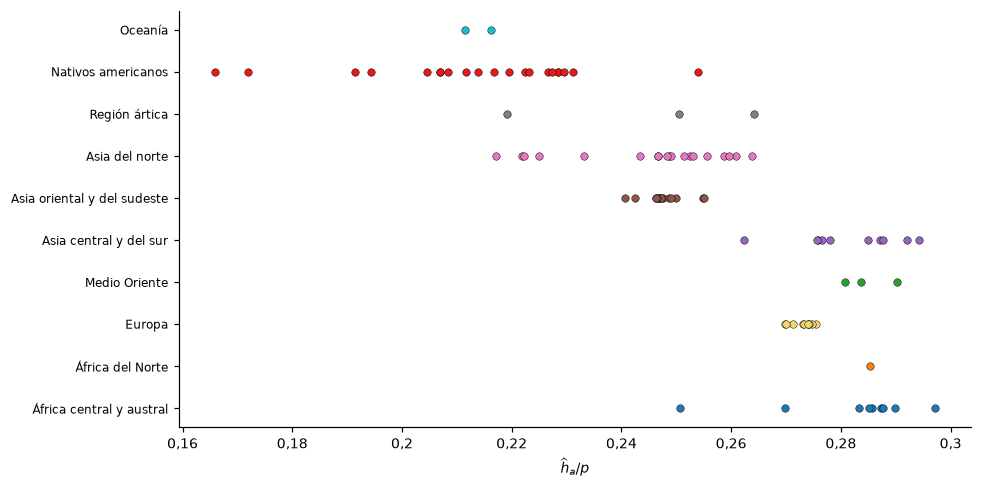

,etiqueta,k,azar_sin_autovecino,maximo_alcanzable
0,poblacion,5,0.0199,1.0
1,region,20,0.1437,1.0


In [19]:
diagnostico_h4 = []
for q, ids in grupos_ref.items():
    total, alejados = 0, 0
    for j in range(0, p, BLOQUE):
        b = np.asarray(G[ids, j:j+BLOQUE], float)
        ok = np.isfinite(b) & (b >= 0)
        cnt = ok.sum(0)
        f = np.divide(np.where(ok, b, 0).sum(0), 2*cnt,
                      out=np.zeros(b.shape[1]), where=cnt > 0)
        v = PANEL_FST[j:j+b.shape[1]]
        total += int(v.sum())
        alejados += int(((f > MIN_MAF) & (f < 1-MIN_MAF) & v).sum())
    diagnostico_h4.append({"poblacion": q, "snps": total,
        "fraccion_frecuencias_entre_eps_y_1_menos_eps": alejados/total, "epsilon": MIN_MAF})
tabla(pd.DataFrame(diagnostico_h4), "P1_diagnostico_H4")

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, r in enumerate(ORDEN_REGIONES):
    sel = INTRA.region.eq(r)
    ax.scatter(INTRA.loc[sel, "h_por_SNP"], np.full(sel.sum(), k),
               c=COLORES[r], s=24, edgecolors="black", linewidths=.3)
ax.set(yticks=range(len(ORDEN_REGIONES)), yticklabels=ORDEN_REGIONES,
       xlabel=r"$\widehat h_a/p$")
ax.tick_params(axis="y", labelsize=8)
# Coma decimal sólo en el eje horizontal; el vertical lleva los nombres de las regiones.
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: con_coma(round(v, 10))))
fig.tight_layout()
guardar_figura(fig, "P1_dispersiones")

CTX_REF = contexto_metricas(D_euc[:nr, :nr], nr, pob[:nr], reg[:nr], P_REF)
referencias_nn = []
for nombre, etiquetas, k in [("poblacion", pob[:nr], K_POB), ("region", reg[:nr], K_REG)]:
    conteos = pd.Series(etiquetas).value_counts()
    azar = float(np.sum(conteos*(conteos-1))/(nr*(nr-1)))
    techo = float(np.mean(np.minimum(conteos[etiquetas].to_numpy()-1, k)/k))
    referencias_nn.append({"etiqueta": nombre, "k": k, "azar_sin_autovecino": azar,
                           "maximo_alcanzable": techo})
display(tabla(pd.DataFrame(referencias_nn), "P1_referencias_QNN").round(4))

### Subconjunto más próximo a las hipótesis

Se seleccionan poblaciones de variabilidad semejante y se retiran pares con similitud extrema. Se conservan la tabla de selección, el análisis de sensibilidad del umbral y la comparación de atajos con el conjunto completo (Sección 5.3.1; Apéndice B.3).

In [20]:
candidatas = INTRA[INTRA.n >= MIN_N_SUB].copy()
med_h = float(candidatas.h.median())
candidatas["desvio_pct"] = 100*(candidatas.h/med_h-1)
seleccion = (candidatas[candidatas.desvio_pct.abs() <= 100*BANDA_H]
             .assign(distancia=lambda t: t.desvio_pct.abs())
             .sort_values(["distancia", "poblacion"], kind="stable")
             .groupby("region", sort=False).head(POR_REGION))
if seleccion.empty:
    raise ValueError("Ninguna población entra en la banda de h; revisar datos y parámetros")
tabla(seleccion, "S1_poblaciones_seleccionadas")
idx_sel = np.sort(np.concatenate([grupos_ref[q] for q in seleccion.poblacion]))
A = D_euc[np.ix_(idx_sel, idx_sel)]**2
B = -.5*(A-A.mean(0)[None, :]-A.mean(1)[:, None]+A.mean())
normas = np.sqrt(np.maximum(np.diag(B), 0))
den = np.outer(normas, normas)
COS = np.divide(B, den, out=np.zeros_like(B), where=den > 0)
i_s, j_s = np.triu_indices(len(idx_sel), 1)
mismo_s = pob[idx_sel[i_s]] == pob[idx_sel[j_s]]
cos_dentro = COS[i_s[mismo_s], j_s[mismo_s]]
umbral = float(np.quantile(cos_dentro, Q_COSENO)) if UMBRAL_COSENO is None else UMBRAL_COSENO

def retirar_similitudes(cos, poblaciones, corte):
    enlaces = (cos > corte) & (poblaciones[:, None] == poblaciones[None, :])
    np.fill_diagonal(enlaces, False)
    fuera = []
    while enlaces.any():
        k = int(enlaces.sum(1).argmax())
        fuera.append(k)
        enlaces[k, :] = False
        enlaces[:, k] = False
    return np.asarray(fuera, int)

sensibilidad = []
for cuantil in (.95, .99, .995, .999, 1.):
    u = float(np.quantile(cos_dentro, cuantil))
    fuera = retirar_similitudes(COS, pob[idx_sel], u)
    resto = np.setdiff1d(np.arange(len(idx_sel)), fuera)
    tamanos_s = pd.Series(pob[idx_sel[resto]]).value_counts()
    sensibilidad.append({"cuantil": cuantil, "umbral": u, "retirados": len(fuera),
                         "poblaciones_n10": int((tamanos_s >= MIN_N_SUB).sum())})
tabla(pd.DataFrame(sensibilidad), "S2_sensibilidad_coseno")
fuera_cos = retirar_similitudes(COS, pob[idx_sel], umbral)
idx_tras_cos = np.delete(idx_sel, fuera_cos)
cuentas = pd.Series(pob[idx_tras_cos]).value_counts()
IDX_SUB = idx_tras_cos[np.isin(pob[idx_tras_cos], cuentas[cuentas >= MIN_N_SUB].index)]
if len(np.unique(pob[IDX_SUB])) < 2:
    raise ValueError("El subconjunto debe tener al menos dos poblaciones")
auditoria_sub = et.iloc[idx_sel].copy()
auditoria_sub["retirado_coseno"] = np.isin(idx_sel, idx_sel[fuera_cos])
auditoria_sub["incluido_final"] = np.isin(idx_sel, IDX_SUB)
auditoria_sub["umbral_coseno"] = umbral
tabla(auditoria_sub, "S2_seleccion_individuos")
GRUPOS_SUB = {q: np.flatnonzero(pob[IDX_SUB] == q) for q in np.unique(pob[IDX_SUB])}
M_SUB_EUC = D_euc[np.ix_(IDX_SUB, IDX_SUB)]
M_SUB, escala_sub = normalizar(M_SUB_EUC, len(IDX_SUB))
ESPACIO_SUB = definir_espacio(M_SUB, "Subconjunto")
H_SUB, GEO_SUB = geometria(M_SUB_EUC, GRUPOS_SUB, reg[IDX_SUB])
grupos_globales_sub = {q: IDX_SUB[i] for q, i in GRUPOS_SUB.items()}
P_SUB, PANEL_SUB = hudson(G, grupos_globales_sub, SNP_VALIDO)
tabla(H_SUB, "S3_dispersiones")
tabla(GEO_SUB.merge(P_SUB, on=["a", "b"]), "S3_geometria_FST")
ALPHA_SUB = float(P_SUB.alpha_FST.min())
RES_SUB = pd.DataFrame([{"individuos": len(IDX_SUB), "poblaciones": len(GRUPOS_SUB),
    "regiones": len(set(reg[IDX_SUB])), "razon_h_candidatas": candidatas.h.max()/candidatas.h.min(),
    "razon_h_final": H_SUB.h.max()/H_SUB.h.min(), "alpha_ref_min": ALPHA_SUB,
    "snps_Hudson": int(PANEL_SUB.sum()), "umbral_coseno": umbral}])
display(tabla(RES_SUB, "S3_resumen").round(4))

,individuos,poblaciones,regiones,razon_h_candidatas,razon_h_final,alpha_ref_min,snps_Hudson,umbral_coseno
0,281,15,6,1.7918,1.2067,4.1884,149257,0.4578


In [21]:
# Composición final del subconjunto, por población
display(pd.Series(pob[IDX_SUB]).value_counts().rename_axis("poblacion").rename("individuos")
        .to_frame().assign(region=lambda t: [reg[IDX_SUB][pob[IDX_SUB] == q][0] for q in t.index]))

,individuos,region
poblacion,,
Maya1,37,Nativos americanos
Yakut,34,Asia del norte
Sardinian,28,Europa
Basque,24,Europa
Kalash,23,Asia central y del sur
BiakaPygmy,21,África central y austral
Buryat,17,Asia del norte
Orcadian,15,Europa
Evenki,15,Asia del norte


In [22]:
# Diagnóstico del subconjunto: números del anexo (selección, filtro de parentesco y sensibilidad)
print(f"Individuos de las poblaciones seleccionadas, antes del filtro: {len(idx_sel)}")
print(f"Umbral del filtro (cuantil {Q_COSENO}): {umbral:.4f}")
print(f"Individuos eliminados: {len(fuera_cos)}")
print(f"Subconjunto final: {len(IDX_SUB)} individuos, {len(GRUPOS_SUB)} poblaciones, "
      f"{len(set(reg[IDX_SUB]))} regiones")
print(f"Mediana del coseno dentro de una población: {np.median(cos_dentro):.3f}")
print(f"Mediana del coseno entre poblaciones: {np.median(COS[i_s[~mismo_s], j_s[~mismo_s]]):.3f}")
print(f"Cociente máximo/mínimo de h en el subconjunto: {H_SUB.h.max()/H_SUB.h.min():.4f}")
print(f"h/p en el subconjunto: de {(H_SUB.h/p_valid).min():.3f} a {(H_SUB.h/p_valid).max():.3f}")

print("\nTabla de selección:")
tabla_sel = seleccion.copy()
tabla_sel["h_por_SNP"] = tabla_sel.h/p_valid
display(tabla_sel[["poblacion", "region", "n", "h_por_SNP", "desvio_pct"]].round(4))
print(f"Mediana de h/p entre las candidatas: {med_h/p_valid:.4f}")

print("\nIndividuos por población, antes y después del filtro:")
antes = pd.Series(pob[idx_sel]).value_counts()
despues = pd.Series(pob[idx_tras_cos]).value_counts()
display(pd.DataFrame({"antes": antes, "despues": despues}).fillna(0).astype(int))

print("\nSensibilidad al cuantil:")
display(pd.DataFrame(sensibilidad).round(4))

Individuos de las poblaciones seleccionadas, antes del filtro: 295
Umbral del filtro (cuantil 0.995): 0.4578
Individuos eliminados: 7
Subconjunto final: 281 individuos, 15 poblaciones, 6 regiones
Mediana del coseno dentro de una población: 0.150
Mediana del coseno entre poblaciones: -0.032
Cociente máximo/mínimo de h en el subconjunto: 1.2067
h/p en el subconjunto: de 0.228 a 0.276

Tabla de selección:


,poblacion,region,n,h_por_SNP,desvio_pct
50,MbutiPygmy,África central y austral,13,0.2507,0.0000
79,Tujia,Asia oriental y del sudeste,10,0.2499,-0.3291
88,Yi,Asia oriental y del sudeste,10,0.2490,-0.6744
13,Buryat,Asia del norte,17,0.2525,0.7156
32,Han-NChina,Asia oriental y del sudeste,10,0.2487,-0.7973
87,Yakut,Asia del norte,34,0.2484,-0.9285
26,Evenki,Asia del norte,15,0.2466,-1.6374
39,Kalash,Asia central y del sur,23,0.2624,4.6640
10,BiakaPygmy,África central y austral,21,0.2697,7.5932
8,Basque,Europa,24,0.2698,7.6122


Mediana de h/p entre las candidatas: 0.2507

Individuos por población, antes y después del filtro:


,antes,despues
Basque,24,24
BiakaPygmy,21,21
Buryat,17,17
Chipewyan,15,14
Evenki,15,15
Han-NChina,10,10
Kalash,23,23
Kaqchikel,13,13
Maya1,37,37
MbutiPygmy,13,7



Sensibilidad al cuantil:


,cuantil,umbral,retirados,poblaciones_n10
0,0.950,0.3905,26,14
1,0.990,0.4525,9,15
2,0.995,0.4578,7,15
3,0.999,0.4722,4,16
4,1.000,0.5900,0,16


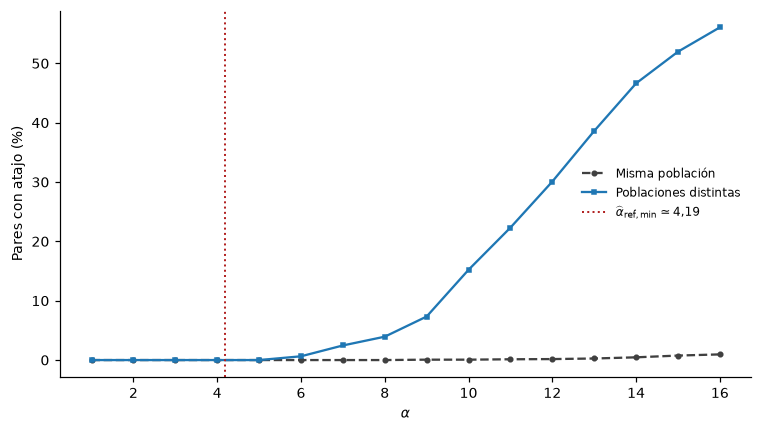

,tipo,primera_deteccion_grillas_evaluadas,alpha_ref_min
0,intra,8.4,4.188431
1,inter,5.6,4.188431


,alpha,metodo,Q_NN_pob,Q_NN_reg,Q_FST
0,1.0,MDS,0.736,0.971,0.894
1,1.0,DM,0.738,0.971,0.894
2,2.0,MDS,0.736,0.971,0.894
3,2.0,DM,0.738,0.971,0.894
4,3.0,MDS,0.736,0.971,0.894
5,3.0,DM,0.738,0.971,0.894
6,4.0,MDS,0.736,0.971,0.894
7,4.0,DM,0.738,0.971,0.894
8,5.0,MDS,0.736,0.971,0.894
9,5.0,DM,0.738,0.971,0.894


In [23]:
CURVAS_SUB = resumen_atajos(ESPACIO_SUB, pob[IDX_SUB], ALPHAS_SUB, "S4_curvas")
FINO_SUB = resumen_atajos(ESPACIO_SUB, pob[IDX_SUB], ALPHAS_SUB_FINO, "S4_fino")
curva_atajos(CURVAS_SUB, ALPHA_SUB, "S4_curvas", "Atajos en el subconjunto")
detecciones_sub = []
unidos_sub = pd.concat([CURVAS_SUB, FINO_SUB]).drop_duplicates("alpha").sort_values("alpha")
for tipo in ("intra", "inter"):
    hay = unidos_sub[unidos_sub[f"{tipo}_pct"] > 0]
    primero = float(hay.alpha.min()) if len(hay) else np.nan
    detecciones_sub.append({"tipo": tipo, "primera_deteccion_grillas_evaluadas": primero,
                           "alpha_ref_min": ALPHA_SUB})
display(tabla(pd.DataFrame(detecciones_sub), "S4_primeras_detecciones"))

# Apéndice B.3: representaciones del subconjunto (Q_NN y Q_FST).
# Grilla indicada en la tesis: enteros de 1 a 5 y pasos de 0,5 entre 5,5 y 12.
ALPHAS_SUB_MAPAS = tuple(np.r_[np.arange(1., 6.), np.arange(5.5, 12.01, .5)])
CTX_SUB = contexto_metricas(M_SUB_EUC, len(IDX_SUB), pob[IDX_SUB], reg[IDX_SUB], P_SUB)
ruta_sub = TABLAS/"S5_metricas_subconjunto.csv"
if ruta_sub.exists():
    MET_SUB = pd.read_csv(ruta_sub)
else:
    filas_sub = []
    for alpha in ALPHAS_SUB_MAPAS:
        for metodo, Z in mapas_fermat(ESPACIO_SUB, float(alpha)).items():
            filas_sub.append({"alpha": float(alpha), "metodo": metodo,
                              **evaluar_mapa(Z, CTX_SUB)})
        tabla(pd.DataFrame(filas_sub), "S5_metricas_subconjunto")
    MET_SUB = pd.DataFrame(filas_sub)
display(MET_SUB[MET_SUB.alpha.isin([1., 2., 3., 4., 5., 8., 12.])].round(3))

## 4. Atajos en el conjunto completo

Se calcula la proporción de pares con atajo según el tipo de recorrido, se localizan las primeras apariciones y se sigue el camino de un par MbutiPygmy–Surui (Sección 5.3.2). El seguimiento hasta exponentes mayores se conserva para el Apéndice C.2.

,alpha,misma_poblacion_pct,intermediarios_extremos_pct,tercera_poblacion_pct
4,5.0,0.06,0.12,0.03
5,6.0,0.18,1.02,2.31
9,10.0,0.95,3.85,28.47
15,16.0,2.46,5.62,60.20
19,20.0,3.58,5.27,69.93
31,32.0,8.84,5.51,80.79


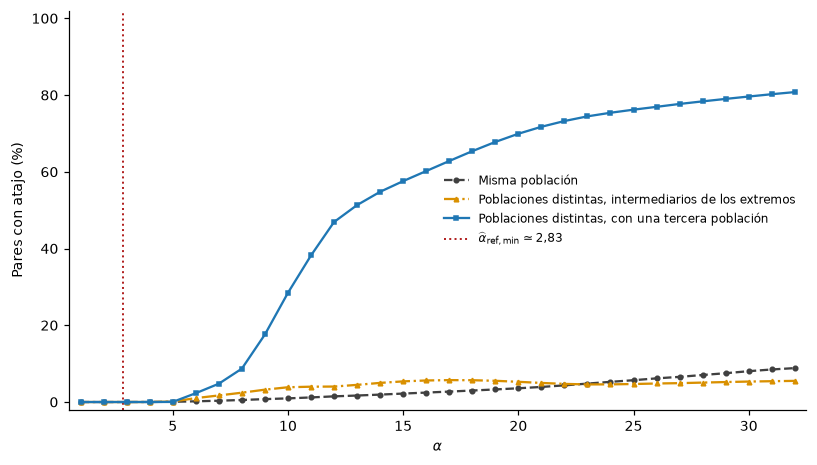

In [24]:
ruta_tipos = TABLAS/"P2_curvas_tipos.csv"
if ruta_tipos.exists():
    CURVAS_TIPOS = pd.read_csv(ruta_tipos)
else:
    cpob = pd.factorize(pob[:nr])[0].astype(np.int64)
    filas = []
    for alpha in ALPHAS_REF:
        F, PR = fermat(ESPACIO_REF, alpha, pred=True, guardar=False)
        costos = ESPACIO_REF["M"]**alpha
        intra, extremos, tercera, n_intra, n_inter = contar_atajos_por_tipo(
            np.asarray(F, dtype=np.float64), np.asarray(PR, dtype=np.int64), costos, cpob, TOL)
        filas.append({"alpha": alpha,
                      "misma_poblacion_pct": 100*intra/n_intra,
                      "intermediarios_extremos_pct": 100*extremos/n_inter,
                      "tercera_poblacion_pct": 100*tercera/n_inter})
        print(f"α = {alpha:g}: listo", flush=True)
        del F, PR, costos
    CURVAS_TIPOS = tabla(pd.DataFrame(filas), "P2_curvas_tipos")
display(CURVAS_TIPOS[CURVAS_TIPOS.alpha.isin([5, 6, 10, 16, 20, 32])].round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(CURVAS_TIPOS.alpha, CURVAS_TIPOS.misma_poblacion_pct, ls="--", marker="o", ms=3,
        color="0.25", label="Misma población", clip_on=False, zorder=3)
ax.plot(CURVAS_TIPOS.alpha, CURVAS_TIPOS.intermediarios_extremos_pct, ls="-.", marker="^", ms=3,
        color="#D99000", label="Poblaciones distintas, intermediarios de los extremos",
        clip_on=False, zorder=3)
ax.plot(CURVAS_TIPOS.alpha, CURVAS_TIPOS.tercera_poblacion_pct, ls="-", marker="s", ms=3,
        color="#1f77b4", label="Poblaciones distintas, con una tercera población",
        clip_on=False, zorder=3)
ax.axvline(ALPHA_REF, color="firebrick", ls=":", lw=1.3,
           label=r"$\widehat\alpha_{\mathrm{ref},\min}\simeq"
                 + f"{ALPHA_REF:.2f}".replace(".", "{,}") + "$")
ax.set(xlabel=r"$\alpha$", ylabel="Pares con atajo (%)", xlim=(.5, 32.5), ylim=(-2, 102))
coma(ax)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
guardar_figura(fig, "P2_curvas_tipos")

In [25]:
def primera_existencia(espacio, poblaciones=None, solo_inter=False):
    # Primer índice de la grilla con algún atajo (propiedad monótona).
    i, j = np.triu_indices(len(espacio["M"]), 1)
    if solo_inter:
        mascara = poblaciones[i] != poblaciones[j]
        i, j = i[mascara], j[mascara]
    ruta = CACHE/f"inicio_{espacio['clave']}_inter{solo_inter}.json"
    if ruta.exists():
        return json.loads(ruta.read_text())["tick"]
    evaluados = {}
    def existe(tick):
        if tick not in evaluados:
            alpha = round(tick*PASO_PRIMEROS, 8)
            F, _ = fermat(espacio, alpha, guardar=False)
            evaluados[tick] = bool((cociente(F[i, j], espacio["M"][i, j]**alpha) < 1-TOL).any())
        return evaluados[tick]
    lo = int(round(1/PASO_PRIMEROS))
    hi = int(round(MAX_ALPHA_PRIMEROS/PASO_PRIMEROS))
    if not existe(hi):
        resultado = None
    else:
        while hi-lo > 1:
            medio = (lo+hi)//2
            if existe(medio):
                hi = medio
            else:
                lo = medio
        resultado = hi
    escribir_json({"tick": resultado, "evaluaciones": evaluados}, ruta)
    return resultado

@njit
def testigos_tipos(F, PR, costo, cpob, creg, capacidades, tolerancia):
    # Hasta N pares por tipo; revisa todos si el tipo todavía no aparece.
    m = len(F)
    ejemplos = np.full((5, max(1, capacidades.max()), 2), -1, dtype=np.int64)
    cuentas = np.zeros(5, dtype=np.int64)
    marca_p = np.zeros(cpob.max()+1, dtype=np.int64)
    marca_r = np.zeros(creg.max()+1, dtype=np.int64)
    sello = 0
    for i in range(m):
        for j in range(i+1, m):
            if costo[i, j] <= 0 or F[i, j] >= (1-tolerancia)*costo[i, j]:
                continue
            sello += 1
            k, npob, nreg, pasos = j, 0, 0, 0
            while True:
                if marca_p[cpob[k]] != sello:
                    marca_p[cpob[k]] = sello
                    npob += 1
                if marca_r[creg[k]] != sello:
                    marca_r[creg[k]] = sello
                    nreg += 1
                if k == i:
                    break
                k = PR[i, k]
                pasos += 1
                if k < 0 or pasos > m:
                    raise ValueError("Predecesores inválidos")
            condiciones = (cpob[i] == cpob[j], cpob[i] != cpob[j] and npob == 2,
                           npob >= 3, nreg >= 3, nreg >= 4)
            for tipo in range(5):
                if condiciones[tipo] and cuentas[tipo] < capacidades[tipo]:
                    ejemplos[tipo, cuentas[tipo], 0] = i
                    ejemplos[tipo, cuentas[tipo], 1] = j
                    cuentas[tipo] += 1
            if np.all(cuentas >= capacidades):
                return ejemplos, cuentas
    return ejemplos, cuentas

TIPOS = ["Misma población", "Dos poblaciones, intermediarios de ambas",
         "Al menos tres poblaciones", "Al menos tres regiones", "Al menos cuatro regiones"]

def primeras_detecciones(espacio, poblaciones, regiones):
    archivo = CACHE/f"primeros_{espacio['clave']}.json"
    estado = json.loads(archivo.read_text()) if archivo.exists() else {
        "registros": [], "completo": False, "siguiente_tick": None}
    if not estado["completo"]:
        inicio = estado["siguiente_tick"]
        if inicio is None:
            inicio = primera_existencia(espacio)
        if inicio is not None:
            cpob = pd.factorize(poblaciones, sort=True)[0]
            creg = pd.factorize(regiones, sort=True)[0]
            ultimo = int(round(MAX_ALPHA_PRIMEROS/PASO_PRIMEROS))
            for tick in range(inicio, ultimo+1):
                alpha = round(tick*PASO_PRIMEROS, 8)
                vistos = {r["tipo"] for r in estado["registros"]}
                capacidades = np.array([0 if t in vistos else N_PRIMEROS for t in TIPOS])
                if not capacidades.any():
                    break
                F, PR = fermat(espacio, alpha, pred=True, guardar=False)
                ejemplos, cantidades = testigos_tipos(F, PR, costos_fermat(espacio["M"], alpha),
                                                       cpob, creg, capacidades, TOL)
                for t, cantidad in enumerate(cantidades):
                    for k in range(cantidad):
                        i, j = ejemplos[t, k]
                        recorrido = camino(PR, int(i), int(j))
                        estado["registros"].append({"tipo": TIPOS[t], "alpha": alpha,
                            "i": int(i), "j": int(j), "ruta": recorrido,
                            "poblaciones": " → ".join(poblaciones[recorrido]),
                            "regiones": " → ".join(regiones[recorrido]),
                            "aristas": len(recorrido)-1})
                estado["siguiente_tick"] = tick+1
                escribir_json(estado, archivo)
        estado["completo"] = True
        escribir_json(estado, archivo)
    registros = pd.DataFrame(estado["registros"])
    if registros.empty:
        return pd.DataFrame(columns=["tipo", "alpha", "i", "j", "ruta"])
    return registros

In [26]:
PRIMEROS = pd.DataFrame()
if CALCULAR_PRIMEROS:
    PRIMEROS = primeras_detecciones(ESPACIO_REF, pob[:nr], reg[:nr])
    if not PRIMEROS.empty:
        exportar = PRIMEROS.copy()
        exportar["IID_i"] = et.IID.to_numpy()[exportar.i]
        exportar["IID_j"] = et.IID.to_numpy()[exportar.j]
        exportar["ruta"] = exportar.ruta.map(json.dumps)
        tabla(exportar, "P2_primeros_pares")
        display(tabla(PRIMEROS.drop(columns="ruta").groupby("tipo", sort=False).first()
                      .reset_index(), "P2_primeras_apariciones"))
    no_detectados = set(TIPOS) - set(PRIMEROS.get("tipo", []))
    if no_detectados:
        print("Sin detección hasta el máximo configurado:", sorted(no_detectados))
else:
    print("Tabla de primeras apariciones omitida por configuración.")

,tipo,alpha,i,j,poblaciones,regiones,aristas
0,Misma población,3.10,770,1903,Surui → Surui → Surui,Nativos americanos → Nativos americanos → Nati...,2
1,"Dos poblaciones, intermediarios de ambas",4.46,52,1900,MbutiPygmy → Surui → Surui,África central y austral → Nativos americanos ...,2
2,Al menos tres poblaciones,4.82,70,1905,BiakaPygmy → Wayuu → Surui,África central y austral → Nativos americanos ...,2
3,Al menos tres regiones,6.29,204,1969,MbutiPygmy → Wayuu → EastGreenland,África central y austral → Nativos americanos ...,2
4,Al menos cuatro regiones,14.21,138,674,BantuKenya → Palestinian → Hazara → Melanesian,África central y austral → Medio Oriente → Asi...,3


Genotipos · referencias · α=4.46 · 3.0 s
Par fijo: [{'IID': '74_HGDP00450', 'label': 'MbutiPygmy'}, {'IID': '2078_4256126341_A', 'label': 'Surui'}]


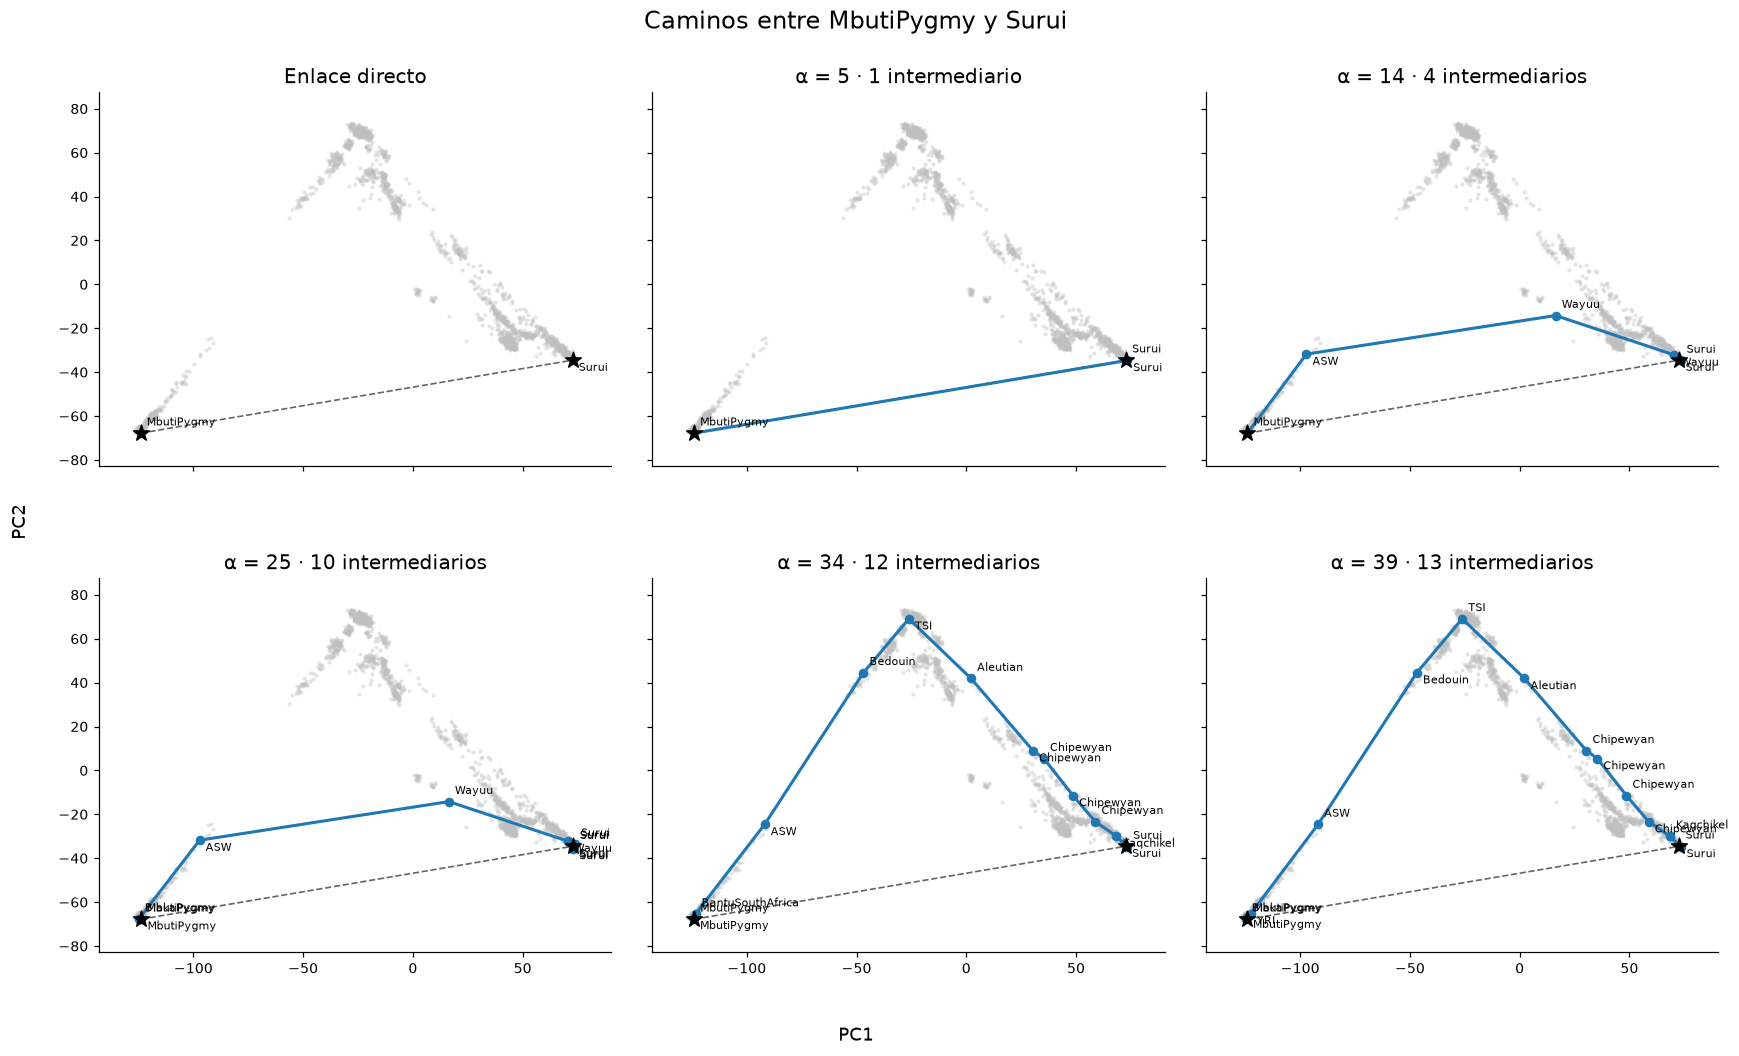

In [27]:
# Par fijo y evolución de los recorridos (Figura 5.10 y Apéndice C.2)
REGISTRO_RUTAS = []
tick_inter = primera_existencia(ESPACIO_REF, pob[:nr], solo_inter=True)
if tick_inter is None:
    raise RuntimeError("No se encontró ningún atajo entre poblaciones en la grilla evaluada")

alpha_inter = round(tick_inter * PASO_PRIMEROS, 8)
F_inicio, PR_inicio = fermat(ESPACIO_REF, alpha_inter, pred=True, guardar=False)
ii, jj = np.triu_indices(nr, 1)
es_atajo = (pob[ii] != pob[jj]) & (
    cociente(F_inicio[ii, jj], D_ref[ii, jj]**alpha_inter) < 1-TOL)
candidatos = np.flatnonzero(es_atajo)
pares_de_interes = [k for k in candidatos if
                    {pob[ii[k]], pob[jj[k]]} == {"MbutiPygmy", "Surui"}]
if not pares_de_interes:
    raise RuntimeError("El primer atajo no corresponde al par MbutiPygmy–Surui de la tesis")
k = int(pares_de_interes[0])
EXTREMOS_RUTA = (int(ii[k]), int(jj[k]))
print("Par fijo:", et.iloc[list(EXTREMOS_RUTA)][["IID", "label"]].to_dict("records"))

for alpha in ALPHAS_RUTA:
    ruta, costo, directo = camino_un_par(ESPACIO_REF, alpha, *EXTREMOS_RUTA)
    REGISTRO_RUTAS.append({"alpha": alpha, "ruta": ruta,
                           "costo": costo, "costo_directo": directo,
                           "cociente": costo/directo, "poblaciones": " → ".join(pob[ruta]),
                           "aristas": len(ruta)-1})
tabla(pd.DataFrame([{**r, "ruta": json.dumps(r["ruta"])} for r in REGISTRO_RUTAS]),
      "P2_recorridos_par_fijo")

# Figura 5.10: paneles FIJOS de la tesis (no los primeros cambios automáticos).
# El registro completo de rutas para 2 <= alpha <= 40 se conserva arriba.
ALPHAS_FIGURA_CAMINOS = (5., 14., 25., 34., 39.)
rutas_figura = {float(r["alpha"]): r["ruta"] for r in REGISTRO_RUTAS}
for alpha in ALPHAS_FIGURA_CAMINOS:
    if alpha not in rutas_figura:
        rutas_figura[alpha] = camino_un_par(ESPACIO_REF, alpha, *EXTREMOS_RUTA)[0]

# PCA sin estandarizar de las referencias: sólo para dibujar los caminos.
# Se usa X_PC_REF para no depender de que la variable R haya sido reutilizada.
Z_caminos = X_PC_REF[:nr, :2].copy()
idx_mbuti = next(i for i in EXTREMOS_RUTA if pob[i] == "MbutiPygmy")
idx_surui = next(i for i in EXTREMOS_RUTA if pob[i] == "Surui")
if Z_caminos[idx_mbuti, 0] > Z_caminos[idx_surui, 0]:
    Z_caminos[:, 0] *= -1  # África a la izquierda, como en la figura de la tesis.


def dibujar_panel_ruta_tesis(ax, ruta, titulo):
    ruta = list(ruta)
    ax.scatter(Z_caminos[:, 0], Z_caminos[:, 1], s=7, c="0.75",
               alpha=.42, linewidths=0, zorder=1, rasterized=True)
    a, b = ruta[0], ruta[-1]
    ax.plot(Z_caminos[[a, b], 0], Z_caminos[[a, b], 1],
            color="0.40", ls="--", lw=1.1, zorder=2)
    if len(ruta) > 2:
        ax.plot(Z_caminos[ruta, 0], Z_caminos[ruta, 1],
                color="#1f77b4", lw=2, zorder=3)
        ax.scatter(Z_caminos[ruta[1:-1], 0], Z_caminos[ruta[1:-1], 1],
                   s=28, c="#1f77b4", zorder=4)
    ax.scatter(Z_caminos[[a, b], 0], Z_caminos[[a, b], 1],
               marker="*", s=115, c="black", zorder=5)
    for k, v in enumerate(ruta):
        ax.annotate(str(pob[v]), Z_caminos[v, :2],
                    xytext=(4, 5 if k % 2 == 0 else -7),
                    textcoords="offset points", fontsize=7.5, zorder=6)
    ax.set_title(titulo, fontsize=13)
    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig, axes = plt.subplots(2, 3, figsize=(16, 9.7), squeeze=False)
dibujar_panel_ruta_tesis(axes[0, 0], list(EXTREMOS_RUTA), "Enlace directo")
for ax, alpha in zip(axes.flat[1:], ALPHAS_FIGURA_CAMINOS):
    ruta = rutas_figura[alpha]
    n_inter = len(ruta) - 2
    nombre_inter = "intermediario" if n_inter == 1 else "intermediarios"
    dibujar_panel_ruta_tesis(
        ax, ruta, f"α = {alpha:g} · {n_inter} {nombre_inter}")

# Los seis paneles tienen los mismos límites, sin compartir ejes incompatibles.
m_x = .08 * np.ptp(Z_caminos[:, 0])
m_y = .10 * np.ptp(Z_caminos[:, 1])
for fila, ejes_fila in enumerate(axes):
    for columna, ax in enumerate(ejes_fila):
        ax.set_xlim(Z_caminos[:, 0].min() - m_x, Z_caminos[:, 0].max() + m_x)
        ax.set_ylim(Z_caminos[:, 1].min() - m_y, Z_caminos[:, 1].max() + m_y)
        if columna > 0:
            ax.tick_params(labelleft=False)
        if fila == 0:
            ax.tick_params(labelbottom=False)

fig.suptitle("Caminos entre MbutiPygmy y Surui", fontsize=16, y=.98)
fig.supxlabel("PC1", fontsize=12)
fig.supylabel("PC2", fontsize=12)
fig.subplots_adjust(left=.07, right=.99, bottom=.09, top=.91,
                    wspace=.08, hspace=.25)
guardar_figura(fig, "P2_caminos_PCA_paneles")


## 5. Representaciones sobre los genotipos

Se utilizan PCA y UMAP como controles, y se construyen mapas MDS y de difusión con las distancias euclídea y de Fermat. Se muestran los exponentes $5,15,20,30$ y las métricas sobre la grilla $1,\ldots,32$ (Sección 5.3.3).

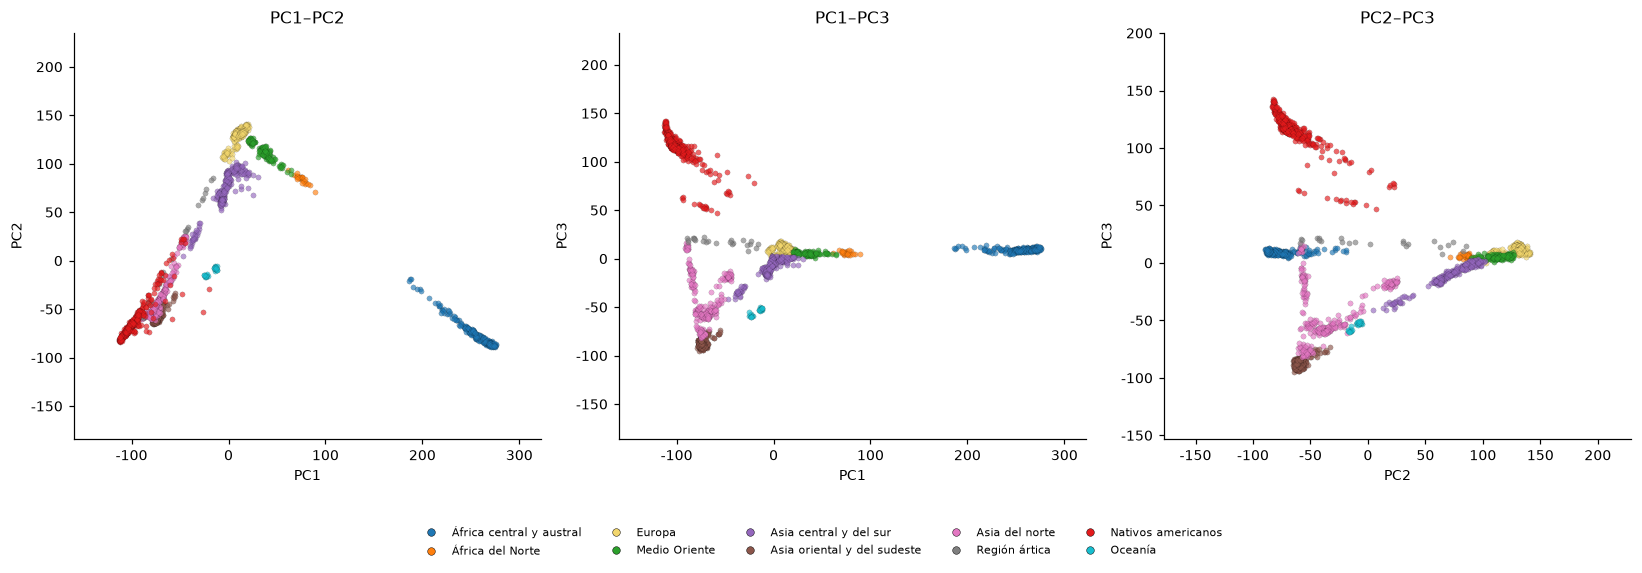

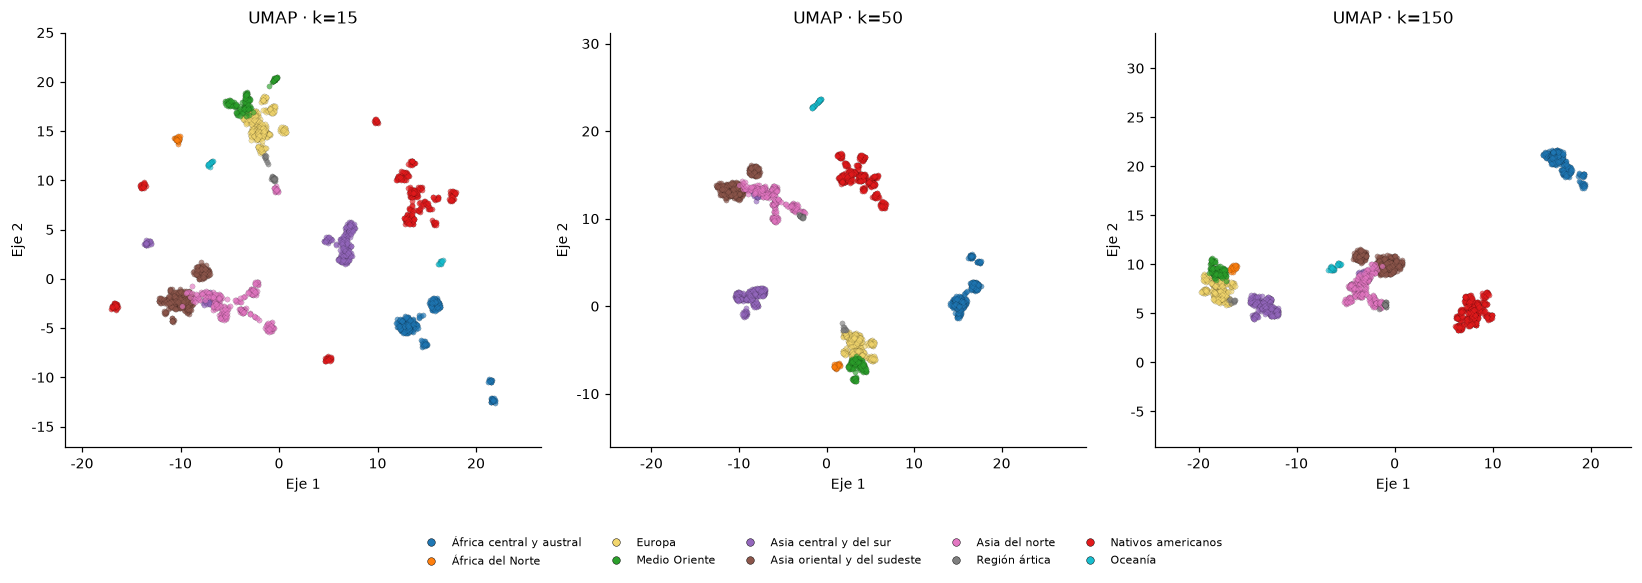

,representacion,Q_NN_pob,Q_NN_reg,Q_FST
0,PCA · PC1–PC2,0.4908,0.9437,0.6770
1,UMAP · k=15,0.7201,0.9672,0.5501
2,UMAP · k=50,0.6707,0.9682,0.6434
3,UMAP · k=150,0.6443,0.9661,0.7127


In [28]:
MAPAS_CONTROL = {"PCA · PC1–PC2": X_PC_EST[R, :2]}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (a, b) in zip(axes, ((0, 1), (0, 2), (1, 2))):
    nube(ax, X_PC_EST[R][:, [a, b]], reg[:nr], f"PC{a+1}–PC{b+1}",
          ejes=(f"PC{a+1}", f"PC{b+1}"))
leyenda_regiones(fig, reg[:nr])
guardar_figura(fig, "P3_pca")
for k in N_VEC_UMAP:
    MAPAS_CONTROL[f"UMAP · k={k}"] = mapa_umap(ESPACIO_REF, k)
galeria({k: v for k, v in MAPAS_CONTROL.items() if k.startswith("UMAP")}, reg[:nr], "P3_umap")
CONTROL_REF = pd.DataFrame([{"representacion": nombre, **evaluar_mapa(Z, CTX_REF)}
                           for nombre, Z in MAPAS_CONTROL.items()])
display(tabla(CONTROL_REF, "P4_controles").round(4))

def barrer_mapas(espacio, alphas, contexto, archivo, nombre_espacio):
    ruta = TABLAS/f"{archivo}.csv"
    registros = pd.read_csv(ruta).to_dict("records") if ruta.exists() else []
    listos = {(str(r["metodo"]), round(float(r["alpha"]), 8)) for r in registros}
    for alpha in alphas:
        if all((m, round(float(alpha), 8)) in listos for m in ("MDS", "DM")):
            continue
        mapas = mapas_fermat(espacio, alpha)
        for metodo, Z in mapas.items():
            if (metodo, round(float(alpha), 8)) not in listos:
                registros.append({"espacio": nombre_espacio, "alpha": alpha, "metodo": metodo,
                                   **evaluar_mapa(Z, contexto)})
        tabla(pd.DataFrame(registros), archivo)
    return pd.DataFrame(registros).sort_values(["metodo", "alpha"]).reset_index(drop=True)

MET_REF = barrer_mapas(ESPACIO_REF, ALPHAS_REF, CTX_REF, "P4_barrido_alpha", "Genotipos")

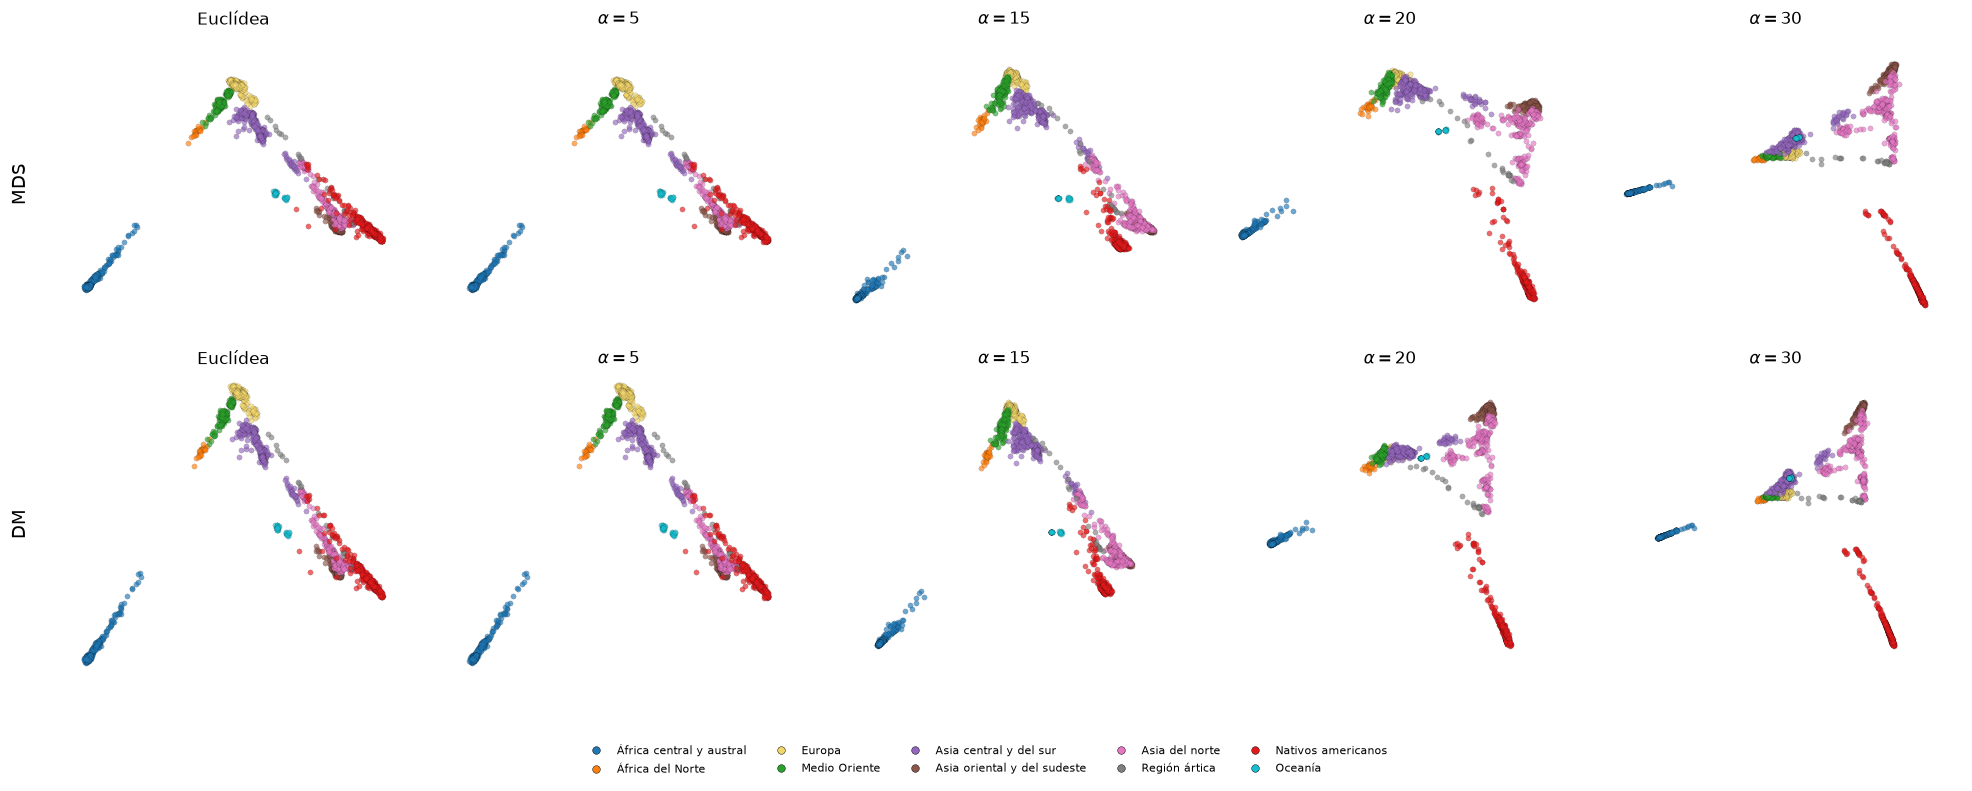

In [29]:
ALPHAS_GALERIA_GEN = [1., 5., 15., 20., 30.]
MAPAS_GEN = {(metodo, a): mapas_fermat(ESPACIO_REF, a)[metodo]
             for a in ALPHAS_GALERIA_GEN for metodo in ("MDS", "DM")}
galeria_tesis(MAPAS_GEN, ALPHAS_GALERIA_GEN, "P3_mds_dm_etapas", reg[:nr])

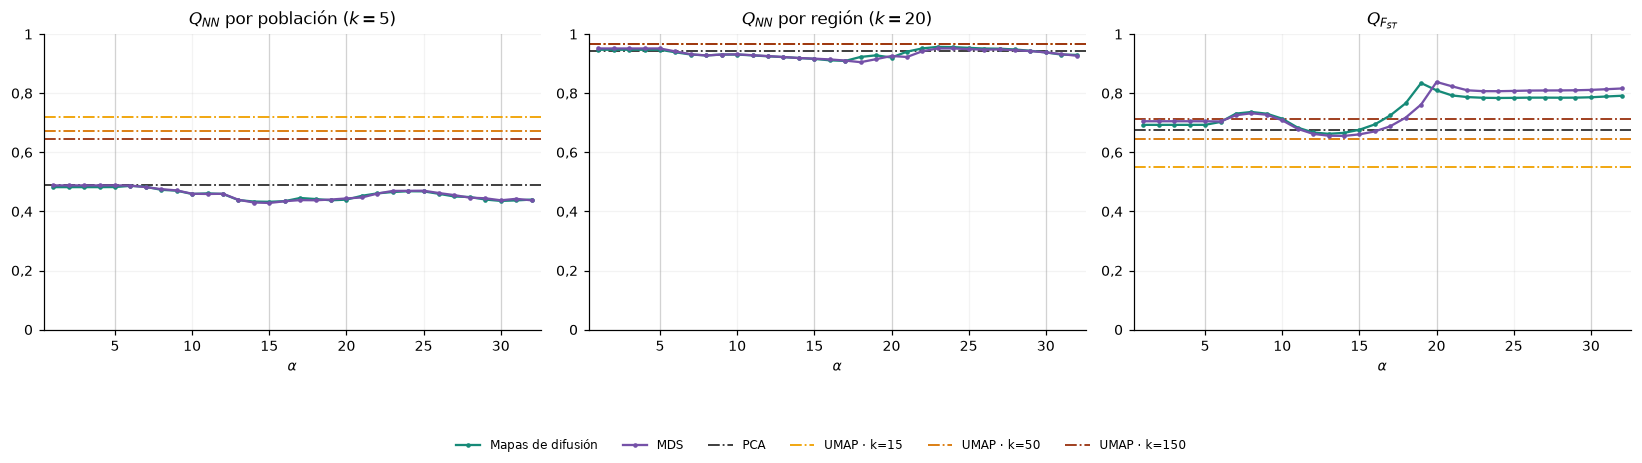

Controles:


,representacion,Q_NN_pob,Q_NN_reg,Q_FST
0,PCA · PC1–PC2,0.491,0.944,0.677
1,UMAP · k=15,0.720,0.967,0.550
2,UMAP · k=50,0.671,0.968,0.643
3,UMAP · k=150,0.644,0.966,0.713


Fermat en los exponentes de la galería y de la transición:


Q_NN_pob        Q_NN_reg         Q_FST       
metodo       DM    MDS       DM    MDS     DM    MDS
alpha                                               
1.0       0.482  0.488    0.947  0.951  0.693  0.705
6.0       0.487  0.487    0.938  0.941  0.703  0.705
10.0      0.459  0.460    0.931  0.932  0.714  0.708
16.0      0.435  0.435    0.911  0.914  0.695  0.671
17.0      0.446  0.438    0.909  0.911  0.725  0.688
20.0      0.440  0.444    0.921  0.926  0.810  0.838
24.0      0.468  0.470    0.956  0.952  0.784  0.807
32.0      0.440  0.438    0.930  0.927  0.791  0.816

In [30]:
figura_metricas_tesis(MET_REF, "P4_metricas_genotipos", xlim=(1, 32), marcados=[5, 15, 20, 30])

columnas = ["Q_NN_pob", "Q_NN_reg", "Q_FST"]
print("Controles:")
display(CONTROL_REF[["representacion"] + columnas].round(3))
print("Fermat en los exponentes de la galería y de la transición:")
display(MET_REF[MET_REF.alpha.isin([1, 6, 10, 16, 17, 20, 24, 32])]
        .pivot(index="alpha", columns="metodo", values=columnas).round(3))

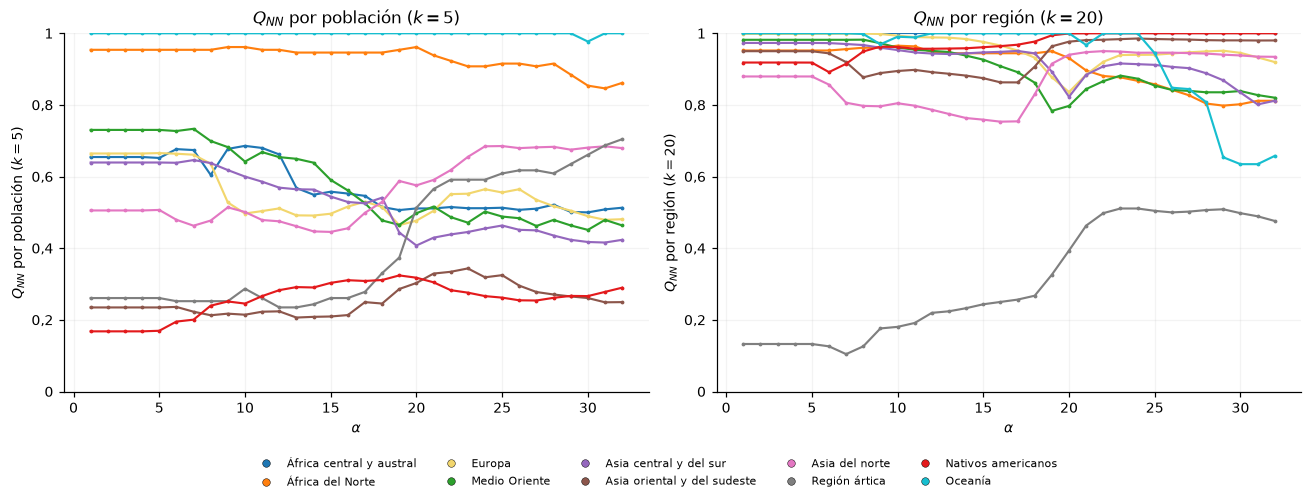

In [31]:
# Figura 5.15: agrupación local por región sobre los genotipos
# Se utiliza la misma función de agrupación que en PC50.
def por_region_qnn(Z, etiqueta, region, k):
    etiqueta, region = np.asarray(etiqueta), np.asarray(region)
    V = knn(squareform(pdist(Z)), k, auto=True)
    pureza = (etiqueta[V] == etiqueta[:, None]).mean(1)
    return pd.Series(pureza).groupby(region).mean()

filas = []
for alpha in ALPHAS_REF:
    Z = mapas_fermat(ESPACIO_REF, alpha)["DM"]
    q5 = por_region_qnn(Z, pob[:nr], reg[:nr], K_POB)
    q20 = por_region_qnn(Z, reg[:nr], reg[:nr], K_REG)
    for nombre_region in q20.index:
        filas.append({"alpha": alpha, "region": nombre_region,
                      "Q_NN_pob": q5.get(nombre_region, np.nan),
                      "Q_NN_reg": q20.get(nombre_region, np.nan)})
POR_REGION_GEN = tabla(pd.DataFrame(filas), "P4_qnn_por_region")

paneles = [("Q_NN_pob", r"$Q_{NN}$ por población ($k=5$)"),
           ("Q_NN_reg", r"$Q_{NN}$ por región ($k=20$)")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (col, titulo) in zip(axes, paneles):
    for nombre_region in ORDEN_REGIONES:
        g = POR_REGION_GEN[POR_REGION_GEN.region == nombre_region].sort_values("alpha")
        if not g.empty:
            ax.plot(g.alpha, g[col], color=COLORES.get(nombre_region, "0.6"),
                    marker=".", ms=3, lw=1.4, label=nombre_region)
    ax.set(title=titulo, xlabel=r"$\alpha$", ylabel=titulo, ylim=(0, 1))
    coma(ax)
    ax.grid(alpha=.15)
leyenda_regiones(fig, reg[:nr])
fig.tight_layout(rect=[0, .1, 1, 1])
guardar_figura(fig, "P4_qnn_por_region")

## 6. Reducción previa de la dimensión

Se vuelven a calcular las distancias sobre las primeras $q\in\{20,30,50,80,100,150\}$ componentes principales de las referencias. Se estudian las cantidades del modelo en cada espacio y las representaciones con $q=50$ (Sección 5.3.4).

In [32]:
# Espacios de referencias para el experimento previo y para la proyección afín.
ESPACIOS_PC_REF = {}
filas_geometria = []
for q in PCS_LISTA:
    Mq_euc_ref = squareform(pdist(X_PC_REF[R, :q]))
    Mq_ref, escala = normalizar(Mq_euc_ref, nr)
    ESPACIOS_PC_REF[q] = definir_espacio(Mq_ref, f"PC{q} · referencias (PCA referencias)")
    hq, gq = geometria(Mq_euc_ref, grupos_ref, reg[:nr])
    tabla(hq, f"P5_h_PC{q}")
    tabla(gq, f"P5_geometria_pares_PC{q}")
    rho_med = float(gq.rho.median())
    filas_geometria.append({"espacio": f"PC{q}", "q": q, "rho_mediana": rho_med,
        "alpha_rho_mediana": alpha_estrella(rho_med),
        "h_mediana": hq.h.median(), "S_mediana": gq.S.median(),
        "h_relativa_genotipos": hq.h.median()/INTRA.h.median(),
        "S_relativa_genotipos": gq.S.median()/GEO_REF.S.median(),
        "varianza_retenida": MODELO_PCA["w"][:q].sum()/MODELO_PCA["varianza_total"]})
filas_geometria.insert(0, {"espacio": "Genotipos", "q": p_valid,
    "rho_mediana": GEO_REF.rho.median(),
    "alpha_rho_mediana": alpha_estrella(float(GEO_REF.rho.median())),
    "h_mediana": INTRA.h.median(), "S_mediana": GEO_REF.S.median(),
    "h_relativa_genotipos": 1., "S_relativa_genotipos": 1., "varianza_retenida": 1.})
GEOMETRIA_PC = tabla(pd.DataFrame(filas_geometria), "P5_geometria_PCA")
display(GEOMETRIA_PC.round(4))
MET_PC50 = barrer_mapas(ESPACIOS_PC_REF[PC_C10], ALPHAS_FINO, CTX_REF,
                        "P5_fino_PC50", "PC50 referencias")
eleccion = []
for metodo, g in MET_PC50.groupby("metodo"):
    mejor = g.sort_values(["Q_FST", "alpha"], ascending=[False, True]).iloc[0]
    base = g[np.isclose(g.alpha, 1.)].iloc[0]
    eleccion.append({"metodo": metodo, "alpha_elegido_QFST": mejor.alpha,
        "Q_FST": mejor.Q_FST, "Q_FST_euclideo": base.Q_FST})
display(tabla(pd.DataFrame(eleccion), "P5_eleccion_alpha_PC50").round(4))

# Incorporación directa: PC50 recalculado CON referencias y uruguayos.
Mq_euc_con = squareform(pdist(X_PC_CON))
Mq_con, _ = normalizar(Mq_euc_con, nr)
ESPACIO_PC50_CON = definir_espacio(Mq_con, "PC50 · PCA conjunto completo")
ESPACIOS_PC = {PC_C10: ESPACIO_PC50_CON}  # compatibilidad con figuras originales
print("PC50 referencias y PC50 con C1--C10 construidos por separado")

,espacio,q,rho_mediana,alpha_rho_mediana,h_mediana,S_mediana,h_relativa_genotipos,S_relativa_genotipos,varianza_retenida
0,Genotipos,149257,0.3006,7.2829,37293.9109,22184.1105,1.0000,1.0000,1.0000
1,PC20,20,91.2956,1.0236,48.7067,15756.9768,0.0013,0.7103,0.1896
2,PC30,30,65.6665,1.0328,82.2118,16649.0715,0.0022,0.7505,0.1991
3,PC50,50,26.2934,1.0813,244.7466,18133.5279,0.0066,0.8174,0.2122
4,PC80,80,9.3760,1.2243,757.1016,18623.9846,0.0203,0.8395,0.2290
5,PC100,100,6.6771,1.3122,1107.9380,18736.2470,0.0297,0.8446,0.2397
6,PC150,150,3.9404,1.5204,2225.0616,18946.7999,0.0597,0.8541,0.2659


,metodo,alpha_elegido_QFST,Q_FST,Q_FST_euclideo
0,DM,1.5,0.8393,0.6789
1,MDS,1.4,0.8681,0.7052


PC50 referencias y PC50 con C1--C10 construidos por separado


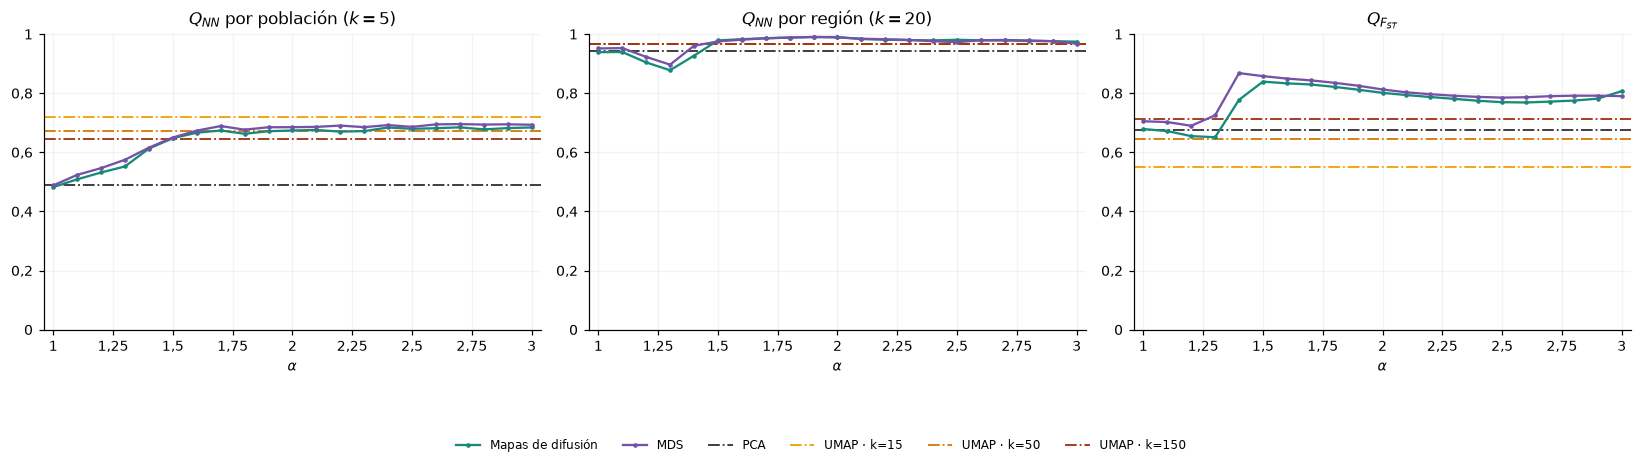

Q_NN_pob        Q_NN_reg         Q_FST       
metodo       DM    MDS       DM    MDS     DM    MDS
alpha                                               
1.0       0.482  0.488    0.939  0.951  0.679  0.705
1.2       0.532  0.547    0.904  0.923  0.655  0.690
1.3       0.552  0.575    0.878  0.897  0.651  0.725
1.4       0.613  0.616    0.927  0.961  0.778  0.868
1.5       0.648  0.650    0.979  0.975  0.839  0.858
1.7       0.674  0.689    0.986  0.986  0.830  0.844
2.0       0.674  0.685    0.990  0.989  0.801  0.813
2.5       0.680  0.686    0.981  0.973  0.770  0.785
3.0       0.684  0.693    0.974  0.968  0.807  0.790

DM: Q_FST euclídeo 0.679, máximo 0.839 en α=1.5; Q_NN_pob 0.482→0.648 (α=1,5)
MDS: Q_FST euclídeo 0.705, máximo 0.868 en α=1.4; Q_NN_pob 0.488→0.650 (α=1,5)


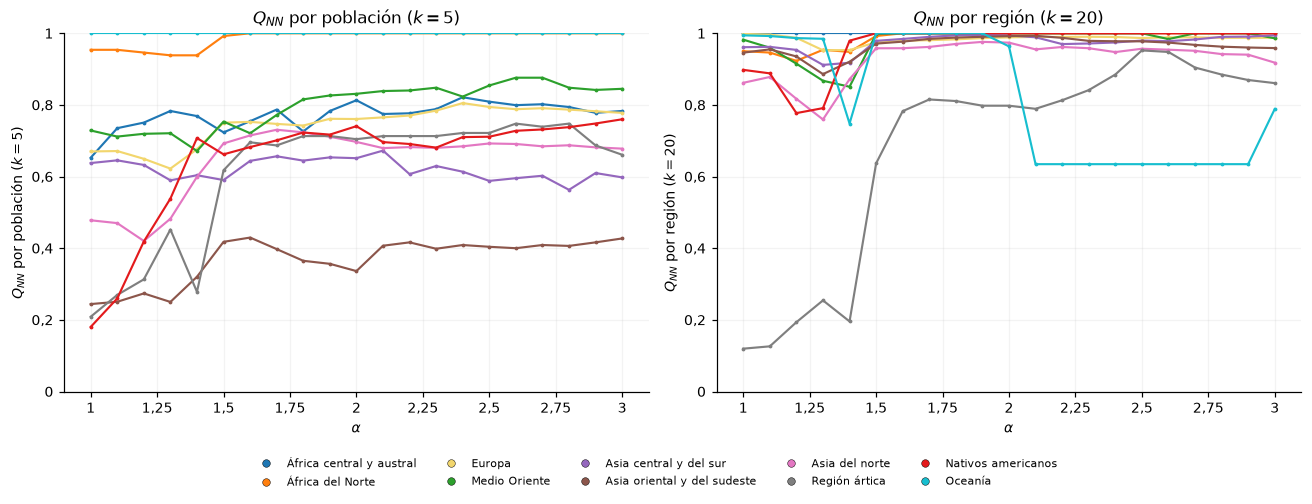

In [33]:
# 1) Figura agregada (3 paneles)
figura_metricas_tesis(MET_PC50, "P5_metricas_PC50", xlim=(1, 3))

# 2) Resumen con las tres métricas
cols = ["Q_NN_pob", "Q_NN_reg", "Q_FST"]
t = MET_PC50.assign(alpha=MET_PC50.alpha.round(2))
display(t[t.alpha.isin([1., 1.2, 1.3, 1.4, 1.5, 1.7, 2., 2.5, 3.])]
        .pivot(index="alpha", columns="metodo", values=cols).round(3))
for metodo, g in t.groupby("metodo"):
    base = g[np.isclose(g.alpha, 1.)].iloc[0]
    a15 = g[np.isclose(g.alpha, 1.5)].iloc[0]
    mejor_fst = g.loc[g.Q_FST.idxmax()]
    print(f"{metodo}: Q_FST euclídeo {base.Q_FST:.3f}, máximo {mejor_fst.Q_FST:.3f} en α={mejor_fst.alpha:g}; "
          f"Q_NN_pob {base.Q_NN_pob:.3f}→{a15.Q_NN_pob:.3f} (α=1,5)")

# 3) Figura por región (k=5 y k=20), PC50, alpha 1..3
filas = []
for alpha in ALPHAS_FINO:
    Z = mapas_fermat(ESPACIOS_PC_REF[50], alpha)["DM"]
    q5  = por_region_qnn(Z, pob[:nr], reg[:nr], K_POB)
    q20 = por_region_qnn(Z, reg[:nr], reg[:nr], K_REG)
    for nombre_region in q20.index:
        filas.append({"alpha": alpha, "region": nombre_region,
                      "Q_NN_pob": q5.get(nombre_region, np.nan), "Q_NN_reg": q20.get(nombre_region, np.nan)})
POR_REGION_PC50 = pd.DataFrame(filas)

paneles = [("Q_NN_pob", r"$Q_{NN}$ por población ($k=5$)"),
           ("Q_NN_reg", r"$Q_{NN}$ por región ($k=20$)")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (col, titulo) in zip(axes, paneles):
    for nombre_region in ORDEN_REGIONES:
        g = POR_REGION_PC50[POR_REGION_PC50.region == nombre_region].sort_values("alpha")
        if g.empty:
            continue
        ax.plot(g.alpha, g[col], color=COLORES.get(nombre_region, "0.6"), marker=".", ms=3, lw=1.4, label=nombre_region)
    ax.set(title=titulo, xlabel=r"$\alpha$", ylabel=titulo, ylim=(0, 1))
    coma(ax); ax.grid(alpha=.15)
leyenda_regiones(fig, reg[:nr])
fig.tight_layout(rect=[0, .1, 1, 1])
guardar_figura(fig, "P5_qnn_por_region_PC50")

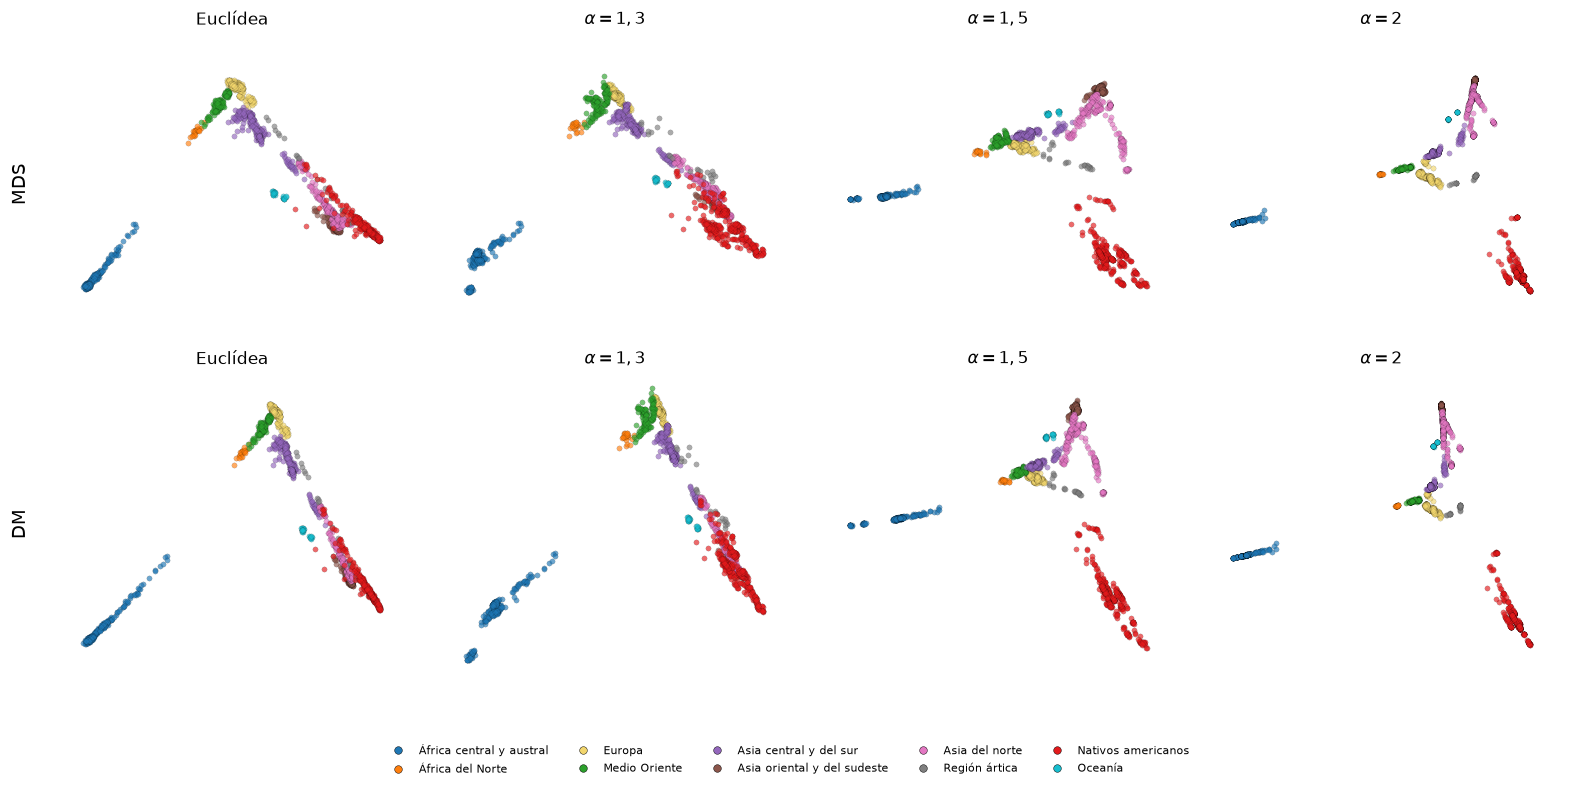

In [34]:
ALPHAS_GALERIA_PC50 = [1., 1.3, 1.5, 2.]
MAPAS_PC50_GAL = {(metodo, a): mapas_fermat(ESPACIOS_PC_REF[50], a)[metodo]
                  for a in ALPHAS_GALERIA_PC50 for metodo in ("MDS", "DM")}
galeria_tesis(MAPAS_PC50_GAL, ALPHAS_GALERIA_PC50, "P5_representaciones_PC50", reg[:nr])

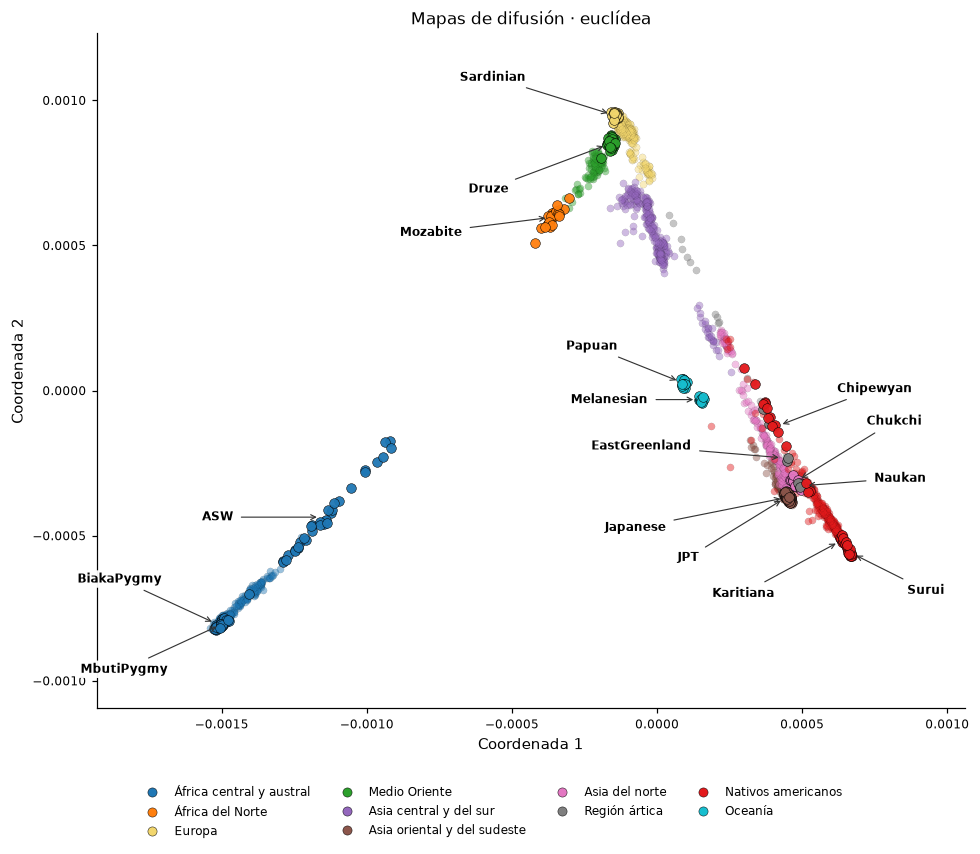

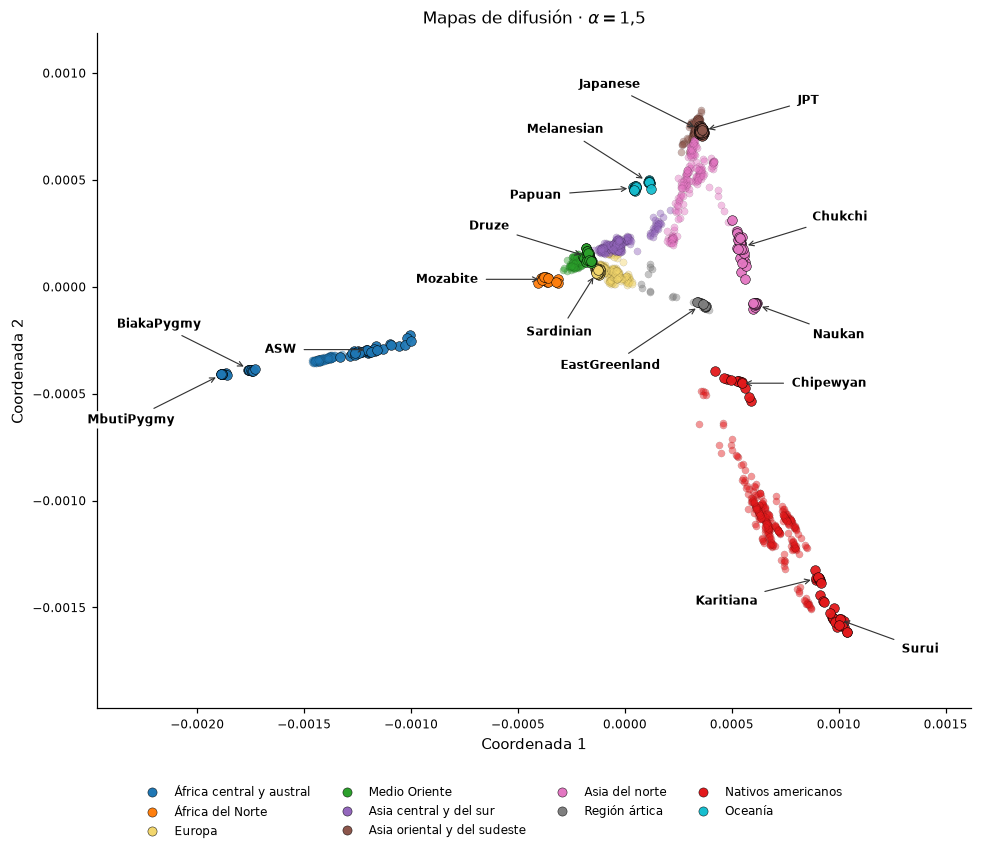

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.linalg import orthogonal_procrustes

METODO_FIGURA = "DM"
ALPHA_FIGURA = 1.5
TAMANO_PUNTOS, TAMANO_MARCADOS, TAMANO_TEXTO = 22, 40, 8

# Cada etiqueta señala el centroide de las poblaciones de su lista.
GRUPOS_MARCADOS = {
    "BiakaPygmy": ["BiakaPygmy"],
    "MbutiPygmy": ["MbutiPygmy"],
    "ASW": ["ASW"],
    "Mozabite": ["Mozabite"],
    "Sardinian": ["Sardinian"],
    "Druze": ["Druze"],
    "JPT": ["JPT"],
    "Japanese": ["Japanese"],
    "Chukchi": ["Chukchi"],
    "Naukan": ["Naukan"],
    "EastGreenland": ["EastGreenland"],
    "Chipewyan": ["Chipewyan"],
    "Karitiana": ["Karitiana"],
    "Surui": ["Surui"],
    "Papuan": ["Papuan"],
    "Melanesian": ["Melanesian"],
}

# Desplazamientos respecto del centroide, en puntos (horizontal, vertical).
# Ajustados a las capturas de DM con 50 componentes y alpha = 1.5.
DESPLAZAMIENTOS_EUC = {
    "BiakaPygmy": (-65, 30),
    "MbutiPygmy": (-65, -30),
    "ASW": (-70, 0),

    "Sardinian": (-80, 25),
    "Druze": (-80, -30),
    "Mozabite": (-80, -10),

    "Papuan": (-60, 24),
    "Melanesian": (-60, 0),

    "EastGreenland": (-95, 8),
    "Japanese": (-100, -20),
    "JPT": (-65, -40),

    "Chipewyan": (65, 25),
    "Chukchi": (65, 40),
    "Naukan": (65, 5),

    "Karitiana": (-65, -35),
    "Surui": (50, -25),
}

DESPLAZAMIENTOS_FER = {
    "BiakaPygmy": (-60, 30),
    "MbutiPygmy": (-60, -30),
    "ASW": (-60, 0),

    "Druze": (-65, 20),
    "Mozabite": (-65, 0),
    "Sardinian": (-25, -40),

    "Papuan": (-65, -5),
    "Melanesian": (-55, 35),

    "Japanese": (-60, 30),
    "JPT": (70, 20),

    "Chukchi": (65, 20),
    "Naukan": (55, -20),
    "EastGreenland": (-60, -40),
    "Chipewyan": (60, 0),

    "Karitiana": (-60, -15),
    "Surui": (55, -20),
}

regiones_fig = np.asarray(reg[:nr])
poblaciones_fig = np.asarray(pob[:nr])
todas = [q for lista in GRUPOS_MARCADOS.values() for q in lista]
faltan = [q for q in todas if q not in set(poblaciones_fig)]
assert not faltan, f"No encontré estas poblaciones: {faltan}"


def alinear_prueba(Z, Zref):
    A = Z - Z.mean(0)
    B = Zref - Zref.mean(0)
    rotacion, _ = orthogonal_procrustes(A, B)
    return A @ rotacion


Z_euc = mapas_fermat(ESPACIOS_PC_REF[50], 1.0)[METODO_FIGURA]
Z_fer = alinear_prueba(
    mapas_fermat(ESPACIOS_PC_REF[50], ALPHA_FIGURA)[METODO_FIGURA],
    Z_euc,
)
Z_euc = Z_euc - Z_euc.mean(0)


def figura_poblaciones(Z, titulo, desplazamientos, nombre):
    fig, ax = plt.subplots(figsize=(9, 7.8))
    marcados = np.isin(poblaciones_fig, todas)

    # Poblaciones sin etiqueta, con menor opacidad.
    for r in ORDEN_REGIONES:
        sel = (regiones_fig == r) & ~marcados
        if sel.any():
            ax.scatter(
                Z[sel, 0], Z[sel, 1],
                s=TAMANO_PUNTOS,
                c=COLORES[r],
                alpha=.45,
                linewidths=.10,
                edgecolors="black",
                zorder=2,
                rasterized=True,
            )

    # Poblaciones destacadas y flechas hacia sus centroides.
    for etiqueta, lista in GRUPOS_MARCADOS.items():
        sel = np.isin(poblaciones_fig, lista)
        color = COLORES[regiones_fig[sel][0]]

        ax.scatter(
            Z[sel, 0], Z[sel, 1],
            s=TAMANO_MARCADOS,
            c=color,
            alpha=.95,
            linewidths=.35,
            edgecolors="black",
            zorder=4,
        )

        ax.annotate(
            etiqueta,
            xy=Z[sel].mean(0),
            xytext=desplazamientos.get(etiqueta, (40, 20)),
            textcoords="offset points",
            fontsize=TAMANO_TEXTO,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=6,
            annotation_clip=False,
            bbox=dict(
                boxstyle="round,pad=.18",
                fc="white",
                ec="none",
                alpha=.95,
            ),
            arrowprops=dict(
                arrowstyle="->",
                color="#333333",
                lw=.75,
                shrinkA=4,
                shrinkB=5,
                connectionstyle="arc3,rad=0",
            ),
        )

    ax.set_title(titulo)
    ax.margins(.22)
    ax.set_aspect("equal", adjustable="datalim")
    # Mostrar los ejes izquierdo e inferior.
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="both", labelsize=8)

    ax.set_xlabel("Coordenada 1", fontsize=10)
    ax.set_ylabel("Coordenada 2", fontsize=10)

    handles = [
        Line2D(
            [], [],
            marker="o",
            ls="",
            markersize=6,
            color=COLORES[r],
            markeredgecolor="black",
            markeredgewidth=.3,
            label=r,
        )
        for r in ORDEN_REGIONES
        if r in set(regiones_fig)
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(.5, .005),
        ncol=4,
        fontsize=8,
        frameon=False,
    )

    fig.tight_layout(rect=[0, .1, 1, 1])
    guardar_figura(fig, nombre)


nombre_metodo = "Mapas de difusión" if METODO_FIGURA == "DM" else "MDS"

figura_poblaciones(
    Z_euc,
    f"{nombre_metodo} · euclídea",
    DESPLAZAMIENTOS_EUC,
    "P5_poblaciones_euclidea",
)

figura_poblaciones(
    Z_fer,
    rf"{nombre_metodo} · $\alpha={ALPHA_FIGURA:g}$".replace(".", "{,}"),
    DESPLAZAMIENTOS_FER,
    "P5_poblaciones_fermat",
)

## 7. Incorporación de los uruguayos

Se comparan dos análisis completos. En el primero, PCA50 y Fermat se calculan con las 2183 referencias; en el segundo, ambos se recalculan incorporando desde el comienzo a C1–C10 (2193 individuos). Se comparan los caminos entre los mismos pares de referencias y se registra la participación de los uruguayos como intermediarios. Como cambian las componentes principales, las diferencias en los recorridos no se atribuyen exclusivamente a los nuevos nodos.

Para las representaciones se compara además una proyección afín sobre el mapa fijo de referencias. El PCA de referencia utilizado como control se estandariza por SNP; los PCA50 empleados para Fermat permanecen centrados, sin escalar.


In [36]:
def ajustar_afin(X, Z):
    A = np.column_stack([X, np.ones(len(X))])
    coef, _, rango, singular = np.linalg.lstsq(A, Z, rcond=None)
    condicion = float(singular[0]/singular[-1]) if singular[-1] > 0 else np.inf
    return {"coef": coef, "rango": int(rango), "columnas": A.shape[1], "condicion": condicion}

def aplicar_afin(X, modelo):
    return np.column_stack([X, np.ones(len(X))]) @ modelo["coef"]

def pesos_triangulo(centros, puntos, umbral_cond=1e-4):
    A = np.column_stack([centros[0]-centros[2], centros[1]-centros[2]])
    sv = np.linalg.svd(A, compute_uv=False)
    razon = float(sv[-1]/sv[0]) if sv[0] > 0 else 0.
    Q = np.full((len(puntos), 3), np.nan)
    fuera = np.zeros(len(puntos), bool)
    if razon < umbral_cond:
        return Q, fuera, razon
    for k, punto in enumerate(puntos):
        w = np.linalg.solve(A, punto-centros[2])
        q = np.r_[w, 1-w.sum()]
        if (q >= -1e-10).all():
            q = np.maximum(q, 0)
            Q[k] = q/q.sum()
        else:
            fuera[k] = True
            candidatos = []
            for a, b in ((0, 1), (0, 2), (1, 2)):
                lado = centros[b]-centros[a]
                t = float(np.clip(np.dot(punto-centros[a], lado)/np.dot(lado, lado), 0, 1))
                qq = np.zeros(3)
                qq[a], qq[b] = 1-t, t
                candidatos.append((np.sum((punto-qq@centros)**2), qq))
            Q[k] = min(candidatos, key=lambda par: par[0])[1]
    return Q, fuera, razon

def evaluar_ancestria(Z):
    centros = []
    for comp in COMPONENTES:
        ids = R[reg[:nr] == REG_FUENTE[comp]]
        if not len(ids):
            raise ValueError(f"Faltan referencias para {REG_FUENTE[comp]}")
        centros.append(Z[ids].mean(0))
    Q, fuera, razon = pesos_triangulo(np.array(centros), Z[C])
    valido = bool(np.isfinite(Q).all())
    error = Q-Q_ADM
    resumen = {"n_C": len(C), "triangulo_valido": valido, "razon_singular": razon,
        "C_fuera_triangulo": int(fuera.sum()) if valido else np.nan,
        "MAE_ADM_pp": float(100*np.abs(error).mean()) if valido else np.nan}
    detalle = []
    for j, comp in enumerate(COMPONENTES):
        resumen[f"MAE_{comp}_pp"] = float(100*np.abs(error[:, j]).mean()) if valido else np.nan
        for k, idc in enumerate(IDS_C):
            detalle.append({"id": idc, "componente": comp,
                "ADMIXTURE_pct": 100*Q_ADM[k, j], "geometrico_pct": 100*Q[k, j],
                "fuera_triangulo": bool(fuera[k]) if valido else None})
    return resumen, detalle, Q

# Evitar que un bucle exploratorio sobrescriba los índices de referencias.
# La selección original deja las referencias en las primeras `nr` filas.
if not isinstance(R, np.ndarray) or R.ndim != 1 or not np.array_equal(R, np.arange(nr)):
    raise RuntimeError("R debe ser el vector de índices de referencias; ejecutar desde la preparación de datos")

generador_cv = np.random.default_rng(SEED)
TEST_AFIN = np.sort(np.concatenate([
    generador_cv.choice(ids, size=max(1, int(np.ceil(FRACCION_VALIDACION*len(ids)))),
                       replace=False) for ids in grupos_ref.values()]))
TRAIN_AFIN = np.setdiff1d(R, TEST_AFIN)
X50 = X_PC_REF[:, :PC_C10]  # SÓLO para la proyección afín
CTX_C10 = contexto_metricas(D_euc, nr, pob, reg, P_REF)
tabla(pd.DataFrame({"IID": et.iloc[R].IID, "poblacion": pob[:nr],
                    "validacion_afin": np.isin(R, TEST_AFIN)}), "U1_particion_validacion")

def validar_afin(ZR):
    modelo = ajustar_afin(X50[TRAIN_AFIN], ZR[TRAIN_AFIN])
    pred = aplicar_afin(X50[TEST_AFIN], modelo)
    mse = float(np.mean(np.sum((pred-ZR[TEST_AFIN])**2, axis=1)))
    base = float(np.mean(np.sum((ZR[TEST_AFIN]-ZR[TRAIN_AFIN].mean(0))**2, axis=1)))
    relativo = mse/base if base > 0 else np.nan
    return {"n_train": len(TRAIN_AFIN), "n_validacion": len(TEST_AFIN),
            "MSE": mse, "MSE_media": base, "MSE_relativo": relativo,
            "RMSE_relativo": float(np.sqrt(relativo)), "rango": modelo["rango"],
            "n_columnas": modelo["columnas"], "condicion_diseno": modelo["condicion"]}

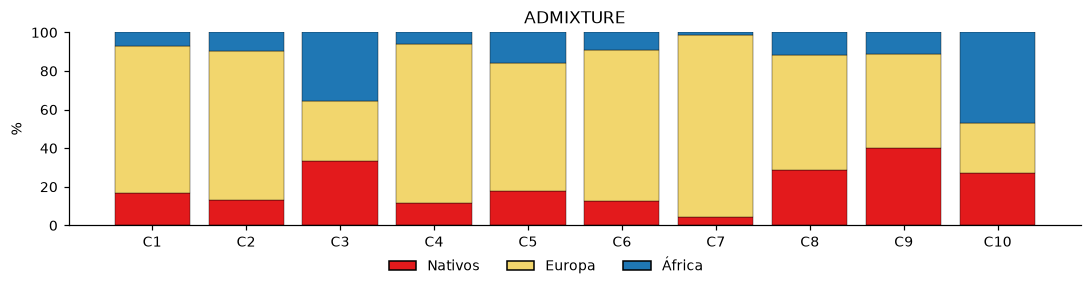

In [37]:
# Proporciones de ancestría por individuo: ADMIXTURE y las que se leen en cada representación
def barras_proporciones(paneles, nombre):
    fig, axes = plt.subplots(len(paneles), 1, figsize=(10, 2.1*len(paneles)+.5),
                             sharex=True, squeeze=False)
    for ax, (titulo, Q) in zip(axes.flat, paneles.items()):
        base = np.zeros(len(IDS_C))
        for k, color in enumerate(COLORES_ANCESTRIA):
            ax.bar(np.arange(len(IDS_C)), 100*Q[:, k], bottom=base, color=color,
                   edgecolor="black", linewidth=.25)
            base += 100*Q[:, k]
        ax.set(title=titulo, ylim=(0, 100), ylabel="%")
    axes[-1, 0].set(xticks=range(len(IDS_C)), xticklabels=IDS_C)
    fig.legend(handles=[Patch(facecolor=c, edgecolor="black", label=k)
               for k, c in zip(COMPONENTES, COLORES_ANCESTRIA)],
               loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=[0, .06, 1, 1])
    guardar_figura(fig, nombre)



barras_proporciones({"ADMIXTURE": Q_ADM}, "proporciones_ancestria_uruguayos")

### Controles PCA y UMAP

El PCA convencional utiliza genotipos estandarizados según las frecuencias alélicas de las referencias. Los uruguayos se proyectan sobre esos ejes. UMAP utiliza distancias euclídeas entre genotipos del conjunto completo (Figura 5.20).


,control,Q_NN_pob,Q_NN_reg,Q_FST,MAE_ADM_pp,MAE_Nativos_pp,MAE_Europa_pp,MAE_África_pp,C_fuera_triangulo
0,PCA · con C1–C10,0.4908,0.9437,0.677,4.1770,1.1604,5.3184,6.0520,0
1,UMAP · k=50 · con C1–C10,0.6913,0.9722,0.527,23.3892,30.8106,24.1475,15.2096,5


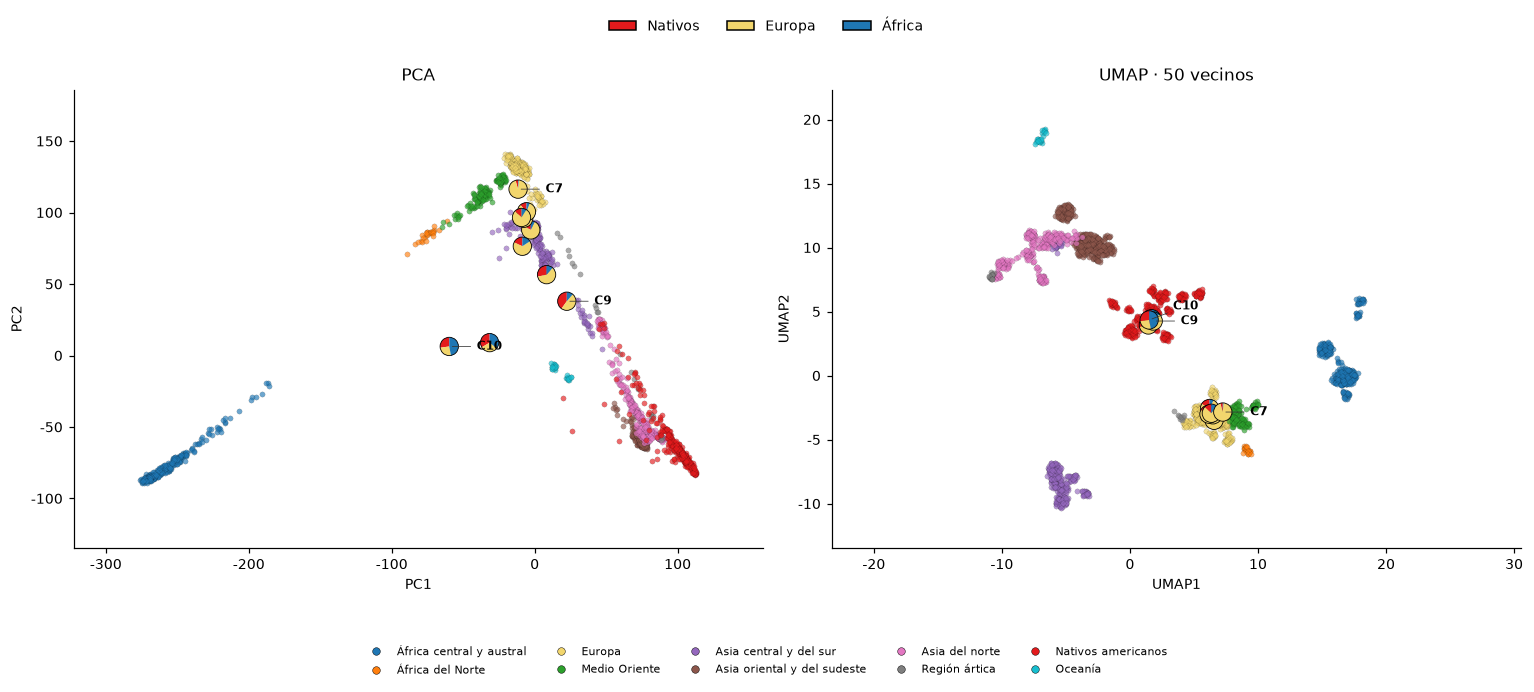

In [38]:
CONTROLES_C10_MAPAS = {
    "PCA · con C1–C10": X_PC_EST[:, :2],
    # UMAP siempre sobre los genotipos (referencias + C1–C10), como en la Sección 5.3.4.
    "UMAP · k=50 · con C1–C10": mapa_umap({"clave": "Genotipos_C10", "M": D}, 50),
}
filas_control, porcentajes_control = [], []
Q_CONTROLES = {}
for nombre, Z in CONTROLES_C10_MAPAS.items():
    anc, detalle, Q = evaluar_ancestria(Z)
    filas_control.append({"control": nombre, **evaluar_mapa(Z, CTX_C10), **anc})
    porcentajes_control.extend([{**r, "control": nombre} for r in detalle])
    Q_CONTROLES[nombre] = Q
CONTROL_C10 = tabla(pd.DataFrame(filas_control), "U1_controles_C10")
tabla(pd.DataFrame(porcentajes_control), "U1_controles_porcentajes")
display(CONTROL_C10[["control", "Q_NN_pob", "Q_NN_reg", "Q_FST",
                     "MAE_ADM_pp", "MAE_Nativos_pp", "MAE_Europa_pp", "MAE_África_pp",
                     "C_fuera_triangulo"]].round(4))
# Figura de la tesis. El signo de cada componente de PCA es arbitrario: se orienta
# con África a la izquierda y abajo, como en la versión anterior (sólo afecta al dibujo).
Z_PCA_FIG = X_PC_EST[:, :2].copy()
africa = reg[:nr] == "África central y austral"
for eje in (0, 1):
    if Z_PCA_FIG[:nr][africa, eje].mean() > 0:
        Z_PCA_FIG[:, eje] *= -1

fig, axes = plt.subplots(1, 2, figsize=(14, 6.3))
nube(axes[0], Z_PCA_FIG, reg, "PCA", ids_c=C, pies=True, ejes=("PC1", "PC2"))
nube(axes[1], CONTROLES_C10_MAPAS["UMAP · k=50 · con C1–C10"], reg, "UMAP · 50 vecinos",
     ids_c=C, pies=True, ejes=("UMAP1", "UMAP2"))
leyenda_regiones(fig, reg, pies=True)
fig.savefig(FIGURAS / "uru_pca_umap_C10.png", bbox_inches="tight")
fig.savefig(FIGURAS / "uru_pca_umap_C10.pdf", bbox_inches="tight")
guardar_figura(fig, "U1_PCA_UMAP_C10")

### Caminos mínimos

Se comparan los mismos pares de referencias en los dos análisis completos (2183 y 2193 individuos). Se registra la aparición y desaparición de atajos, los recorridos y la participación de C1–C10. Cada comparación con el enlace directo se realiza dentro del espacio PC50 correspondiente; no se comparan costos absolutos entre espacios.


In [39]:
def efecto_C10(alpha, F_sin, F_con):
    """Cambios de atajos entre dos análisis completos, cada uno con su PCA50."""
    i, j = np.triu_indices(nr, 1)
    directos_sin = ESPACIOS_PC_REF[PC_C10]["M"][i, j]**alpha
    directos_con = ESPACIO_PC50_CON["M"][i, j]**alpha
    atajos_sin = cociente(F_sin[i, j], directos_sin) < 1-TOL
    atajos_con = cociente(F_con[i, j], directos_con) < 1-TOL
    aparecen = ~atajos_sin & atajos_con
    desaparecen = atajos_sin & ~atajos_con
    total = len(i)
    return {
        "alpha": alpha, "n_pares_RR": total,
        "atajos_sin_pct": 100*atajos_sin.mean(),
        "atajos_con_pct": 100*atajos_con.mean(),
        "aparecen_n": int(aparecen.sum()),
        "aparecen_pct": 100*aparecen.mean(),
        "desaparecen_n": int(desaparecen.sum()),
        "desaparecen_pct": 100*desaparecen.mean(),
    }

ESCENARIOS = ("Sin los diez", "Con los diez", "Proyección afín")

def mapas_C10(alpha, F0=None, F1=None):
    solo = mapas_fermat(ESPACIOS_PC_REF[PC_C10], alpha, F=F0)
    conjunto = mapas_fermat(ESPACIOS_PC[PC_C10], alpha, F=F1)
    mapas, modelos = {}, {}
    for metodo in ("MDS", "DM"):
        ZR = solo[metodo]
        modelo = ajustar_afin(X50[R], ZR)
        ZA = np.vstack([ZR, aplicar_afin(X50[C], modelo)])
        assert np.array_equal(ZA[R], ZR), "La extensión afín alteró las referencias"
        mapas[(metodo, "Sin los diez")] = ZR
        mapas[(metodo, "Con los diez")] = conjunto[metodo]
        mapas[(metodo, "Proyección afín")] = ZA
        modelos[metodo] = modelo
    return mapas, modelos

def resultado_C10(alpha):
    archivo = CACHE/f"C10_PC50_dos_analisis_v3_a{float(alpha).hex()}.json"
    if archivo.exists():
        return json.loads(archivo.read_text())
    # Dos PCA50 calculados por separado: referencias (2183) y conjunto (2193).
    F_sin, _ = fermat(ESPACIOS_PC_REF[PC_C10], alpha)
    F_con, _ = fermat(ESPACIO_PC50_CON, alpha)
    efecto = efecto_C10(alpha, F_sin, F_con)
    mapas, modelos = mapas_C10(alpha, F_sin, F_con)
    metrica, proporciones, validacion = [], [], []
    for (metodo, escenario), Z in mapas.items():
        fila = {"alpha": alpha, "metodo": metodo, "escenario": escenario,
                **evaluar_mapa(Z, CTX_REF if escenario == "Sin los diez" else CTX_C10)}
        if escenario != "Sin los diez":
            anc, detalle, _ = evaluar_ancestria(Z)
            fila.update(anc)
            proporciones.extend([{**r, "alpha": alpha, "metodo": metodo, "escenario": escenario}
                                 for r in detalle])
        metrica.append(fila)
        if escenario == "Sin los diez":
            validacion.append({"alpha": alpha, "metodo": metodo, **validar_afin(Z)})
    resultado = {"metricas": metrica, "proporciones": proporciones, "validacion": validacion,
                 "efecto": efecto}
    escribir_json(resultado, archivo)
    return resultado


In [40]:
RESULTADOS_C10 = [resultado_C10(float(a)) for a in sorted(set(ALPHAS_FINO) | {ALPHA_C10})]
MET_C10 = tabla(pd.DataFrame([r for z in RESULTADOS_C10 for r in z["metricas"]]),
                "U2_barrido_C10_metricas")
PORCENTAJES_C10 = tabla(pd.DataFrame([r for z in RESULTADOS_C10 for r in z["proporciones"]]),
                        "U2_porcentajes_C10")
VALIDACION_AFIN = tabla(pd.DataFrame([r for z in RESULTADOS_C10 for r in z["validacion"]]),
                        "U2_validacion_afin")
EFECTO_C10 = tabla(pd.DataFrame([z["efecto"] for z in RESULTADOS_C10]), "U2_efecto_caminos")
# Las métricas de estructura deben coincidir exactamente entre el mapa fijo y la proyección.
for (alpha, metodo), t in MET_C10.groupby(["alpha", "metodo"]):
    t = t.set_index("escenario")
    for variable in ("Q_NN_pob", "Q_NN_reg", "Q_FST"):
        assert np.isclose(t.loc["Sin los diez", variable], t.loc["Proyección afín", variable],
                          equal_nan=True)

display(EFECTO_C10[EFECTO_C10.alpha.round(2).isin([1.2, 1.3, 1.4, 1.5, 2., 2.5, 3.])].round(3))

,alpha,n_pares_RR,atajos_sin_pct,atajos_con_pct,aparecen_n,aparecen_pct,desaparecen_n,desaparecen_pct
2,1.2,2381653,36.838,37.672,25464,1.069,5621,0.236
3,1.3,2381653,61.891,62.377,18023,0.757,6435,0.270
4,1.4,2381653,80.632,80.803,9548,0.401,5475,0.230
5,1.5,2381653,89.681,89.871,7813,0.328,3273,0.137
10,2.0,2381653,96.717,96.721,1085,0.046,979,0.041
15,2.5,2381653,97.833,97.842,1128,0.047,920,0.039
20,3.0,2381653,98.460,98.467,1102,0.046,949,0.040


In [41]:
# Espacio original completo, utilizado además en los resultados del Apéndice C.4
ESPACIO_GEN_C10 = definir_espacio(D, "Genotipos · referencias + C1–C10")

In [42]:
# Recupera el par MbutiPygmy–Surui fijado en 5.3.3 desde la tabla guardada.
ruta_par = json.loads(pd.read_csv(TABLAS/"P2_recorridos_par_fijo.csv").ruta.iloc[0])
EXTREMOS_RUTA = (int(ruta_par[0]), int(ruta_par[-1]))
print("Par:", et.iloc[list(EXTREMOS_RUTA)][["IID", "label"]].to_dict("records"))

Par: [{'IID': '74_HGDP00450', 'label': 'MbutiPygmy'}, {'IID': '2078_4256126341_A', 'label': 'Surui'}]


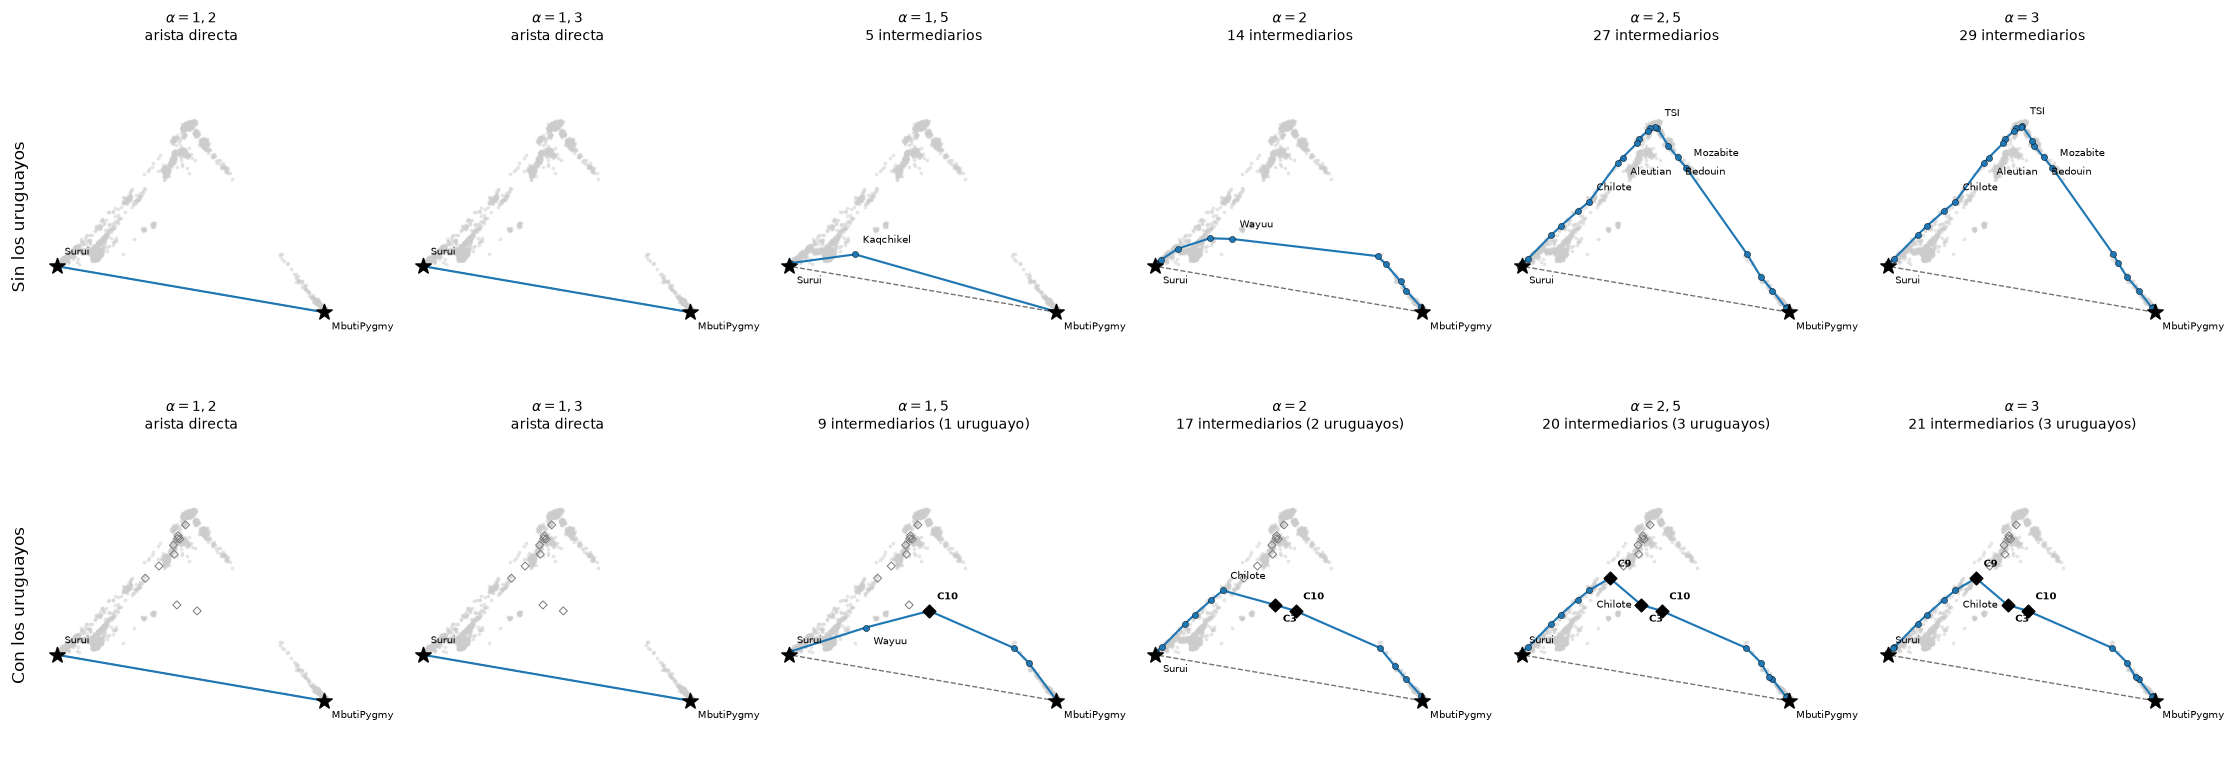

,espacio,alpha,escenario,intermediarios,uruguayos,cociente,regiones
0,PC50,1.2,Sin los uruguayos,0,0,1.000,África central y austral → Nativos americanos
1,PC50,1.2,Con los uruguayos,0,0,1.000,África central y austral → Nativos americanos
2,PC50,1.3,Sin los uruguayos,0,0,1.000,África central y austral → Nativos americanos
3,PC50,1.3,Con los uruguayos,0,0,1.000,África central y austral → Nativos americanos
4,PC50,1.5,Sin los uruguayos,5,0,0.947,África central y austral → Nativos americanos
5,PC50,1.5,Con los uruguayos,9,1,0.907,África central y austral → Uruguayos → Nativos...
6,PC50,2.0,Sin los uruguayos,14,0,0.521,África central y austral → Nativos americanos
7,PC50,2.0,Con los uruguayos,17,2,0.440,África central y austral → Uruguayos → Nativos...
8,PC50,2.5,Sin los uruguayos,27,0,0.262,África central y austral → África del Norte → ...
9,PC50,2.5,Con los uruguayos,20,3,0.216,África central y austral → Uruguayos → Nativos...


In [43]:
# Evolución del camino MbutiPygmy–Surui con alpha, sin y con los diez
EVOLUCION_CAMINOS = [("PC50", ESPACIOS_PC_REF[PC_C10], ESPACIO_PC50_CON, [1.2, 1.3, 1.5, 2., 2.5, 3.])]
etiquetas_nodos = np.array(list(pob[:nr]) + list(IDS_C), dtype=object)
regiones_nodos = np.array(list(reg[:nr]) + ["Uruguayos"]*len(IDS_C), dtype=object)
i_par, j_par = EXTREMOS_RUTA
Z_pca = X_PC_CON[:, :2]


def dibujar_camino(ax, ruta, con_C):
    ax.scatter(Z_pca[:nr, 0], Z_pca[:nr, 1], s=6, c="0.8", alpha=.5, linewidths=0, zorder=1,
               rasterized=True)
    if con_C:
        ax.scatter(Z_pca[C, 0], Z_pca[C, 1], s=14, marker="D", facecolors="none",
                   edgecolors="0.45", linewidths=.6, zorder=2)
    a, b = ruta[0], ruta[-1]
    ax.plot(Z_pca[[a, b], 0], Z_pca[[a, b], 1], color="0.45", ls="--", lw=.9, zorder=2)
    ax.plot(Z_pca[ruta, 0], Z_pca[ruta, 1], color="#1f77b4", lw=1.4, zorder=3)
    medio = ruta[1:-1]
    refs = [v for v in medio if v < nr]
    uru = [v for v in medio if v >= nr]
    if refs:
        ax.scatter(Z_pca[refs, 0], Z_pca[refs, 1], s=16, c="#1f77b4", edgecolors="black",
                   linewidths=.3, zorder=4)
    if uru:
        ax.scatter(Z_pca[uru, 0], Z_pca[uru, 1], s=34, marker="D", c="black", zorder=5)
    ax.scatter(Z_pca[[a, b], 0], Z_pca[[a, b], 1], marker="*", s=110, c="black", zorder=6)
    # Etiquetas: los extremos, los uruguayos y el primer intermediario de cada región
    region_anterior, lado = None, 1
    for v in ruta:
        extremo = v in (a, b)
        nueva_region = regiones_nodos[v] != region_anterior
        region_anterior = regiones_nodos[v]
        if not (extremo or v >= nr or nueva_region):
            continue
        lado = -lado
        ax.annotate(etiquetas_nodos[v], Z_pca[v], xytext=(5, 6*lado), textcoords="offset points",
                    fontsize=6.5, fontweight="bold" if v >= nr else "normal",
                    va="bottom" if lado > 0 else "top", zorder=7)
    ax.set(xticks=[], yticks=[])
    for borde in ("top", "right", "bottom", "left"):
        ax.spines[borde].set_visible(False)
    ax.set_aspect("equal", adjustable="datalim")


registros = []
for nombre, espacio_sin, espacio_con, alphas in EVOLUCION_CAMINOS:
    fig, axes = plt.subplots(2, len(alphas), figsize=(3.4*len(alphas), 7.2), squeeze=False)
    for col, alpha in enumerate(alphas):
        for fila, (escenario, espacio) in enumerate((("Sin los uruguayos", espacio_sin),
                                                     ("Con los uruguayos", espacio_con))):
            ruta, costo, directo = camino_un_par(espacio, alpha, i_par, j_par)
            n_uru = sum(v >= nr for v in ruta[1:-1])
            registros.append({"espacio": nombre, "alpha": alpha, "escenario": escenario,
                              "intermediarios": len(ruta)-2, "uruguayos": n_uru,
                              "cociente": costo/directo,
                              "regiones": " → ".join(dict.fromkeys(regiones_nodos[ruta])),
                              "recorrido": " → ".join(etiquetas_nodos[ruta])})
            ax = axes[fila, col]
            dibujar_camino(ax, ruta, fila == 1)
            texto = f"{len(ruta)-2} intermediarios" if len(ruta) > 3 else \
                    ("1 intermediario" if len(ruta) == 3 else "arista directa")
            if n_uru:
                texto += f" ({n_uru} uruguayo{'s' if n_uru > 1 else ''})"
            ax.set_title(texto_alpha(alpha) + "\n" + texto, fontsize=9)
        axes[0, 0].set_ylabel("Sin los uruguayos", fontsize=11, labelpad=10)
        axes[1, 0].set_ylabel("Con los uruguayos", fontsize=11, labelpad=10)
    fig.tight_layout()
    guardar_figura(fig, f"U2_evolucion_camino_{nombre}")

EVOLUCION = tabla(pd.DataFrame(registros), "U2_evolucion_camino")
display(EVOLUCION[["espacio", "alpha", "escenario", "intermediarios", "uruguayos",
                   "cociente", "regiones"]].round(3))

PC50 · referencias (PCA referencias) · α=1.5 · 3.2 s
PC50 · PCA conjunto completo · α=1.5 · 3.2 s


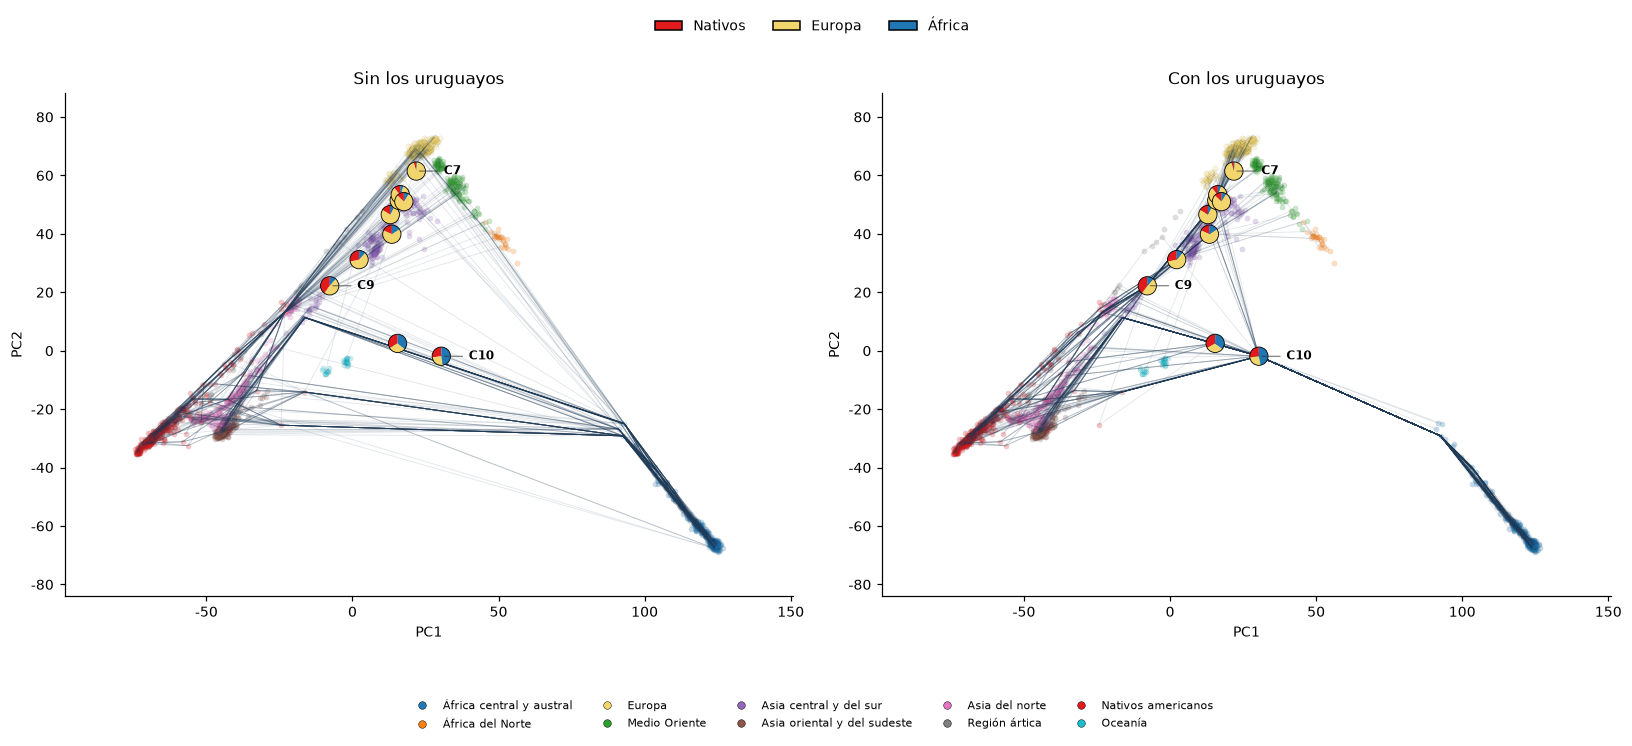

Pares en la muestra: 300
Regiones de los extremos más frecuentes en la muestra:


Nativos americanos – África central y austral             64
Europa – Nativos americanos                               57
Asia oriental y del sudeste – África central y austral    55
Asia del norte – África central y austral                 44
Asia central y del sur – Nativos americanos               23
Medio Oriente – Nativos americanos                        23
Europa – África central y austral                         19
Nativos americanos – África del Norte                      5
Name: count, dtype: int64

In [44]:
# Ilustración de los caminos que pasan por los uruguayos: los mismos pares, sin y con ellos
ALPHA_ILUSTRA, N_CAMINOS = 1.5, 300
_, PR_sin = fermat(ESPACIOS_PC_REF[PC_C10], ALPHA_ILUSTRA, pred=True, guardar=False)
_, PR_con = fermat(ESPACIO_PC50_CON, ALPHA_ILUSTRA, pred=True, guardar=False)
PR_sin, PR_con = np.asarray(PR_sin), np.asarray(PR_con)


def pasa_por_C(PR, i, j):
    k = PR[i, j]
    while k != i and k >= 0:
        if k >= nr:
            return True
        k = PR[i, k]
    return False


# Muestra de pares de referencias, de regiones distintas, cuyo camino con los uruguayos pasa por alguno
rng = np.random.default_rng(SEED)
i_pos, j_pos = np.triu_indices(nr, 1)
pares = []
# Orden aleatorio sin reemplazo: evita pares repetidos y detiene la búsqueda
# cuando alcanza N_CAMINOS (o agota todos los pares posibles).
for k in rng.permutation(len(i_pos)):
    i, j = int(i_pos[k]), int(j_pos[k])
    if reg[i] != reg[j] and pasa_por_C(PR_con, i, j):
        pares.append((i, j))
        if len(pares) >= N_CAMINOS:
            break
if not pares:
    raise ValueError("No hay pares interregionales cuyo camino pase por un uruguayo")
caminos_sin = [camino(PR_sin, i, j) for i, j in pares]
caminos_con = [camino(PR_con, i, j) for i, j in pares]

Z_pca = X_PC_CON[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
for ax, caminos, titulo in ((axes[0], caminos_sin, "Sin los uruguayos"),
                            (axes[1], caminos_con, "Con los uruguayos")):
    nube(ax, Z_pca, reg, titulo, ids_c=C, pies=True, ejes=("PC1", "PC2"))
    for coleccion in ax.collections:          # referencias más tenues, para que se vean los caminos
        coleccion.set_alpha(.25)
    for ruta in caminos:
        ax.plot(Z_pca[ruta, 0], Z_pca[ruta, 1], color="#1f3b57", lw=.6, alpha=.12, zorder=3)
leyenda_regiones(fig, reg, pies=True)
guardar_figura(fig, "U2_caminos_por_uruguayos")

print(f"Pares en la muestra: {len(pares)}")
print("Regiones de los extremos más frecuentes en la muestra:")
display(pd.Series([" – ".join(sorted((reg[i], reg[j]))) for i, j in pares])
        .value_counts().head(8))

### Representaciones con los diez incorporados

Se construyen representaciones MDS y de difusión con los diez uruguayos como nodos del grafo y se evalúan $Q_{NN}$, $Q_{F_{ST}}$ y el error geométrico de ancestría (Figuras 5.23 y 5.24).

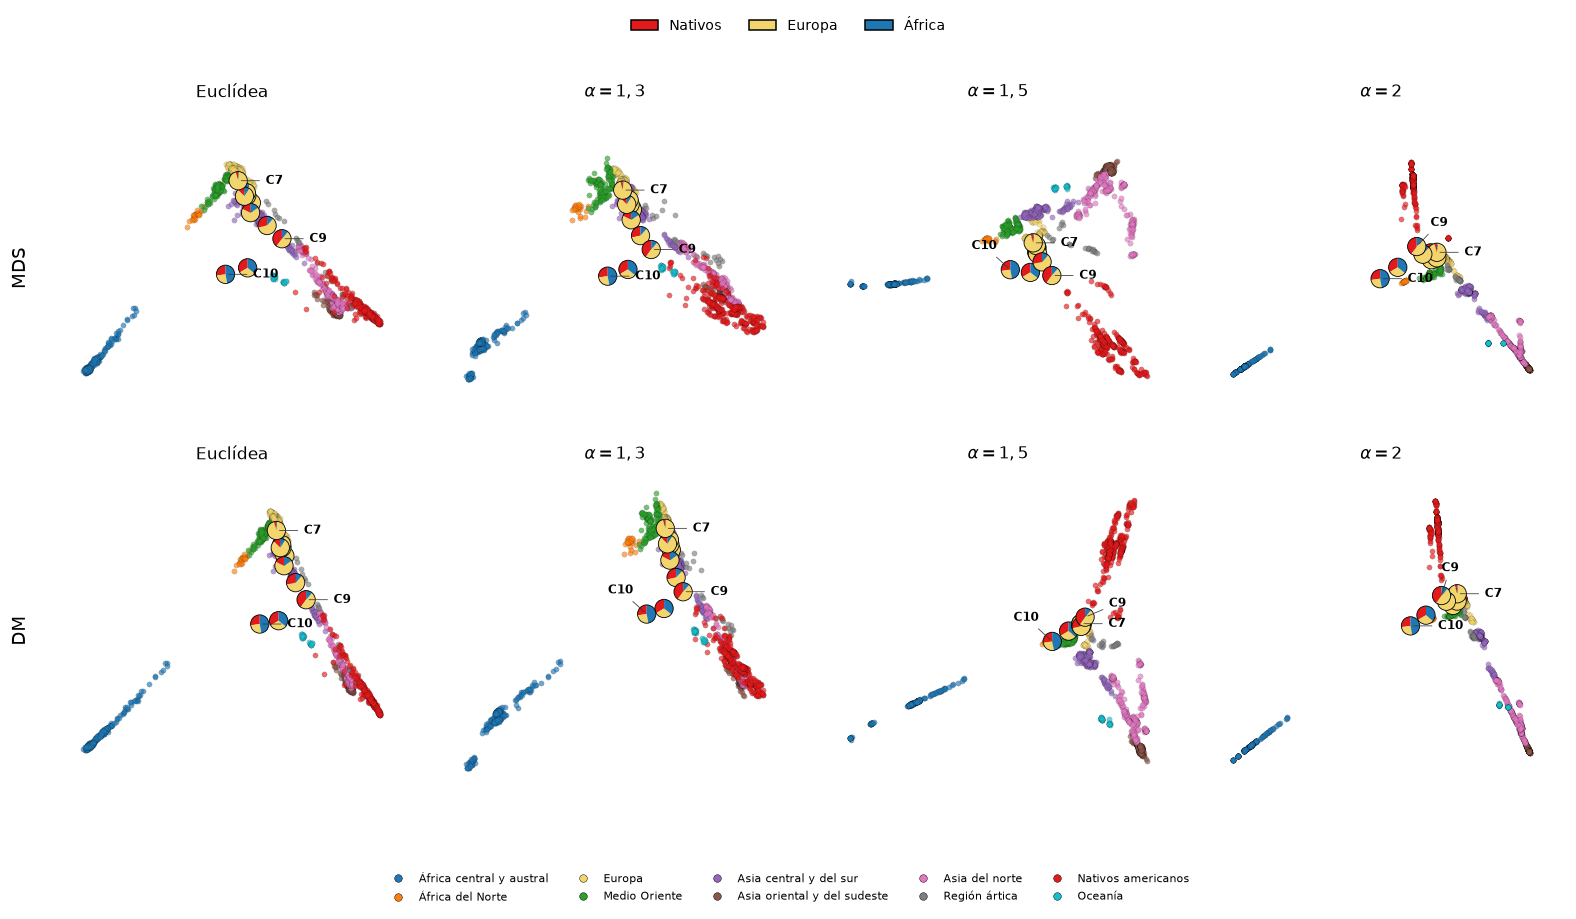

In [45]:
ALPHAS_GAL_PC50_C10 = [1., 1.3, 1.5, 2.]
mapas = {(metodo, a): mapas_fermat(ESPACIOS_PC[PC_C10], a)[metodo]
         for a in ALPHAS_GAL_PC50_C10 for metodo in ("MDS", "DM")}
galeria_tesis(mapas, ALPHAS_GAL_PC50_C10, "U3_galeria_PC50_C10", reg, ids_c=C, pies=True)

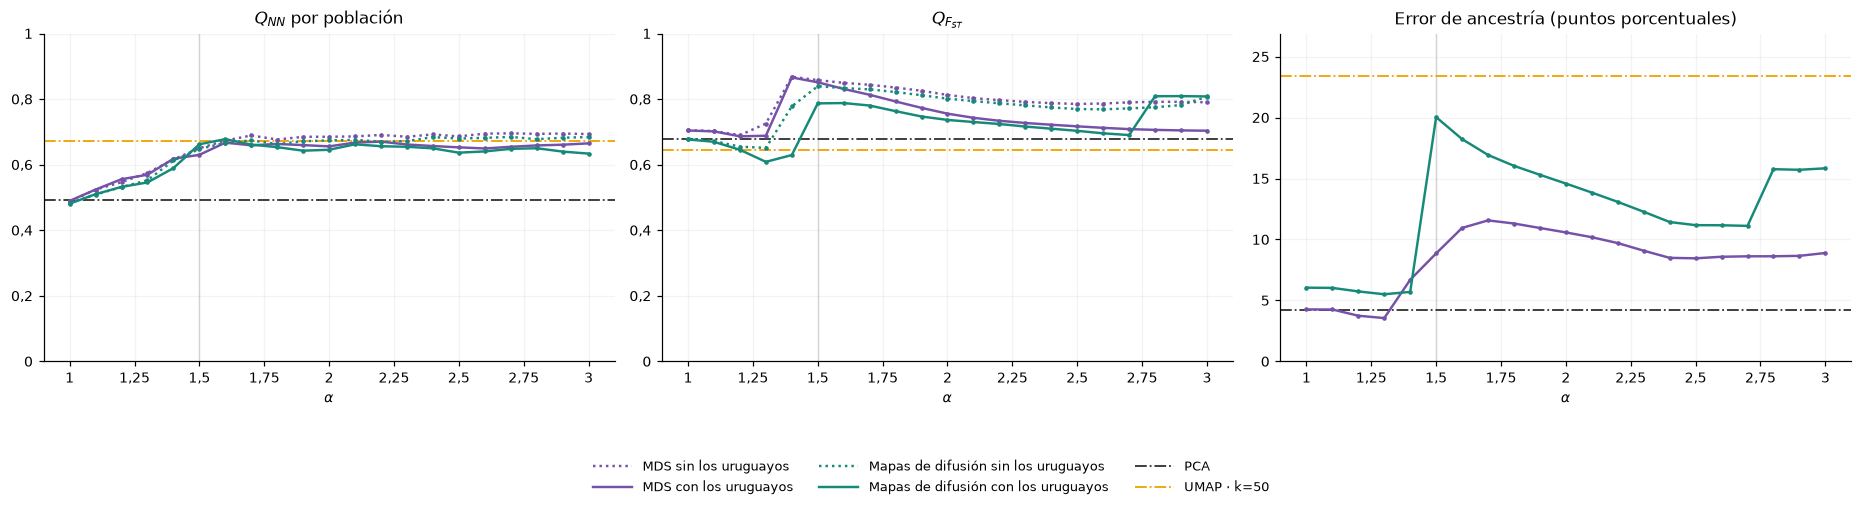

In [46]:
# Figura clave: estructura local, estructura global y mezcla, a lo largo de alpha
PANELES_CLAVE = [("Q_NN_pob", r"$Q_{NN}$ por población"),
                 ("Q_FST", r"$Q_{F_{ST}}$"),
                 ("MAE_ADM_pp", "Error de ancestría (puntos porcentuales)")]
# Nombre del escenario en la tabla -> (texto de la leyenda, tipo de línea)
ESCENARIOS_FIG = {"Sin los diez": ("sin los uruguayos", ":"),
                  "Con los diez": ("con los uruguayos", "-"),
                  "Proyección afín": ("con proyección afín", "--")}
NOMBRE_METODO = {"MDS": "MDS", "DM": "Mapas de difusión"}


def figura_clave(MET, escenarios, nombre, xlim=(1, 3), alpha_marcado=1.5):
    fig, axes = plt.subplots(1, len(PANELES_CLAVE), figsize=(17, 4.6))
    for ax, (columna, titulo) in zip(axes, PANELES_CLAVE):
        de_mezcla = columna == "MAE_ADM_pp"
        ax.axvline(alpha_marcado, color="0.85", lw=.9, zorder=0)
        for metodo in ("MDS", "DM"):
            for escenario in escenarios:
                # En las métricas de estructura, la proyección afín coincide con el mapa sin los diez
                if not de_mezcla and escenario == "Proyección afín":
                    continue
                g = MET[MET.metodo.eq(metodo) & MET.escenario.eq(escenario)
                        & MET.alpha.between(*xlim)].sort_values("alpha")
                if g[columna].notna().any():
                    ax.plot(g.alpha, g[columna], ls=ESCENARIOS_FIG[escenario][1], marker=".", ms=4,
                            lw=1.6, color=COLORES_METODO[metodo], clip_on=False, zorder=3)
        controles = CONTROL_C10 if de_mezcla else CONTROL_REF.iloc[[0, 2]]   # PCA y UMAP k=50
        for k, (_, fila) in enumerate(controles.iterrows()):
            ax.axhline(fila[columna], color=COLORES_CONTROL[k], ls="-.", lw=1.2, zorder=2)
        if de_mezcla:
            valores = np.concatenate([MET[columna].to_numpy(dtype=float),
                                      controles[columna].to_numpy(dtype=float)])
            ax.set_ylim(0, 1.15*np.nanmax(valores))
        else:
            ax.set_ylim(0, 1)
        ax.set(title=titulo, xlabel=r"$\alpha$")
        coma(ax)
        ax.grid(alpha=.15)
    # Una entrada por combinación de método y escenario, más las referencias
    handles = [Line2D([], [], color=COLORES_METODO[m], ls=ESCENARIOS_FIG[e][1], lw=1.6,
                      label=f"{NOMBRE_METODO[m]} {ESCENARIOS_FIG[e][0]}")
               for m in ("MDS", "DM") for e in escenarios]
    handles += [Line2D([], [], color=COLORES_CONTROL[0], ls="-.", lw=1.2, label="PCA"),
                Line2D([], [], color=COLORES_CONTROL[1], ls="-.", lw=1.2, label="UMAP · k=50")]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False,
               handlelength=3)
    fig.tight_layout(rect=[0, .16, 1, 1])
    guardar_figura(fig, nombre)


figura_clave(MET_C10, ["Sin los diez", "Con los diez"], "U3_clave_sin_con")

### Proyección afín

Se mantiene el mapa de las referencias y se extiende a C1–C10 mediante una transformación afín ajustada por mínimos cuadrados. Se contrasta el ajuste con 470 referencias reservadas, sin excluirlas de la construcción del mapa. Se comparan los tres escenarios y los errores de ancestría (Figuras 5.25–5.28).

In [47]:
# Validación de la transformación y comparación con alpha = 1,5
ETIQUETA_ESCENARIO = {"Sin los diez": "sin los uruguayos", "Con los diez": "con los uruguayos",
                      "Proyección afín": "con proyección afín"}
ETIQUETA_CONTROL = {"PCA · con C1–C10": "PCA",
                    "UMAP · k=50 · con C1–C10": "UMAP · k=50"}

print("Validación de la transformación afín sobre las referencias reservadas:")
display(VALIDACION_AFIN[np.isclose(VALIDACION_AFIN.alpha, ALPHA_C10)]
        [["metodo", "n_train", "n_validacion", "MSE_relativo", "RMSE_relativo"]].round(5))

COLS_U4 = ["Q_NN_pob", "Q_FST", "MAE_ADM_pp", "MAE_Nativos_pp", "MAE_Europa_pp",
           "MAE_África_pp", "C_fuera_triangulo"]
filas = [{"representacion": ETIQUETA_CONTROL[f.control], **{c: f[c] for c in COLS_U4}}
         for _, f in CONTROL_C10.iterrows()]
for _, f in MET_C10[np.isclose(MET_C10.alpha, ALPHA_C10)].iterrows():
    filas.append({"representacion": f"{NOMBRE_METODO[f.metodo]} {ETIQUETA_ESCENARIO[f.escenario]}",
                  **{c: f[c] for c in COLS_U4}})
COMPARACION_U4 = tabla(pd.DataFrame(filas), "U4_comparacion_alpha_1_5")
print(f"Comparación con alpha = {ALPHA_C10:g}:")
display(COMPARACION_U4.round(3))

print("Proyección afín a lo largo de alpha:")
for metodo, g in MET_C10[MET_C10.escenario.eq("Proyección afín")].groupby("metodo"):
    print(f"  {NOMBRE_METODO[metodo]}: error de ancestría entre {g.MAE_ADM_pp.min():.2f} y "
          f"{g.MAE_ADM_pp.max():.2f} pp; máximo de uruguayos fuera del triángulo: "
          f"{g.C_fuera_triangulo.max():g}")

Validación de la transformación afín sobre las referencias reservadas:


,metodo,n_train,n_validacion,MSE_relativo,RMSE_relativo
10,MDS,1713,470,0.00170,0.04124
11,DM,1713,470,0.00146,0.03815


Comparación con alpha = 1.5:


,representacion,Q_NN_pob,Q_FST,MAE_ADM_pp,MAE_Nativos_pp,MAE_Europa_pp,MAE_África_pp,C_fuera_triangulo
0,PCA,0.491,0.677,4.177,1.160,5.318,6.052,0.0
1,UMAP · k=50,0.691,0.527,23.389,30.811,24.147,15.210,5.0
2,MDS sin los uruguayos,0.650,0.858,NaN,NaN,NaN,NaN,NaN
3,MDS con los uruguayos,0.630,0.851,8.858,5.227,13.253,8.092,0.0
4,MDS con proyección afín,0.650,0.858,3.961,1.197,5.031,5.656,0.0
5,Mapas de difusión sin los uruguayos,0.648,0.839,NaN,NaN,NaN,NaN,NaN
6,Mapas de difusión con los uruguayos,0.662,0.787,20.036,18.419,29.982,11.707,3.0
7,Mapas de difusión con proyección afín,0.648,0.839,4.400,1.222,5.685,6.292,0.0


Proyección afín a lo largo de alpha:
  Mapas de difusión: error de ancestría entre 4.36 y 5.17 pp; máximo de uruguayos fuera del triángulo: 0
  MDS: error de ancestría entre 3.82 y 4.59 pp; máximo de uruguayos fuera del triángulo: 0


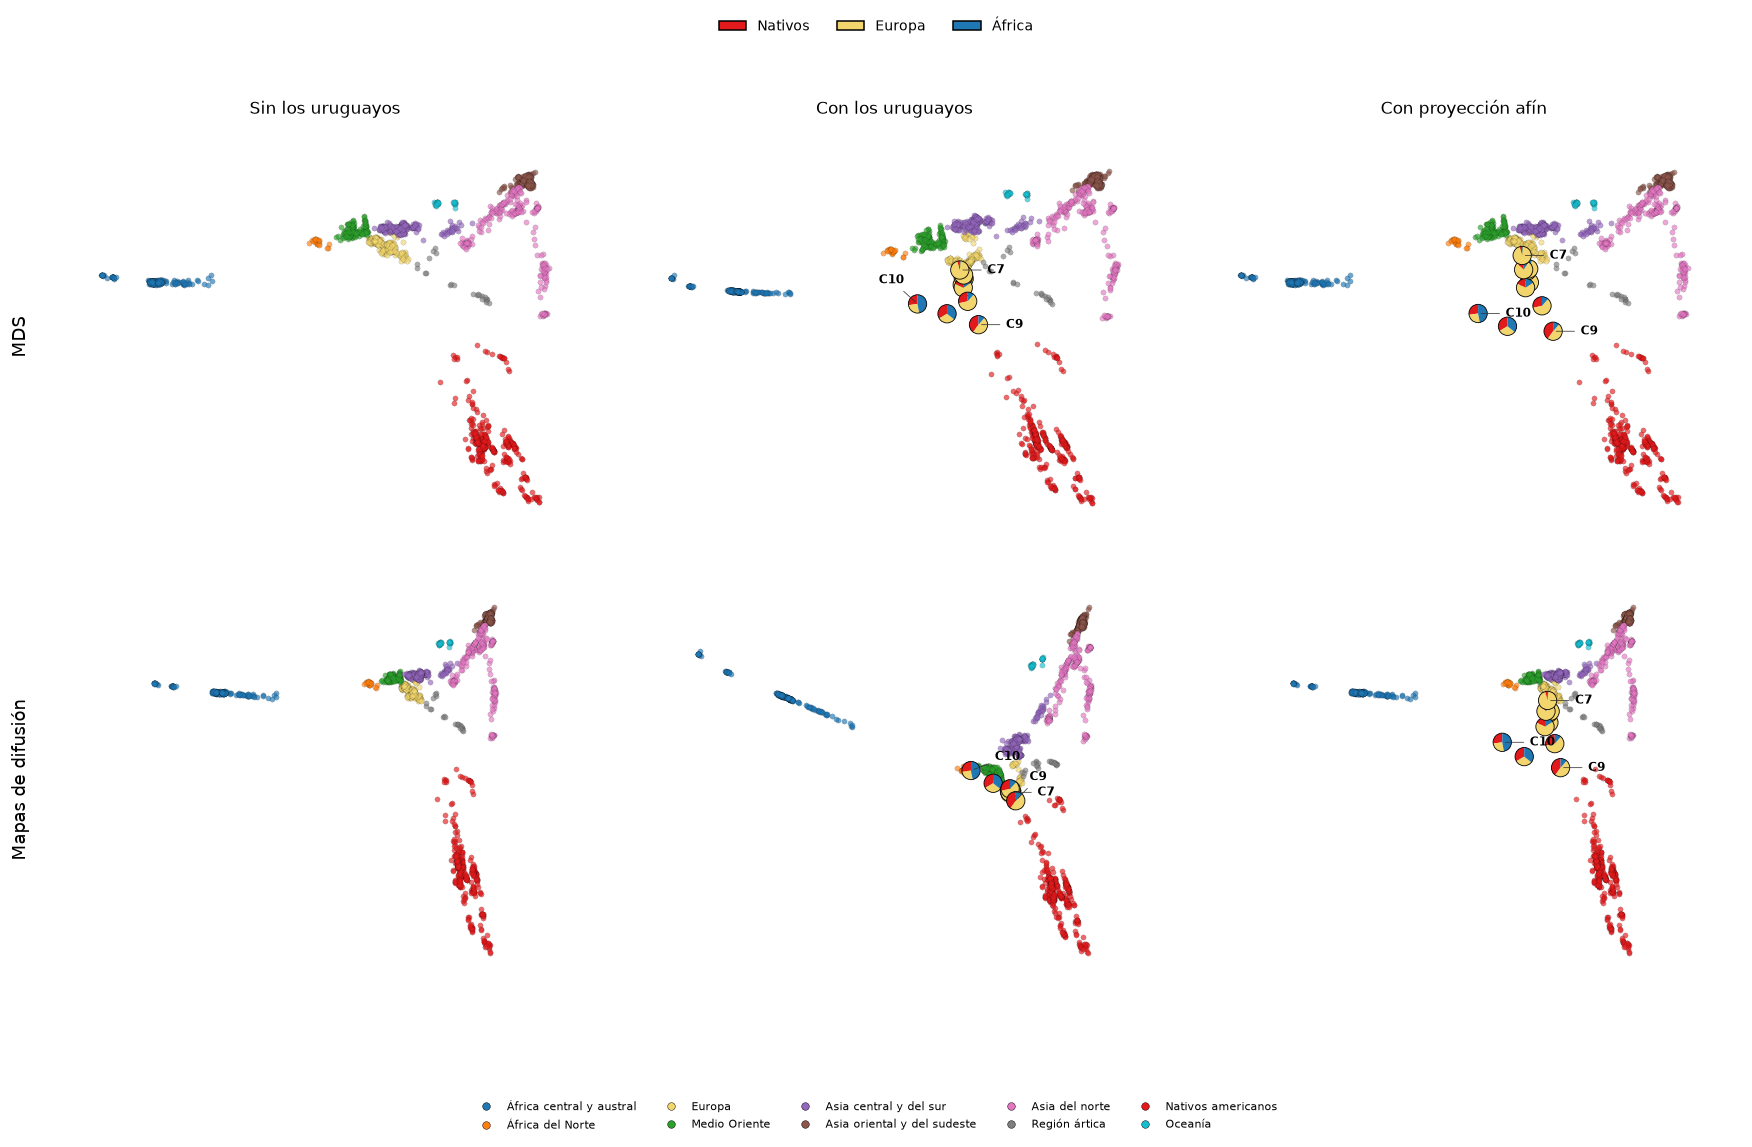

In [48]:
# Los tres escenarios con alpha = 1,5
MAPAS_PRINCIPALES, MODELOS_AFIN = mapas_C10(ALPHA_C10)


def alinear_por_referencias(Z, Zref):
    # Rota Z para que sus referencias coincidan lo más posible con las de Zref (sólo afecta al dibujo)
    centro, centro_ref = Z[:nr].mean(0), Zref[:nr].mean(0)
    rotacion, _ = orthogonal_procrustes(Z[:nr] - centro, Zref[:nr] - centro_ref)
    return (Z - centro) @ rotacion + centro_ref


fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for fila, metodo in enumerate(("MDS", "DM")):
    base = MAPAS_PRINCIPALES[(metodo, "Sin los diez")]
    for col, escenario in enumerate(ESCENARIOS):
        Z = MAPAS_PRINCIPALES[(metodo, escenario)]
        if escenario == "Con los diez":
            Z = alinear_por_referencias(Z, base)
        con_C = len(Z) == n
        titulo = ETIQUETA_ESCENARIO[escenario].capitalize() if fila == 0 else ""
        nube(axes[fila, col], Z, reg if con_C else reg[:nr], titulo,
             ids_c=C if con_C else None, pies=con_C, ejes=("", ""))
        sin_ejes(axes[fila, col])
    axes[fila, 0].set_ylabel(NOMBRE_METODO[metodo], fontsize=12, labelpad=12)
leyenda_regiones(fig, reg, pies=True)
guardar_figura(fig, "U4_escenarios_C10")

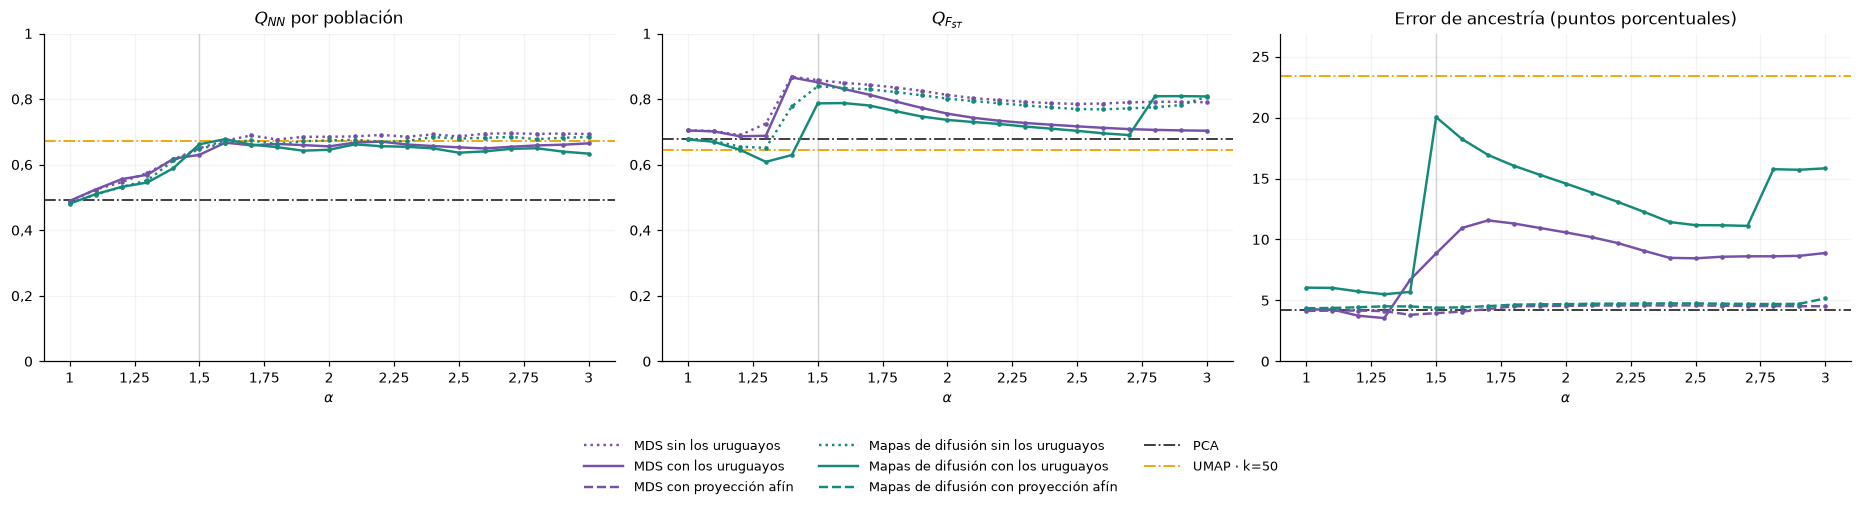

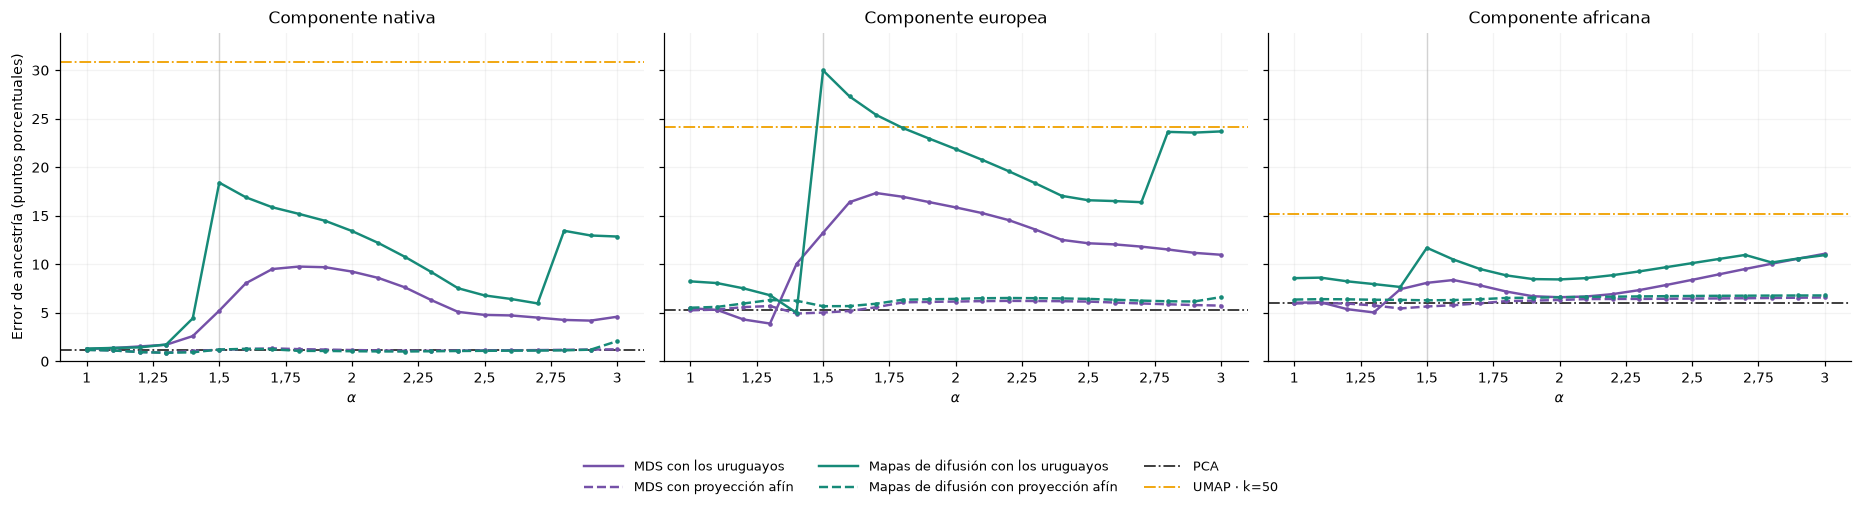

In [49]:
# Métricas a lo largo de alpha: estructura y error de ancestría, global y por componente
figura_clave(MET_C10, ["Sin los diez", "Con los diez", "Proyección afín"], "U4_clave_tres_escenarios")

COMPONENTES_MAE = [("MAE_Nativos_pp", "Componente nativa"),
                   ("MAE_Europa_pp", "Componente europea"),
                   ("MAE_África_pp", "Componente africana")]
ESCENARIOS_MEZCLA = ["Con los diez", "Proyección afín"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, (columna, titulo) in zip(axes, COMPONENTES_MAE):
    ax.axvline(ALPHA_C10, color="0.85", lw=.9, zorder=0)
    for metodo in ("MDS", "DM"):
        for escenario in ESCENARIOS_MEZCLA:
            g = MET_C10[MET_C10.metodo.eq(metodo) & MET_C10.escenario.eq(escenario)].sort_values("alpha")
            ax.plot(g.alpha, g[columna], ls=ESCENARIOS_FIG[escenario][1], marker=".", ms=4, lw=1.6,
                    color=COLORES_METODO[metodo], clip_on=False, zorder=3)
    for k, (_, fila) in enumerate(CONTROL_C10.iterrows()):
        ax.axhline(fila[columna], color=COLORES_CONTROL[k], ls="-.", lw=1.2, zorder=2)
    ax.set(title=titulo, xlabel=r"$\alpha$")
    coma(ax)
    ax.grid(alpha=.15)
valores = np.concatenate([MET_C10[[c for c, _ in COMPONENTES_MAE]].to_numpy(dtype=float).ravel(),
                          CONTROL_C10[[c for c, _ in COMPONENTES_MAE]].to_numpy(dtype=float).ravel()])
axes[0].set_ylim(0, 1.1*np.nanmax(valores))
axes[0].set_ylabel("Error de ancestría (puntos porcentuales)")
handles = [Line2D([], [], color=COLORES_METODO[m], ls=ESCENARIOS_FIG[e][1], lw=1.6,
                  label=f"{NOMBRE_METODO[m]} {ESCENARIOS_FIG[e][0]}")
           for m in ("MDS", "DM") for e in ESCENARIOS_MEZCLA]
handles += [Line2D([], [], color=COLORES_CONTROL[0], ls="-.", lw=1.2, label="PCA"),
            Line2D([], [], color=COLORES_CONTROL[1], ls="-.", lw=1.2, label="UMAP · k=50")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False, handlelength=3)
fig.tight_layout(rect=[0, .16, 1, 1])
guardar_figura(fig, "U4_ancestria_componentes")

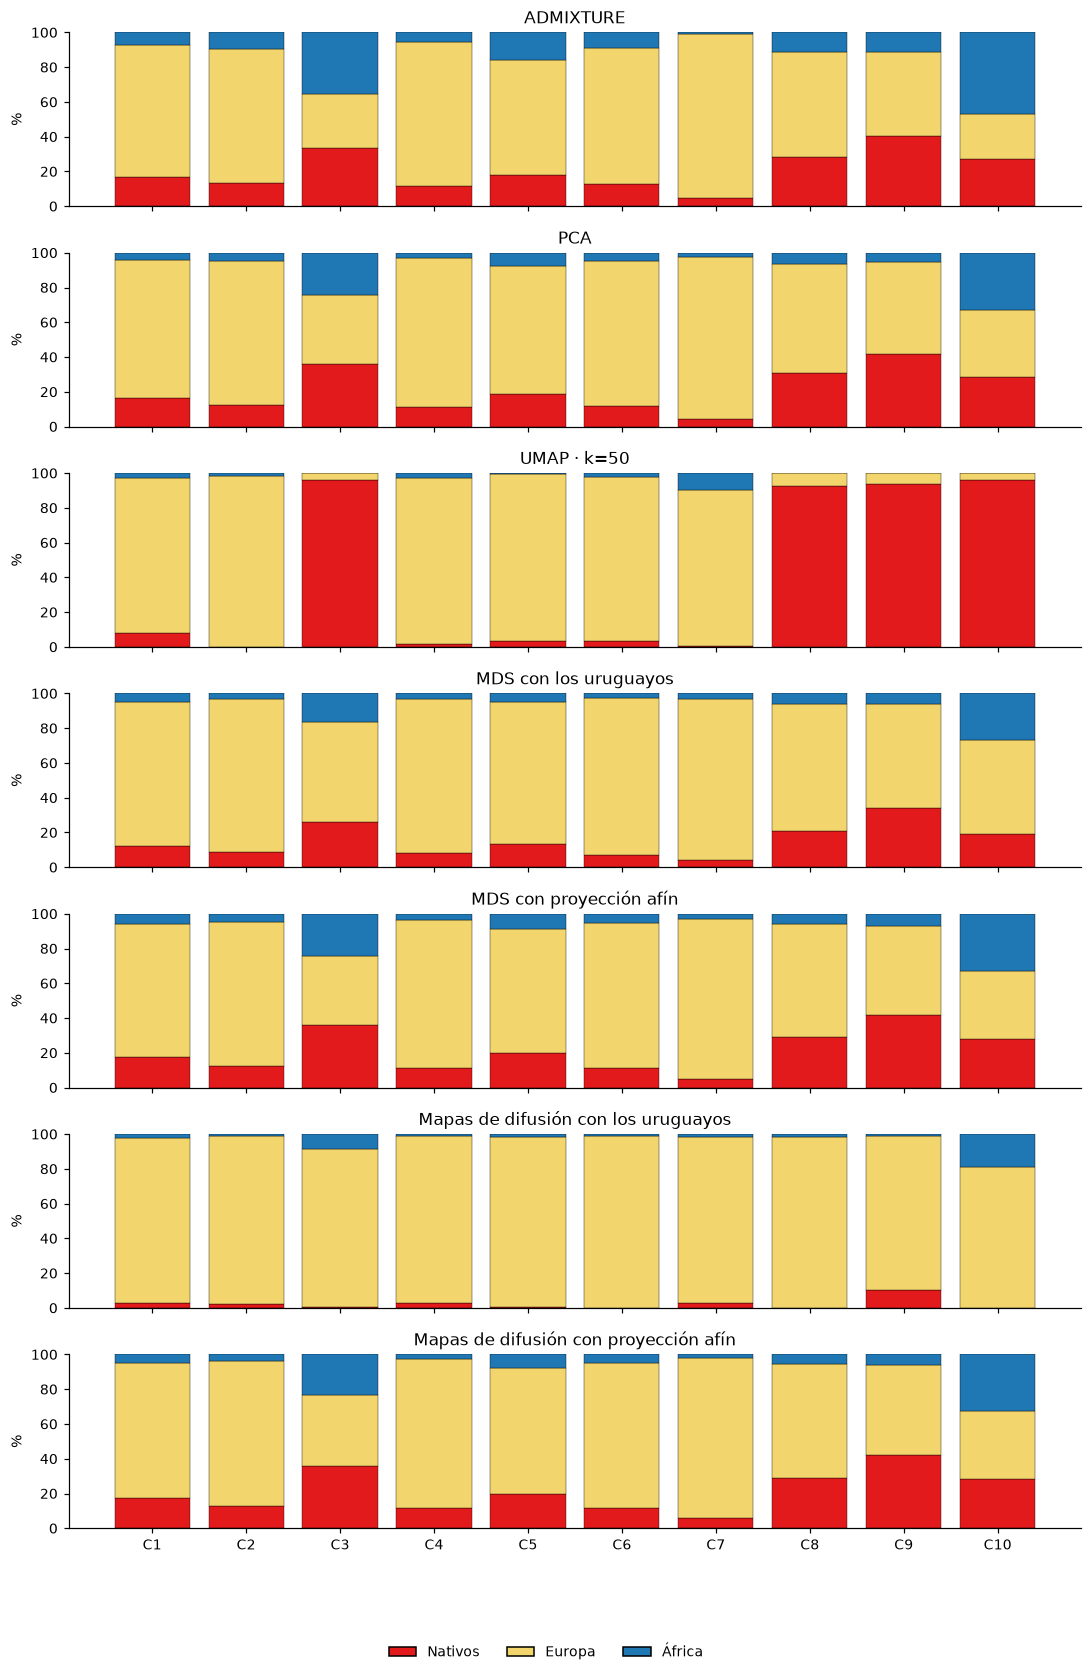

In [50]:
paneles = {"ADMIXTURE": Q_ADM, "PCA": Q_CONTROLES["PCA · con C1–C10"],
           "UMAP · k=50": Q_CONTROLES["UMAP · k=50 · con C1–C10"]}
for (metodo, escenario), Z in MAPAS_PRINCIPALES.items():
    if escenario != "Sin los diez":
        paneles[f"{NOMBRE_METODO[metodo]} {ETIQUETA_ESCENARIO[escenario]}"] = evaluar_ancestria(Z)[2]
barras_proporciones(paneles, "U4_porcentajes_vs_ADMIXTURE")

# Coordenadas y coeficientes, para reproducir las figuras sin recalcular
for (metodo, escenario), Z in MAPAS_PRINCIPALES.items():
    slug = escenario.replace(" ", "_")
    np.savez_compressed(COORDENADAS/f"C10_{metodo}_{slug}.npz", Z=Z,
                        id=et.id.to_numpy(str)[:len(Z)], IID=et.IID.to_numpy(str)[:len(Z)])
for metodo, modelo in MODELOS_AFIN.items():
    np.savez(COORDENADAS/f"C10_coeficientes_afin_{metodo}.npz", **modelo)
escribir_json({"componentes": COMPONENTES, "proporciones_ADMIXTURE": PROP_ADMIXTURE,
               "colores_regiones": COLORES, "fuentes_geometricas": REG_FUENTE},
              SALIDA/"convenciones.json")

## 8. Resultados complementarios (anexos)

Se generan las figuras adicionales de los Apéndices C.2, C.3 y C.4. No se incluyen métricas exploratorias descartadas en la versión final de la tesis.

### Apéndice C.2. Caminos para exponentes mayores

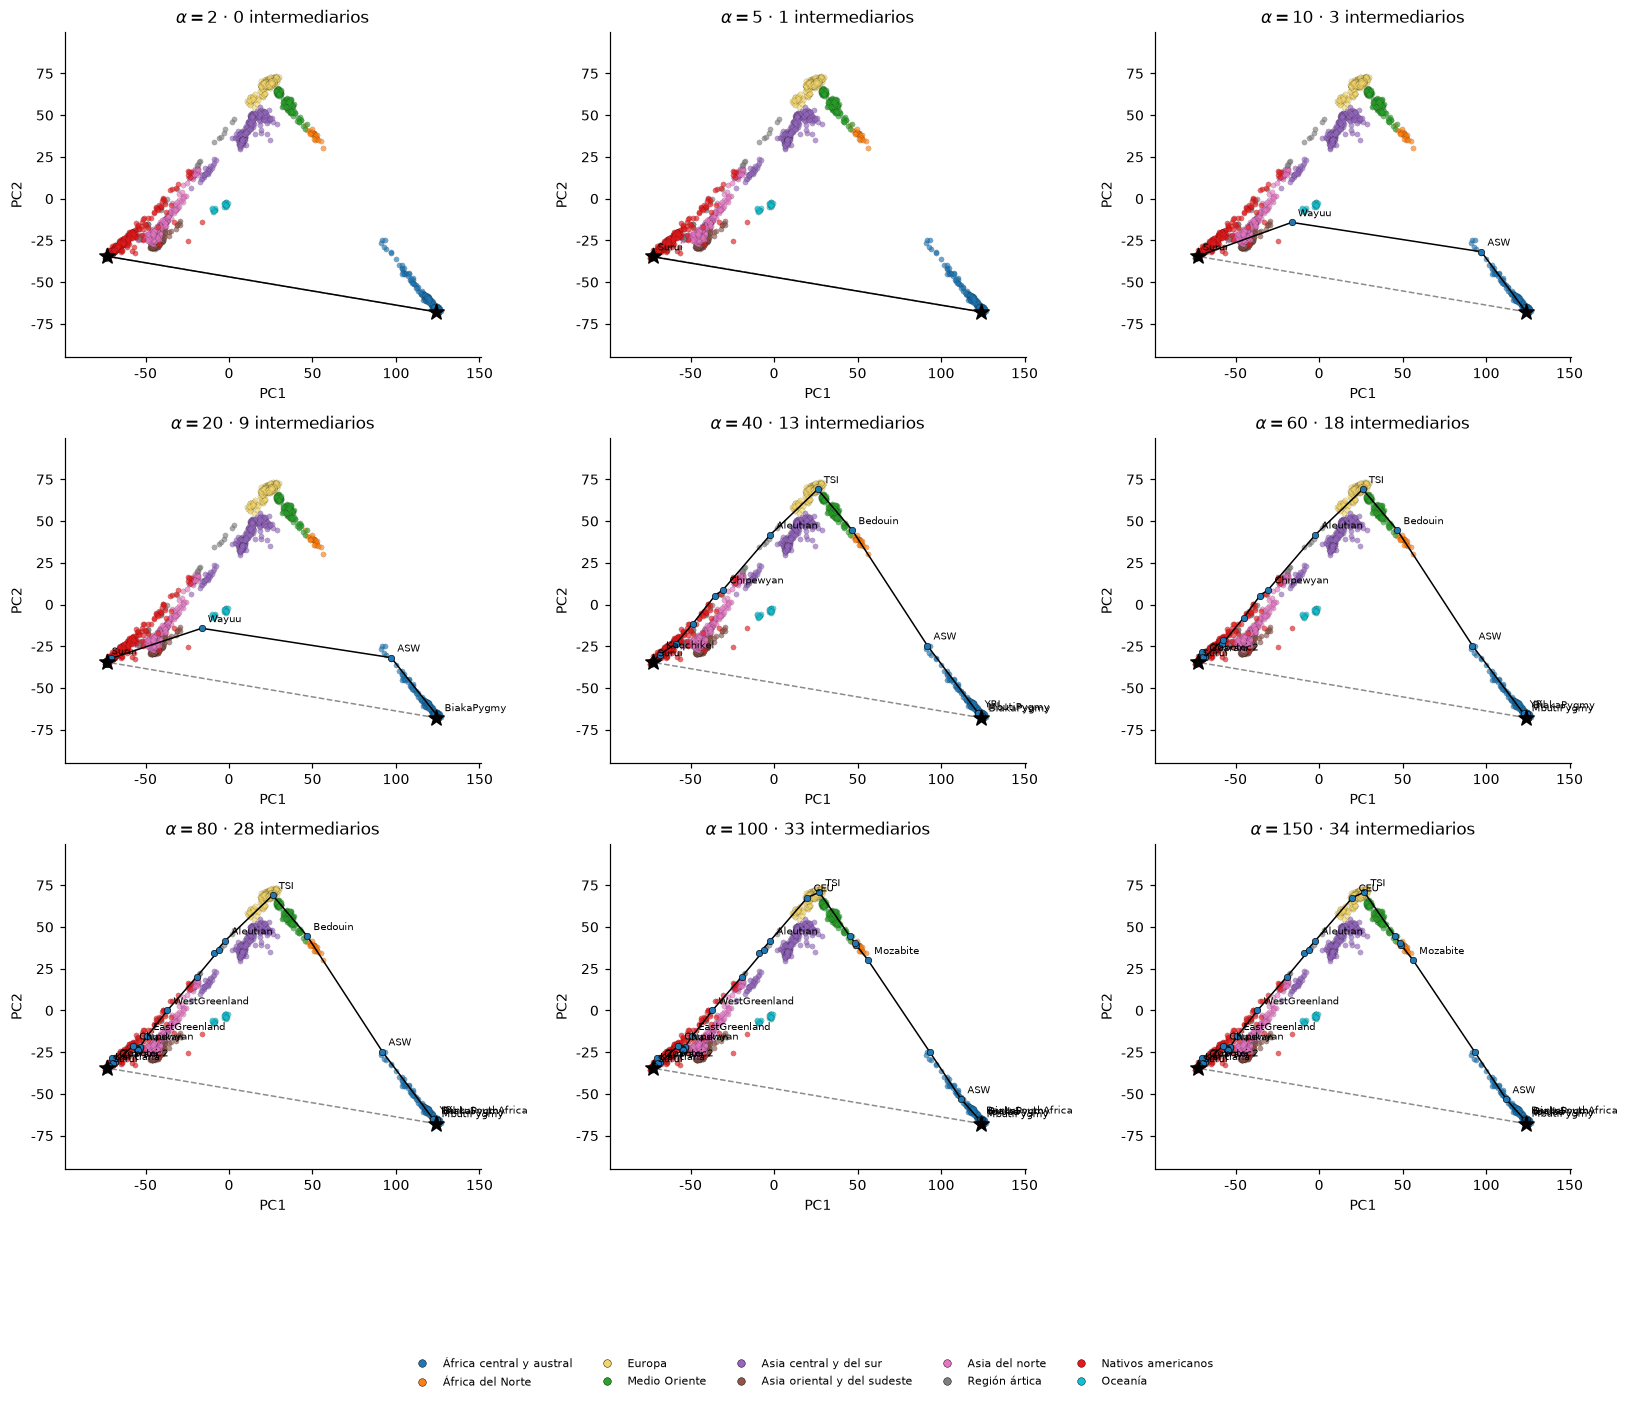

In [51]:
# Figura C.2: mismo par MbutiPygmy–Surui, sobre genotipos originales
ALPHAS_C2 = (2., 5., 10., 20., 40., 60., 80., 100., 150.)
fig, axes = plt.subplots(3, 3, figsize=(15, 13.5), squeeze=False)
for ax, alpha in zip(axes.flat, ALPHAS_C2):
    ruta, costo, directo = camino_un_par(ESPACIO_REF, alpha, *EXTREMOS_RUTA)
    nube(ax, X_PC[R, :2], reg[:nr],
         texto_alpha(alpha) + f" · {len(ruta)-2} intermediarios", ejes=("PC1", "PC2"))
    dibujar_ruta(ax, X_PC[R, :2], ruta, pob[:nr])
leyenda_regiones(fig, reg[:nr])
guardar_figura(fig, "Anexo_caminos_PCA_alfas_grandes")

### Apéndice C.3. Otros truncamientos PCA

Se comparan los seis valores de $q$ utilizados en Metodología. Para cada espacio se selecciona el exponente de máxima correspondencia global de MDS sobre la grilla estudiada; se muestra también la configuración euclídea y $\alpha=2$.

,espacio,alpha_ref,alpha_optimo,alpha_sobre_referencia,Q_FST,Q_NN_pob
0,Genotipos,7.283,20.0,2.746,0.838,0.444
1,PC20,1.024,1.2,1.172,0.872,0.593
2,PC30,1.033,1.3,1.259,0.865,0.660
3,PC50,1.081,1.4,1.295,0.868,0.616
4,PC80,1.224,1.7,1.389,0.865,0.537
5,PC100,1.312,1.9,1.448,0.860,0.496
6,PC150,1.520,2.1,1.381,0.728,0.491


PC20: listo
PC30: listo
PC50: listo
PC80: listo
PC100: listo
PC150: listo


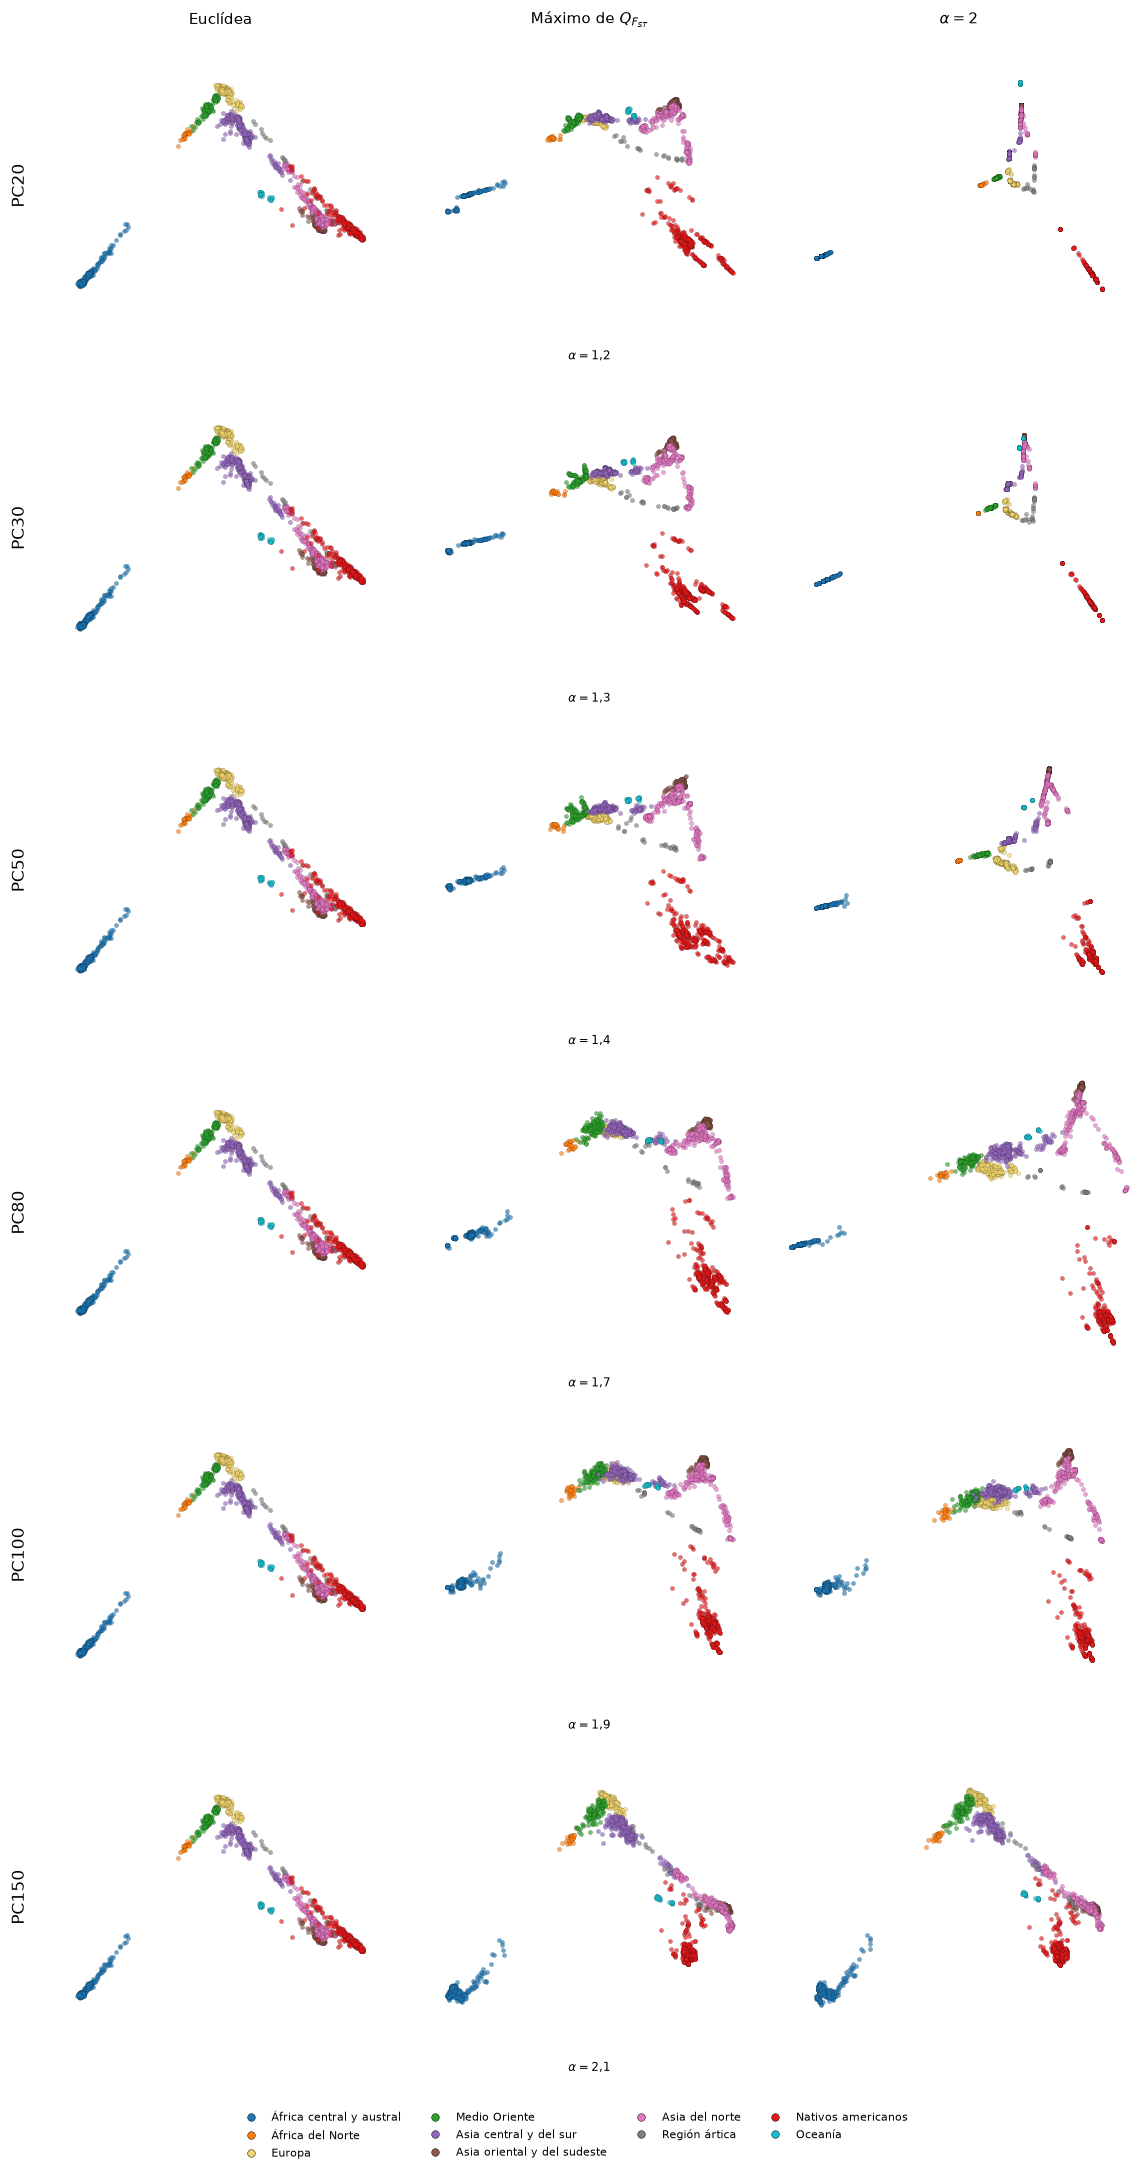

In [52]:
# Figura C.3 y cuadro complementario: sólo Q_NN y Q_FST
MET_ESPACIOS = {50: MET_PC50}
for q in PCS_LISTA:
    if q == 50:
        continue
    MET_ESPACIOS[q] = barrer_mapas(ESPACIOS_PC_REF[q], ALPHAS_FINO, CTX_REF,
                                 f"A_barrido_PC{q}", f"PC{q} referencias")

filas = []
# El Cuadro C.1 incluye también el panel de genotipos, usado como referencia.
for nombre, g in [("Genotipos", MET_REF)] + [
        (f"PC{q}", MET_ESPACIOS[q]) for q in PCS_LISTA]:
    g = g[g.metodo == "MDS"]
    mejor = g.loc[g.Q_FST.idxmax()]
    alpha_ref = float(GEOMETRIA_PC.loc[
        GEOMETRIA_PC.espacio.eq(nombre), "alpha_rho_mediana"].iloc[0])
    filas.append({"espacio": nombre, "alpha_ref": alpha_ref,
                  "alpha_optimo": float(mejor.alpha),
                  "alpha_sobre_referencia": float(mejor.alpha)/alpha_ref,
                  "Q_FST": float(mejor.Q_FST),
                  "Q_NN_pob": float(mejor.Q_NN_pob)})
RESUMEN_ESPACIOS = tabla(pd.DataFrame(filas), "A_resumen_truncamientos")
display(RESUMEN_ESPACIOS.round(3))

regiones_prueba = np.asarray(reg[:nr])
columnas = ["Euclídea", r"Máximo de $Q_{F_{ST}}$", r"$\alpha=2$"]
fig, axes = plt.subplots(len(PCS_LISTA), 3, figsize=(10.5, 3.3*len(PCS_LISTA)), squeeze=False)
for fila, q in enumerate(sorted(PCS_LISTA)):
    alpha_mejor = float(RESUMEN_ESPACIOS.set_index("espacio").loc[
        f"PC{q}", "alpha_optimo"])
    base = mapas_fermat(ESPACIOS_PC_REF[q], 1.)["MDS"]
    for col, alpha in enumerate((1., alpha_mejor, 2.)):
        ax = axes[fila, col]
        Z = alinear_prueba(mapas_fermat(ESPACIOS_PC_REF[q], alpha)["MDS"], base)
        for nombre_region in ORDEN_REGIONES:
            sel = regiones_prueba == nombre_region
            if sel.any():
                ax.scatter(Z[sel, 0], Z[sel, 1], s=8, c=COLORES[nombre_region], alpha=.65,
                           linewidths=.10, edgecolors="black", zorder=2, rasterized=True)
        if fila == 0:
            ax.set_title(columnas[col], fontsize=10)
        if col == 1:
            ax.text(.5, -.04, rf"$\alpha={alpha:g}$".replace(".", "{,}"),
                    transform=ax.transAxes, ha="center", va="top", fontsize=8)
        ax.margins(.12)
        ax.set_aspect("equal", adjustable="datalim")
        ax.set_xticks([]); ax.set_yticks([])
        for lado in ("top", "right", "bottom", "left"):
            ax.spines[lado].set_visible(False)
    axes[fila, 0].set_ylabel(f"PC{q}", fontsize=11, labelpad=10)
    print(f"PC{q}: listo", flush=True)
handles = [Line2D([], [], marker="o", ls="", markersize=5, color=COLORES[r],
                  markeredgecolor="black", markeredgewidth=.3, label=r)
           for r in ORDEN_REGIONES if r in set(regiones_prueba)]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, .002),
           ncol=4, fontsize=7.5, frameon=False)
fig.tight_layout(rect=[0, .04, 1, 1])
guardar_figura(fig, "A_representaciones_truncamientos")

### Apéndice C.4. Resultados adicionales sobre los uruguayos

Se presenta su frecuencia como intermediarios, los caminos y las representaciones sobre los genotipos originales, el cuadro de métricas y el acercamiento de MDS con proyección afín.
Se exportan además los acercamientos de **MDS** y **DM** para comparar incorporación directa y proyección afín, sin cambiar las representaciones del cuerpo de la tesis.


,espacio,alpha,pares_con_C,pares_con_C_pct
0,Genotipos,6.0,6186,0.260
1,Genotipos,10.0,519834,21.827
2,Genotipos,16.0,608945,25.568
3,Genotipos,20.0,653537,27.440
4,PC50,1.3,240570,10.101
5,PC50,1.5,590475,24.793
6,PC50,2.0,807096,33.888


espacio Genotipos                           PC50                
alpha        6.0     10.0    16.0    20.0   1.3     1.5     2.0 
id                                                              
C1           0.00   0.000   0.000   0.001  0.315   1.227   0.730
C2           0.00   0.000   0.008   0.030  2.003   4.357   8.564
C3           0.00   0.007   0.000   0.000  2.114   1.952  18.618
C4           0.00   0.000   0.001   0.001  0.025   0.242   0.142
C5           0.00   0.000   0.000   0.000  0.700   2.006   5.756
C6           0.00   0.000   0.000   0.014  0.004   0.096   0.090
C7           0.00   0.000   0.000   0.030  0.000   0.014   0.416
C8           0.00   0.000   0.001   0.014  1.294   1.982   9.189
C9           0.00   0.080   2.059   3.525  3.863   7.245  11.579
C10          0.26  21.740  23.499  23.837  1.674  15.229  22.052

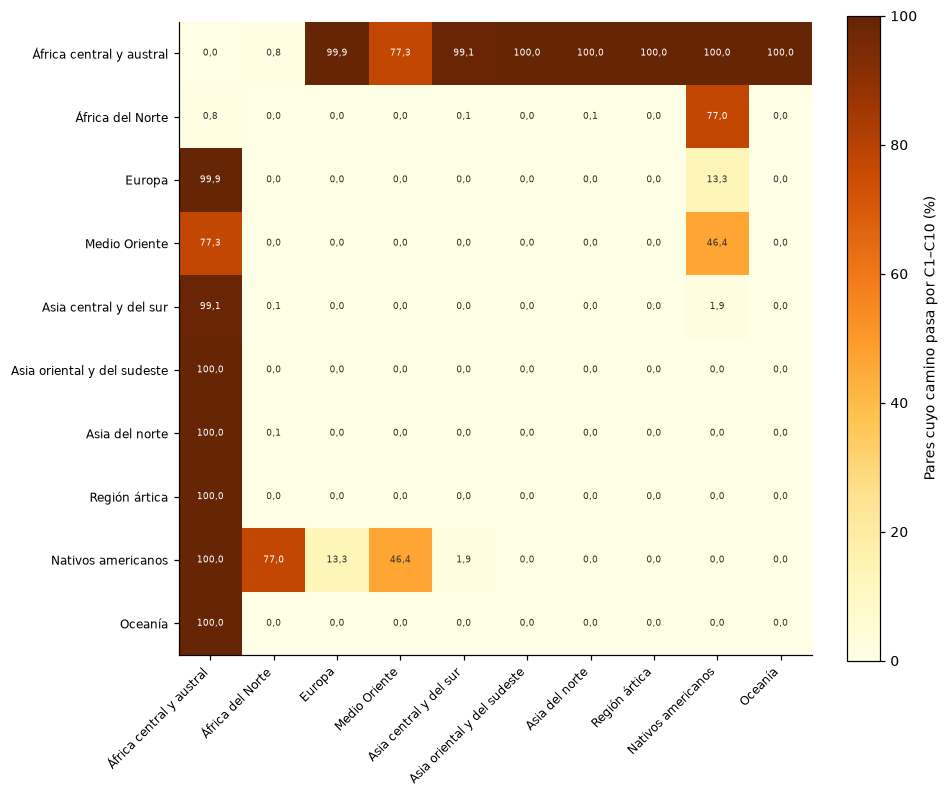

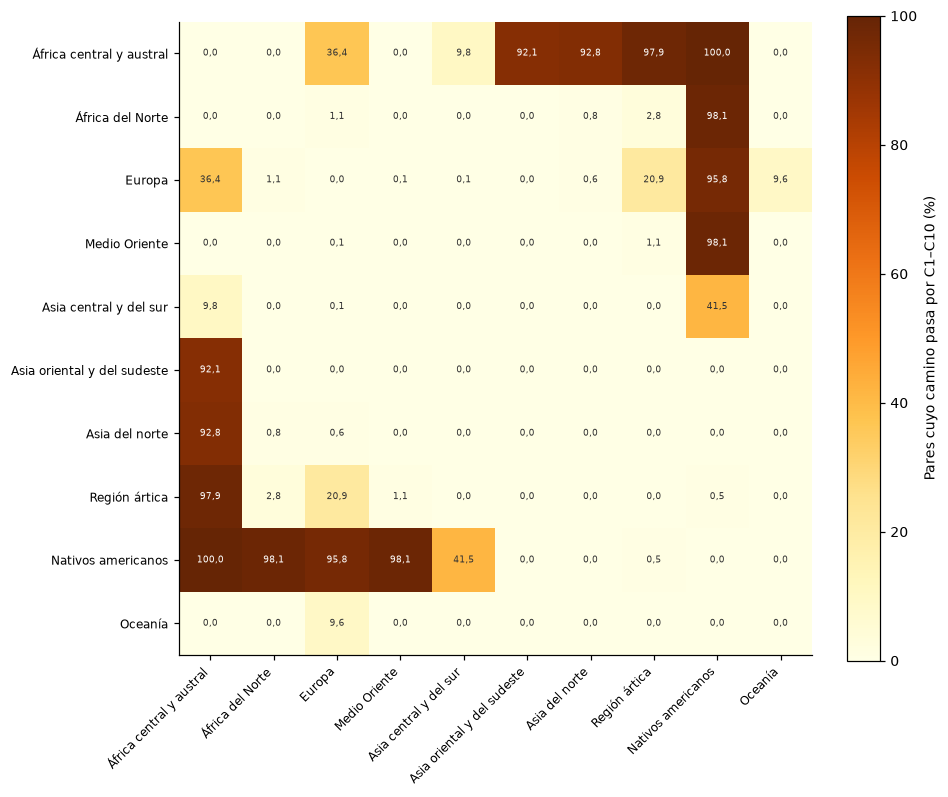

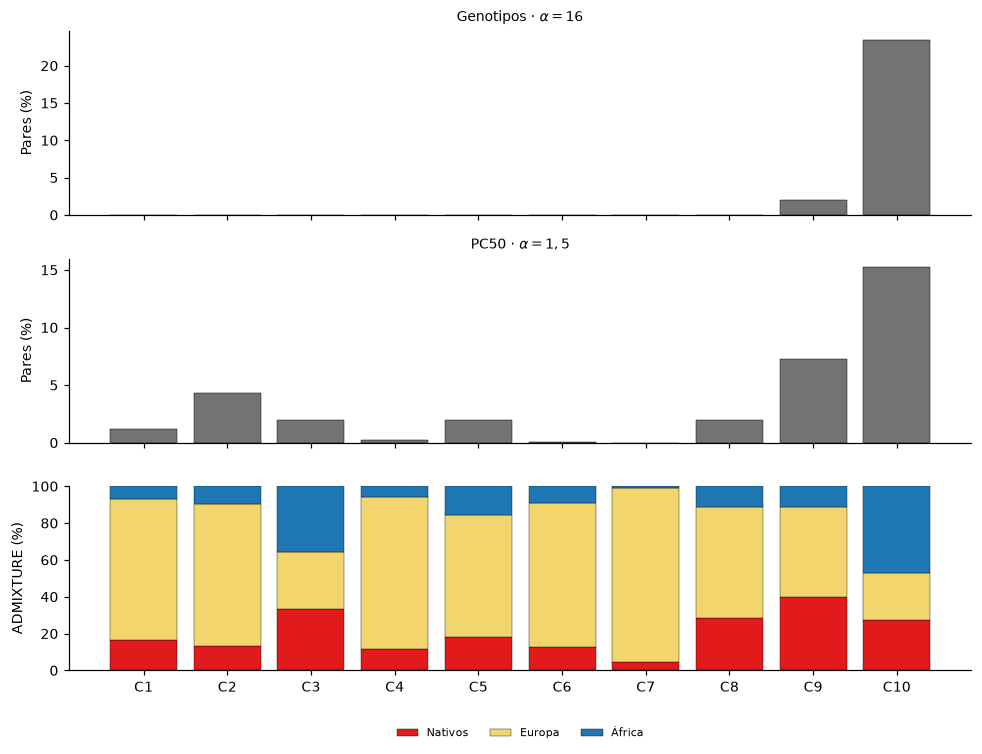

In [53]:
ESPACIO_GEN_C10 = definir_espacio(D, "Genotipos · referencias + C1–C10")
CONFIG_CAMINOS = [("Genotipos", ESPACIO_GEN_C10, [6., 10., 16., 20.]),
                  ("PC50", ESPACIOS_PC[PC_C10], [1.3, 1.5, 2.])]
REGIONES_REF = [r for r in ORDEN_REGIONES if r in set(reg[:nr])]
creg = np.array([REGIONES_REF.index(r) for r in reg[:nr]], dtype=np.int64)
assert np.array_equal(C, np.arange(nr, nr + len(C))), "Se espera que C1–C10 estén al final"

ruta_resumen, ruta_uso = TABLAS/"U2_caminos_por_C.csv", TABLAS/"U2_uso_por_individuo.csv"
resumen = pd.read_csv(ruta_resumen).to_dict("records") if ruta_resumen.exists() else []
uso_C = pd.read_csv(ruta_uso).to_dict("records") if ruta_uso.exists() else []
listos = {(r["espacio"], round(float(r["alpha"]), 6)) for r in resumen}
MATRICES_C = {}
total_pares = nr*(nr-1)//2
for nombre, espacio, alphas in CONFIG_CAMINOS:
    for alpha in alphas:
        archivo = CACHE/f"caminos_C_{espacio['clave']}_a{float(alpha).hex()}.npy"
        if (nombre, round(alpha, 6)) in listos and archivo.exists():
            MATRICES_C[(nombre, alpha)] = np.load(archivo)
            continue
        _, PR = fermat(espacio, alpha, pred=True, guardar=False)
        con_C, uso, por_region, total_region = caminos_por_C(
            np.asarray(PR, dtype=np.int64), nr, creg, len(REGIONES_REF))
        del PR
        resumen.append({"espacio": nombre, "alpha": alpha, "pares_con_C": int(con_C),
                        "pares_con_C_pct": 100*con_C/total_pares})
        for k, idc in enumerate(IDS_C):
            uso_C.append({"espacio": nombre, "alpha": alpha, "id": idc,
                          "pares_pct": 100*uso[k]/total_pares,
                          **{f"ADM_{comp}": Q_ADM[k, j] for j, comp in enumerate(COMPONENTES)}})
        with np.errstate(invalid="ignore", divide="ignore"):
            fraccion = np.where(total_region > 0, 100*por_region/total_region, np.nan)
        fraccion = np.where(np.isnan(fraccion), fraccion.T, fraccion)
        np.save(archivo, fraccion)
        MATRICES_C[(nombre, alpha)] = fraccion
        tabla(pd.DataFrame(resumen), "U2_caminos_por_C")
        tabla(pd.DataFrame(uso_C), "U2_uso_por_individuo")
        print(f"{nombre} · α = {alpha:g}: {100*con_C/total_pares:.2f} % de los pares pasan por C1–C10",
              flush=True)

RESUMEN_CAMINOS_C = pd.DataFrame(resumen)
USO_C = pd.DataFrame(uso_C)
display(RESUMEN_CAMINOS_C.round(3))
display(USO_C.pivot_table(index="id", columns=["espacio", "alpha"], values="pares_pct",
                          sort=False).round(3))

# Matrices región por región: porcentaje de pares cuyo camino pasa por algún uruguayo
for nombre, alpha in [("Genotipos", 16.), ("PC50", 1.5)]:
    M = MATRICES_C[(nombre, alpha)]
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    im = ax.imshow(M, cmap="YlOrBr", vmin=0)
    ax.set(xticks=range(len(REGIONES_REF)), yticks=range(len(REGIONES_REF)),
           xticklabels=REGIONES_REF, yticklabels=REGIONES_REF)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)
    for a in range(len(REGIONES_REF)):
        for b in range(len(REGIONES_REF)):
            if np.isfinite(M[a, b]):
                ax.text(b, a, f"{M[a, b]:.1f}".replace(".", ","), ha="center", va="center",
                        fontsize=6, color="white" if M[a, b] > .55*np.nanmax(M) else "#333333")
    barra = fig.colorbar(im, ax=ax, fraction=.046, label="Pares cuyo camino pasa por C1–C10 (%)")
    barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: con_coma(round(v, 3))))
    fig.tight_layout()
    guardar_figura(fig, f"U2_regiones_{nombre}_a{alpha:g}".replace(".", "_"))

# Uso de cada uruguayo como intermediario, con sus proporciones de ancestría debajo
paneles = [("Genotipos", 16.), ("PC50", 1.5)]
fig, axes = plt.subplots(len(paneles) + 1, 1, figsize=(9, 2.3*(len(paneles)+1)), sharex=True)
for ax, (nombre, alpha) in zip(axes, paneles):
    t = USO_C[(USO_C.espacio == nombre) & np.isclose(USO_C.alpha, alpha)].set_index("id").loc[IDS_C]
    ax.bar(range(len(IDS_C)), t.pares_pct, color="0.45", edgecolor="black", linewidth=.3)
    ax.set_ylabel("Pares (%)")
    ax.set_title(f"{nombre} · " + texto_alpha(alpha), fontsize=9)
    coma(ax)
base = np.zeros(len(IDS_C))
for k, color in enumerate(COLORES_ANCESTRIA):
    axes[-1].bar(range(len(IDS_C)), 100*Q_ADM[:, k], bottom=base, color=color,
                 edgecolor="black", linewidth=.25, label=COMPONENTES[k])
    base += 100*Q_ADM[:, k]
axes[-1].set(ylabel="ADMIXTURE (%)", ylim=(0, 100), xticks=range(len(IDS_C)), xticklabels=IDS_C)
axes[-1].legend(fontsize=7, ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.25))
fig.tight_layout()
guardar_figura(fig, "U2_uso_por_individuo")

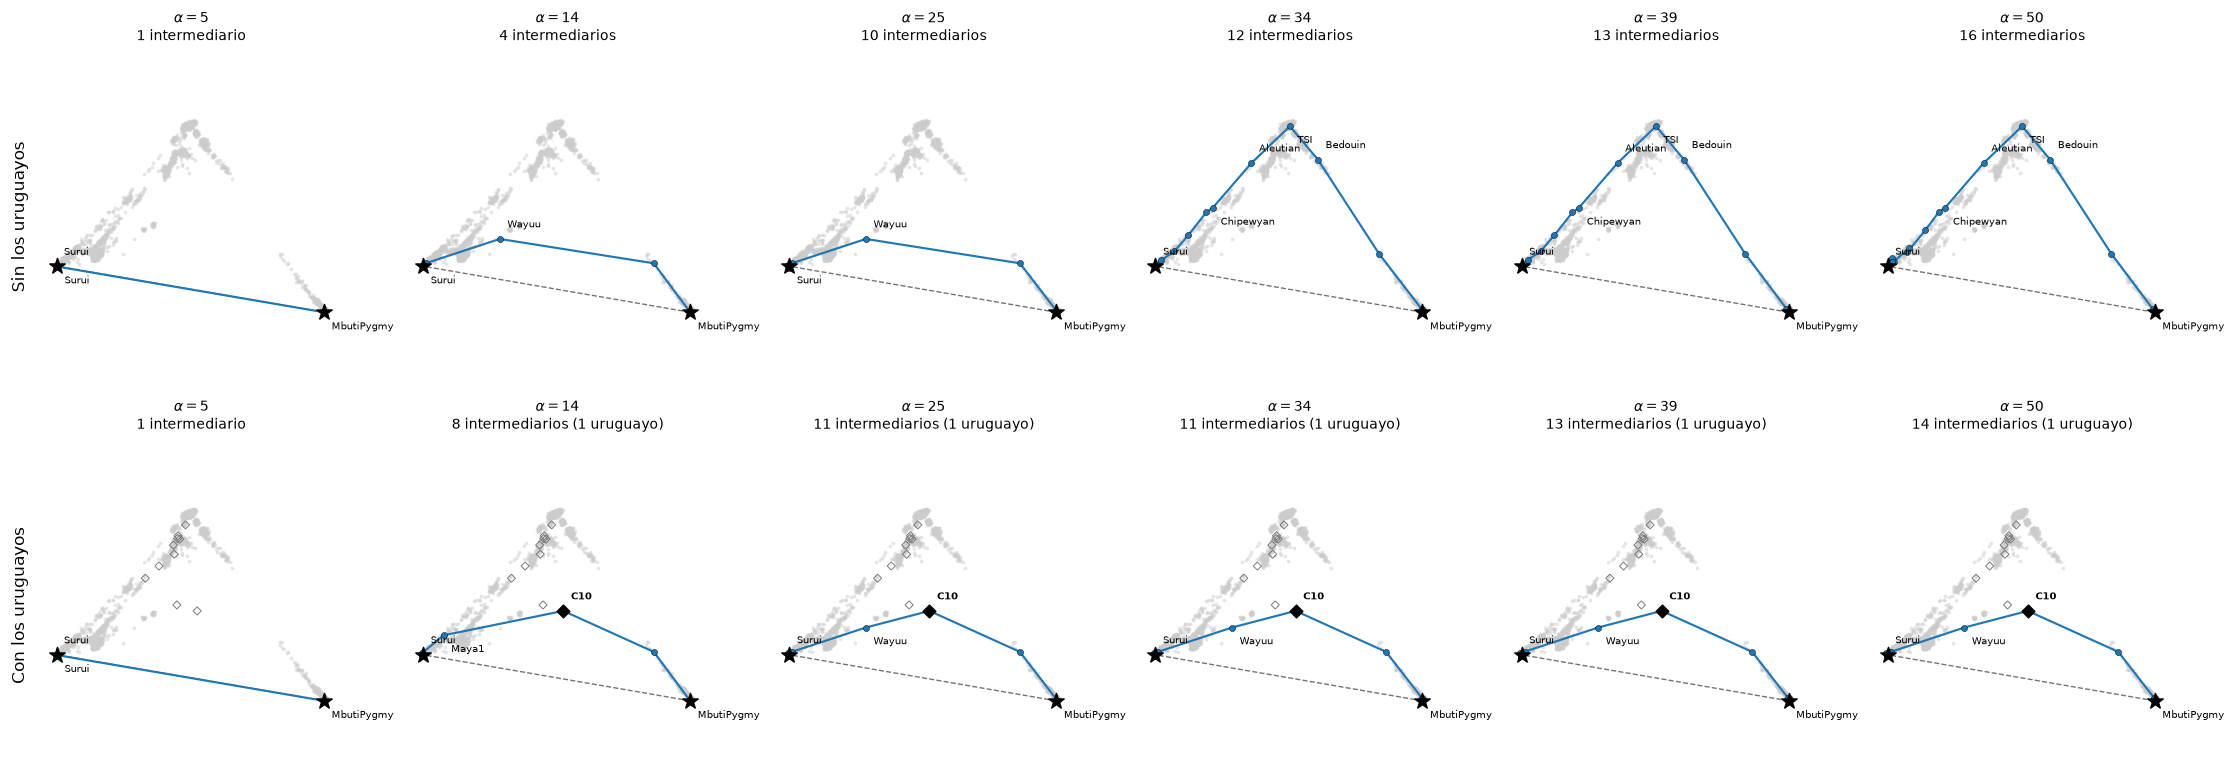

,espacio,alpha,escenario,intermediarios,uruguayos,cociente,regiones
0,Genotipos,5.0,Sin los uruguayos,1,0,0.975,África central y austral → Nativos americanos
1,Genotipos,5.0,Con los uruguayos,1,0,0.975,África central y austral → Nativos americanos
2,Genotipos,14.0,Sin los uruguayos,4,0,0.273,África central y austral → Nativos americanos
3,Genotipos,14.0,Con los uruguayos,8,1,0.266,África central y austral → Uruguayos → Nativos...
4,Genotipos,25.0,Sin los uruguayos,10,0,0.045,África central y austral → Nativos americanos
5,Genotipos,25.0,Con los uruguayos,11,1,0.035,África central y austral → Uruguayos → Nativos...
6,Genotipos,34.0,Sin los uruguayos,12,0,0.009,África central y austral → Medio Oriente → Eur...
7,Genotipos,34.0,Con los uruguayos,11,1,0.006,África central y austral → Uruguayos → Nativos...
8,Genotipos,39.0,Sin los uruguayos,13,0,0.004,África central y austral → Medio Oriente → Eur...
9,Genotipos,39.0,Con los uruguayos,13,1,0.002,África central y austral → Uruguayos → Nativos...


In [54]:
registros = []
for nombre, espacio_sin, espacio_con, alphas in [
        ("Genotipos", ESPACIO_REF, ESPACIO_GEN_C10, [5., 14., 25., 34., 39., 50.])]:
    fig, axes = plt.subplots(2, len(alphas), figsize=(3.4*len(alphas), 7.2), squeeze=False)
    for col, alpha in enumerate(alphas):
        for fila, (escenario, espacio) in enumerate((("Sin los uruguayos", espacio_sin),
                                                     ("Con los uruguayos", espacio_con))):
            ruta, costo, directo = camino_un_par(espacio, alpha, i_par, j_par)
            n_uru = sum(v >= nr for v in ruta[1:-1])
            registros.append({"espacio": nombre, "alpha": alpha, "escenario": escenario,
                              "intermediarios": len(ruta)-2, "uruguayos": n_uru,
                              "cociente": costo/directo,
                              "regiones": " → ".join(dict.fromkeys(regiones_nodos[ruta])),
                              "recorrido": " → ".join(etiquetas_nodos[ruta])})
            ax = axes[fila, col]
            dibujar_camino(ax, ruta, fila == 1)
            texto = f"{len(ruta)-2} intermediarios" if len(ruta) > 3 else \
                    ("1 intermediario" if len(ruta) == 3 else "arista directa")
            if n_uru:
                texto += f" ({n_uru} uruguayo{'s' if n_uru > 1 else ''})"
            ax.set_title(texto_alpha(alpha) + "\n" + texto, fontsize=9)
        axes[0, 0].set_ylabel("Sin los uruguayos", fontsize=11, labelpad=10)
        axes[1, 0].set_ylabel("Con los uruguayos", fontsize=11, labelpad=10)
    fig.tight_layout()
    guardar_figura(fig, f"U2_evolucion_camino_{nombre}")

EVOLUCION_GEN = tabla(pd.DataFrame(registros), "U2_evolucion_camino_genotipos")
display(EVOLUCION_GEN[["espacio", "alpha", "escenario", "intermediarios", "uruguayos",
                   "cociente", "regiones"]].round(3))

Q_NN_pob        Q_NN_reg         Q_FST        MAE_ADM_pp          \
metodo       DM    MDS       DM    MDS     DM    MDS         DM     MDS   
alpha                                                                     
1.0       0.483  0.490    0.948  0.952  0.692  0.704      4.629   4.262   
6.0       0.487  0.489    0.939  0.942  0.701  0.703      4.854   4.499   
10.0      0.431  0.431    0.915  0.913  0.681  0.675      8.070   7.901   
16.0      0.426  0.418    0.907  0.903  0.703  0.666      9.154   9.023   
20.0      0.448  0.442    0.930  0.906  0.766  0.816     10.508   9.448   
32.0      0.444  0.440    0.925  0.922  0.765  0.795     14.843  14.077   

       C_fuera_triangulo       
metodo                DM  MDS  
alpha                          
1.0                  0.0  0.0  
6.0                  0.0  0.0  
10.0                 6.0  8.0  
16.0                 1.0  1.0  
20.0                 2.0  1.0  
32.0                 4.0  4.0

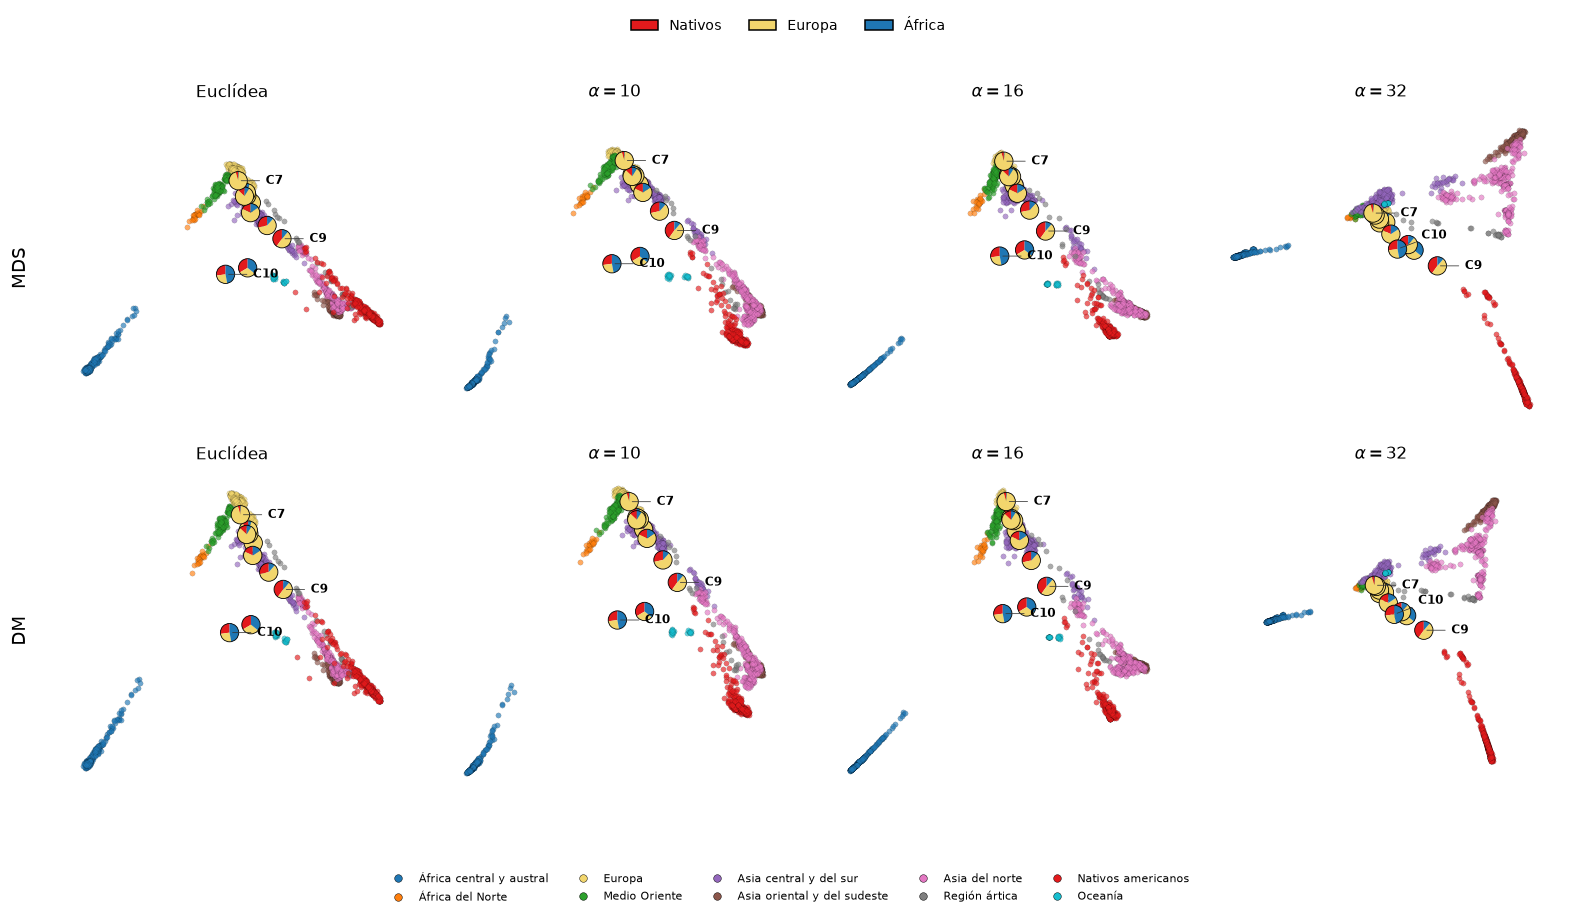

In [55]:
# Comparación complementaria sobre los genotipos originales (sin PCA).
ALPHAS_GEN_C10 = [1., 6., 10., 16., 20., 32.]
ruta_gen = TABLAS/"U3_genotipos_con_C10.csv"
filas = pd.read_csv(ruta_gen).to_dict("records") if ruta_gen.exists() else []
listos = {(r["metodo"], round(float(r["alpha"]), 6)) for r in filas}
for alpha in ALPHAS_GEN_C10:
    for metodo, Z in mapas_fermat(ESPACIO_GEN_C10, alpha).items():
        if (metodo, round(alpha, 6)) not in listos:
            anc, _, _ = evaluar_ancestria(Z)
            filas.append({"alpha": alpha, "metodo": metodo,
                          **evaluar_mapa(Z, CTX_C10), **anc})
    tabla(pd.DataFrame(filas), "U3_genotipos_con_C10")
MET_GEN_C10 = pd.DataFrame(filas).sort_values(["metodo", "alpha"])
columnas = ["Q_NN_pob", "Q_NN_reg", "Q_FST", "MAE_ADM_pp", "C_fuera_triangulo"]
display(MET_GEN_C10.pivot(index="alpha", columns="metodo", values=columnas).round(3))

ALPHAS_GAL_GEN_C10 = [1., 10., 16., 32.]
mapas = {(metodo, a): mapas_fermat(ESPACIO_GEN_C10, a)[metodo]
         for a in ALPHAS_GAL_GEN_C10 for metodo in ("MDS", "DM")}
galeria_tesis(mapas, ALPHAS_GAL_GEN_C10, "U3_galeria_genotipos_C10", reg, ids_c=C, pies=True)

In [56]:
# Cuadro C.2: Q_NN por población, Q_FST y error de ancestría
sin = MET_REF[MET_REF.alpha.isin(ALPHAS_GEN_C10)].copy()
sin["escenario"] = "Sin los uruguayos"
con = MET_GEN_C10.copy()
con["escenario"] = "Con los uruguayos"
CUADRO_C2 = tabla(pd.concat([sin, con], ignore_index=True)[[
    "alpha", "metodo", "escenario", "Q_NN_pob", "Q_FST", "MAE_ADM_pp"]],
    "C2_metricas_genotipos")
display(CUADRO_C2.pivot(index=["alpha", "metodo"], columns="escenario",
                         values=["Q_NN_pob", "Q_FST", "MAE_ADM_pp"]).round(3))

Q_NN_pob                               Q_FST  \
escenario    Con los uruguayos Sin los uruguayos Con los uruguayos   
alpha metodo                                                         
1.0   DM                 0.483             0.482             0.692   
      MDS                0.490             0.488             0.704   
6.0   DM                 0.487             0.487             0.701   
      MDS                0.489             0.487             0.703   
10.0  DM                 0.431             0.459             0.681   
      MDS                0.431             0.460             0.675   
16.0  DM                 0.426             0.435             0.703   
      MDS                0.418             0.435             0.666   
20.0  DM                 0.448             0.440             0.766   
      MDS                0.442             0.444             0.816   
32.0  DM                 0.444             0.440             0.765   
      MDS                0.440             0.438             0.795   

                                      MAE_ADM_pp                    
escenario    Sin los uruguayos Con los uruguayos Sin los uruguayos  
alpha metodo                                                        
1.0   DM                 0.693             4.629               NaN  
      MDS                0.705             4.262               NaN  
6.0   DM                 0.703             4.854               NaN  
      MDS                0.705             4.499               NaN  
10.0  DM                 0.714             8.070               NaN  
      MDS                0.708             7.901               NaN  
16.0  DM                 0.695             9.154               NaN  
      MDS                0.671             9.023               NaN  
20.0  DM                 0.810            10.508               NaN  
      MDS                0.838             9.448               NaN  
32.0  DM                 0.791            14.843               NaN  
      MDS                0.816            14.077               NaN

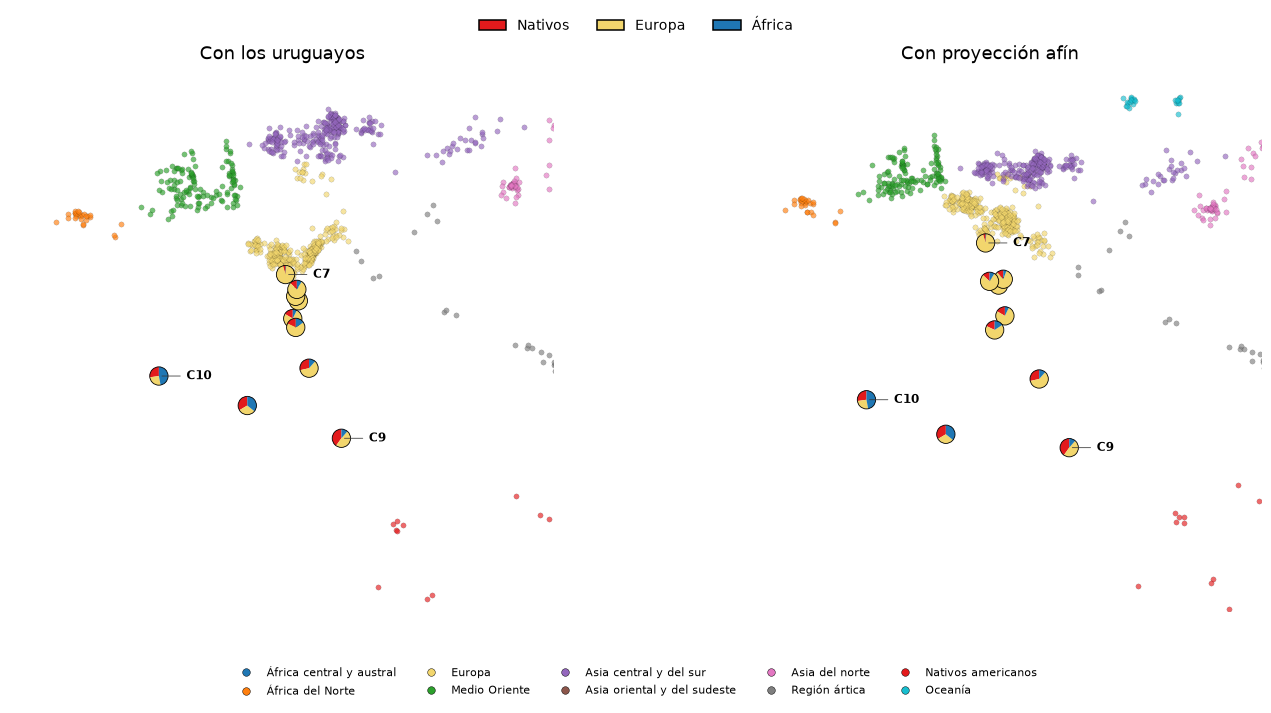

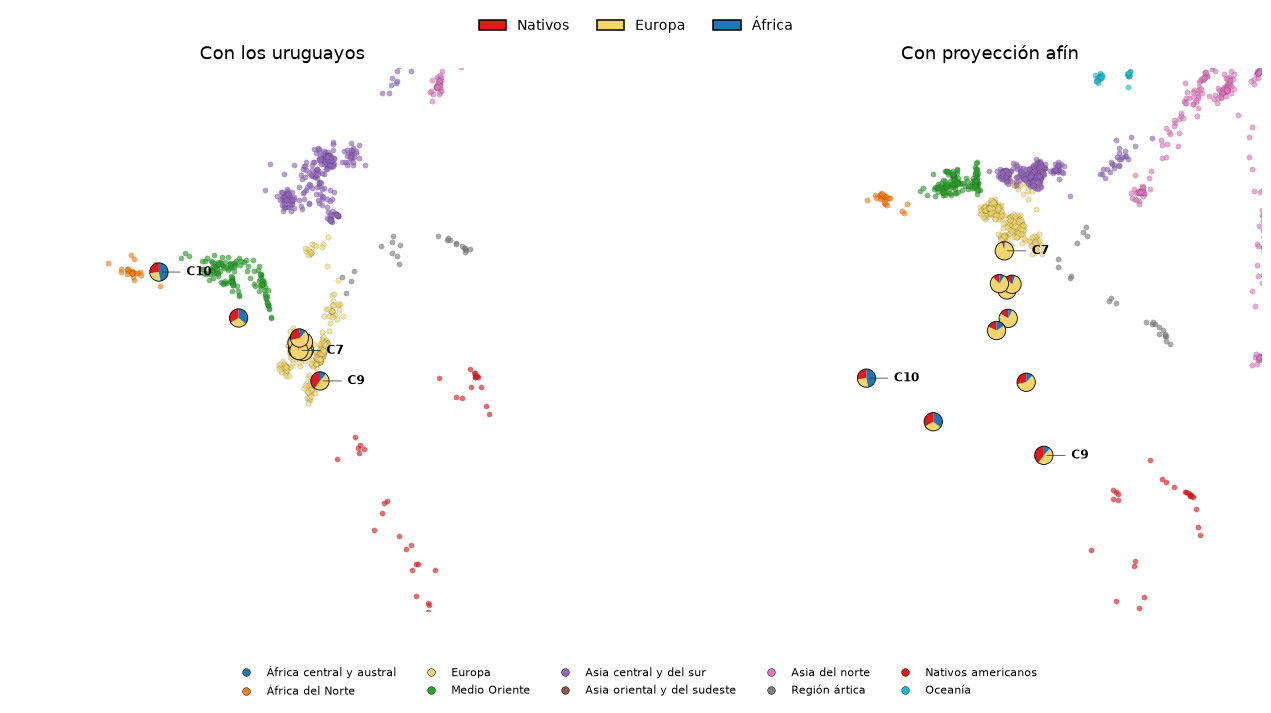

In [57]:
# Apéndice C.4: zooms de los diez uruguayos, MDS y mapas de difusión.
# Sólo visualización; no se recalculan distancias ni representaciones.

def zoom_uruguayos(metodo, escenario, ax, margen=2.2):
    Z = MAPAS_PRINCIPALES[(metodo, escenario)]
    if escenario == "Con los diez":
        Z = alinear_por_referencias(Z, MAPAS_PRINCIPALES[(metodo, "Sin los diez")])
    con_C = len(Z) == n
    nube(ax, Z, reg if con_C else reg[:nr], "",
         ids_c=C if con_C else None, pies=con_C, ejes=("", ""))
    P = Z[C]
    centro = P.mean(0)
    radio = margen * np.abs(P - centro).max()
    ax.set_xlim(centro[0] - radio, centro[0] + radio)
    ax.set_ylim(centro[1] - radio, centro[1] + radio)
    ax.set_aspect("equal", adjustable="box")
    sin_ejes(ax)
    return ax


ESCENARIOS_ZOOM = ("Con los diez", "Proyección afín")
for metodo in ("MDS", "DM"):
    fig, axes = plt.subplots(1, len(ESCENARIOS_ZOOM),
                             figsize=(6.5*len(ESCENARIOS_ZOOM), 6.5), squeeze=False)
    for ax, escenario in zip(axes[0], ESCENARIOS_ZOOM):
        zoom_uruguayos(metodo, escenario, ax)
        ax.set_title(ETIQUETA_ESCENARIO[escenario].capitalize(), fontsize=12)
    leyenda_regiones(fig, reg, pies=True)
    guardar_figura(fig, f"U4_zoom_uruguayos_{metodo}")
